# A Comparative Analysis of Machine Learning Models for Customer Churn Prediction Among Banking Credit Card Customers

**Name:** Sharon Mandru

## 1. Research Context

### 1.1 Research Aim

This analysis aims to evaluate and compare Logistic Regression, LASSO-regularised Logistic Regression, Decision Tree and Random Forest for classifying customer churn among banking credit-card customers. It also aims to identify the customer characteristics most strongly associated with predicted churn and to compare the fitted models in terms of predictive performance, complexity and understandability.

### 1.2 Research Questions

1. What customer characteristics are most strongly associated with predicted customer churn?
2. How do Logistic Regression, LASSO-regularised Logistic Regression, Decision Tree and Random Forest compare across multiple predictive-performance measures?
3. Which model provides the most appropriate balance between predictive performance, fitted-model complexity and understandability?
4. How can the analytical findings support evidence-informed customer-retention strategies?


### 1.3 Analytical Framework

The analysis follows a reproducible quantitative classification workflow:

1. Environment and reproducibility setup
2. Data loading and initial integrity verification
3. Identification and removal of customer identifiers and pre-existing model outputs
4. Predictor-timing assessment
5. Descriptive statistics, exploratory data analysis and data-quality treatment decisions
6. Stratified training and test-set separation
7. Fold-specific preprocessing within model pipelines
8. Class-imbalance assessment and baseline evaluation
9. Model development and hyperparameter tuning
10. Cross-validation using multiple performance measures
11. Final held-out test evaluation and classification-error analysis
12. Predictor analysis and fitted-model understandability assessment
13. Probability calibration, business implications, limitations and conclusions

Preprocessing estimation, class-weight selection and hyperparameter tuning are performed using the training partition only. During cross-validation, scaling and categorical encoding are fitted separately within each training fold through model pipelines. The test partition is not used to fit preprocessing transformations, select model configurations or optimise the classification threshold; it is used once for final model evaluation.

Outcome-based descriptive analysis was conducted on the complete analytical dataset before partitioning. Consequently, the eventual test observations contributed to the descriptive exploration, although they did not influence the fitted preprocessing parameters or model-selection procedures. The test set should therefore be described as held out from model development rather than entirely unseen throughout the complete analytical workflow.

The pipeline procedure controls information leakage arising from fitted preprocessing and model selection. However, the dataset does not clearly document when every predictor was measured relative to customer attrition. Temporal leakage therefore cannot be ruled out. This issue is assessed separately, and the analysis is interpreted as retrospective cross-sectional classification rather than a validated prospective churn-forecasting system.

In [1]:
# System and software environment
import platform
import sklearn
import matplotlib

# Core data analysis
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

# Consistent figure styling
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print("Environment setup completed successfully.")
print(f"Python version: {platform.python_version()}")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")
print(f"Matplotlib version: {matplotlib.__version__}")
print(f"Seaborn version: {sns.__version__}")
print(f"Random state: {RANDOM_STATE}")

Environment setup completed successfully.
Python version: 3.13.9
Pandas version: 2.3.3
NumPy version: 2.3.5
Scikit-learn version: 1.7.2
Matplotlib version: 3.10.6
Seaborn version: 0.13.2
Random state: 42


## 2. Data Loading and Initial Integrity Assessment

This section loads the original dataset and examines its structure before any cleaning, preprocessing or modelling. The initial assessment covers:

* dataset dimensions and column names;
* variable types and unique values;
* duplicate observations and repeated customer identifiers;
* conventional missing values and explicitly coded `Unknown` values;
* target-class distribution;
* customer identifiers and pre-existing model outputs; and
* the timing of candidate predictors relative to customer attrition.

The imported dataset is preserved as `df_raw`. A separate analytical copy is created after excluding variables that are unsuitable for modelling. This preserves the original data and makes every exclusion and treatment decision transparent.


In [2]:
# Load the original dataset
DATA_PATH = "BankChurners.csv"

df_raw = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Number of observations: {df_raw.shape[0]:,}")
print(f"Number of variables: {df_raw.shape[1]}")

Dataset loaded successfully.
Number of observations: 10,127
Number of variables: 23


In [3]:
# Create a structured overview of the original variables
column_overview = pd.DataFrame({
    "Variable": df_raw.columns,
    "Data_Type": df_raw.dtypes.astype(str).values,
    "Non_Null_Count": df_raw.notna().sum().values,
    "Missing_Count": df_raw.isna().sum().values,
    "Missing_Percentage": (
        df_raw.isna().mean().mul(100).round(2).values
    ),
    "Unique_Values": df_raw.nunique(dropna=False).values
})

display(column_overview)

,Variable,Data_Type,Non_Null_Count,Missing_Count,Missing_Percentage,Unique_Values
0,CLIENTNUM,int64,10127,0,0.000,10127
1,Attrition_Flag,object,10127,0,0.000,2
2,Customer_Age,int64,10127,0,0.000,45
3,Gender,object,10127,0,0.000,2
4,Dependent_count,int64,10127,0,0.000,6
5,Education_Level,object,10127,0,0.000,7
6,Marital_Status,object,10127,0,0.000,4
7,Income_Category,object,10127,0,0.000,6
8,Card_Category,object,10127,0,0.000,4
9,Months_on_book,int64,10127,0,0.000,44


In [4]:
# Assess complete row duplicates and repeated customer identifiers
duplicate_rows = df_raw.duplicated().sum()
duplicate_customer_ids = df_raw["CLIENTNUM"].duplicated().sum()

print("Duplicate assessment")
print("-" * 40)
print(f"Completely duplicated rows: {duplicate_rows:,}")
print(f"Duplicated customer identifiers: {duplicate_customer_ids:,}")

Duplicate assessment
----------------------------------------
Completely duplicated rows: 0
Duplicated customer identifiers: 0


In [5]:
# Identify explicitly coded "Unknown" values in categorical variables
original_categorical_columns = (
    df_raw.select_dtypes(include="object")
    .columns
    .tolist()
)

unknown_records = []

for column in original_categorical_columns:
    unknown_count = (
        df_raw[column]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("unknown")
        .sum()
    )

    unknown_records.append({
        "Variable": column,
        "Unknown_Count": unknown_count,
        "Unknown_Percentage": round(
            unknown_count / len(df_raw) * 100,
            2
        )
    })

unknown_summary = (
    pd.DataFrame(unknown_records)
    .query("Unknown_Count > 0")
    .sort_values("Unknown_Count", ascending=False)
    .reset_index(drop=True)
)

display(unknown_summary)

,Variable,Unknown_Count,Unknown_Percentage
0,Education_Level,1519,15.000
1,Income_Category,1112,10.980
2,Marital_Status,749,7.400


In [6]:
# Examine the target-variable labels and class distribution
target_counts = (
    df_raw["Attrition_Flag"]
    .value_counts(dropna=False)
    .rename_axis("Customer_Status")
    .reset_index(name="Count")
)

target_counts["Percentage"] = (
    target_counts["Count"] / len(df_raw) * 100
).round(2)

display(target_counts)

existing_count = (
    df_raw["Attrition_Flag"] == "Existing Customer"
).sum()

attrited_count = (
    df_raw["Attrition_Flag"] == "Attrited Customer"
).sum()

imbalance_ratio = existing_count / attrited_count

print(f"Existing customers: {existing_count:,}")
print(f"Attrited customers: {attrited_count:,}")
print(f"Observed churn rate: {attrited_count / len(df_raw) * 100:.2f}%")
print(f"Class imbalance ratio: {imbalance_ratio:.2f}:1")

,Customer_Status,Count,Percentage
0,Existing Customer,8500,83.930
1,Attrited Customer,1627,16.070


Existing customers: 8,500
Attrited customers: 1,627
Observed churn rate: 16.07%
Class imbalance ratio: 5.22:1


In [7]:
# Identify the customer identifier
identifier_columns = ["CLIENTNUM"]

# Identify probability outputs from the pre-existing Naive Bayes model
naive_bayes_columns = [
    column
    for column in df_raw.columns
    if "Naive_Bayes_Classifier" in column
]

print("Columns excluded from modelling")
print("-" * 50)

print("Customer identifier:")
for column in identifier_columns:
    print(f"- {column}")

print("\nPre-existing model-output columns:")
for column in naive_bayes_columns:
    print(f"- {column}")

print(
    f"\nTotal columns identified for exclusion: "
    f"{len(identifier_columns) + len(naive_bayes_columns)}"
)

Columns excluded from modelling
--------------------------------------------------
Customer identifier:
- CLIENTNUM

Pre-existing model-output columns:
- Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1
- Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2

Total columns identified for exclusion: 3


In [8]:
# Combine all columns identified for exclusion
columns_to_remove = identifier_columns + naive_bayes_columns

# Create a separate analytical copy
df = df_raw.drop(columns=columns_to_remove).copy()

print("Analytical dataset created successfully.")
print("-" * 55)
print(
    f"Original dataset:   "
    f"{df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns"
)
print(
    f"Analytical dataset: "
    f"{df.shape[0]:,} rows × {df.shape[1]} columns"
)
print(f"Columns removed:    {len(columns_to_remove)}")
print(f"Customer observations removed: {len(df_raw) - len(df)}")

Analytical dataset created successfully.
-------------------------------------------------------
Original dataset:   10,127 rows × 23 columns
Analytical dataset: 10,127 rows × 20 columns
Columns removed:    3
Customer observations removed: 0


### 2.1 Initial Data-Integrity Findings

The original dataset contained 10,127 customer observations and 23 variables. No completely duplicated records, repeated customer identifiers or pandas-recognised null values were detected. However, the absence of conventional null values did not mean that all customer information was complete. `Education_Level`, `Marital_Status` and `Income_Category` contained observations labelled as `Unknown`. These values were therefore identified as explicitly coded unavailable information requiring separate assessment.

The target variable, `Attrition_Flag`, contained 8,500 existing customers and 1,627 attrited customers. Attrited customers represented 16.07% of the sample, producing a majority-to-minority ratio of approximately 5.22:1. This imbalance means that accuracy alone would provide an incomplete assessment of model performance because a classifier could obtain high accuracy by favouring existing customers while failing to identify attrited customers.

Three variables were excluded from the analytical dataset. `CLIENTNUM` was removed because it is a unique customer identifier without substantive predictive meaning. The two variables beginning with `Naive_Bayes_Classifier` were removed because they contain outputs from a pre-existing classifier fitted to the same attrition outcome. Including these variables could create direct target leakage and produce misleadingly optimistic performance estimates.

After these exclusions, the analytical dataset contained 19 candidate predictors and one target variable. No customer observations were removed at this stage.


### 2.2 Predictor-Timing Assessment

A prospective churn model should use only information that would be available before customer attrition occurs. If a variable was measured during or after attrition, including it could introduce temporal leakage and produce an unrealistically favourable estimate of predictive performance.

The dataset contains one observation per customer and does not provide observation dates, attrition dates or a clearly defined prediction date. Some variable names indicate snapshot information, preceding twelve-month activity or quarterly changes. However, the available dataset documentation does not establish whether these measurement periods ended before the attrition outcome was recorded.

Each of the 19 candidate predictors is therefore assessed according to:

1. the information represented by the variable;
2. the measurement window suggested by its name;
3. whether measurement before churn can be confirmed; and
4. the resulting modelling and interpretation decision.

This assessment cannot prove that the retained predictors were measured after churn. It establishes that their timing cannot be verified from the supplied cross-sectional data.


In [9]:
# Create a transparent timing assessment for all candidate predictors
timing_audit = pd.DataFrame({
    "Variable": [
        "Customer_Age",
        "Gender",
        "Dependent_count",
        "Education_Level",
        "Marital_Status",
        "Income_Category",
        "Card_Category",
        "Months_on_book",
        "Total_Relationship_Count",
        "Months_Inactive_12_mon",
        "Contacts_Count_12_mon",
        "Credit_Limit",
        "Total_Revolving_Bal",
        "Avg_Open_To_Buy",
        "Total_Amt_Chng_Q4_Q1",
        "Total_Trans_Amt",
        "Total_Trans_Ct",
        "Total_Ct_Chng_Q4_Q1",
        "Avg_Utilization_Ratio"
    ],
    "Information_Represented": [
        "Customer age",
        "Customer gender",
        "Number of dependants",
        "Recorded education category",
        "Recorded marital-status category",
        "Recorded income category",
        "Credit-card category",
        "Length of relationship with the bank",
        "Number of banking products held",
        "Inactive months within a 12-month period",
        "Bank contacts within a 12-month period",
        "Available credit limit",
        "Revolving credit balance",
        "Average unused credit",
        "Change in transaction amount between Q4 and Q1",
        "Total transaction amount",
        "Total transaction count",
        "Change in transaction count between Q4 and Q1",
        "Average credit-utilisation ratio"
    ],
    "Measurement_Window_Indicated": [
        "Customer snapshot",
        "Customer snapshot",
        "Customer snapshot",
        "Customer snapshot",
        "Customer snapshot",
        "Customer snapshot",
        "Account snapshot",
        "Accumulated duration at observation",
        "Account snapshot",
        "Previous 12 months",
        "Previous 12 months",
        "Account snapshot",
        "Account snapshot",
        "Account snapshot",
        "Quarterly comparison",
        "Previous 12 months",
        "Previous 12 months",
        "Quarterly comparison",
        "Account snapshot"
    ],
    "Pre_Churn_Timing_Status": [
        "Not documented"
    ] * 19,
    "Analytical_Decision": [
        "Retain for retrospective classification; "
        "do not claim confirmed pre-churn availability"
    ] * 19
})

display(timing_audit)

# Save the timing assessment as a new analytical table
timing_audit.to_csv(
    "table_predictor_timing_assessment.csv",
    index=False
)

print(
    "Predictor-timing assessment saved as "
    "'table_predictor_timing_assessment.csv'."
)

,Variable,Information_Represented,Measurement_Window_Indicated,Pre_Churn_Timing_Status,Analytical_Decision
0,Customer_Age,Customer age,Customer snapshot,Not documented,Retain for retrospective classification; do no...
1,Gender,Customer gender,Customer snapshot,Not documented,Retain for retrospective classification; do no...
2,Dependent_count,Number of dependants,Customer snapshot,Not documented,Retain for retrospective classification; do no...
3,Education_Level,Recorded education category,Customer snapshot,Not documented,Retain for retrospective classification; do no...
4,Marital_Status,Recorded marital-status category,Customer snapshot,Not documented,Retain for retrospective classification; do no...
5,Income_Category,Recorded income category,Customer snapshot,Not documented,Retain for retrospective classification; do no...
6,Card_Category,Credit-card category,Account snapshot,Not documented,Retain for retrospective classification; do no...
7,Months_on_book,Length of relationship with the bank,Accumulated duration at observation,Not documented,Retain for retrospective classification; do no...
8,Total_Relationship_Count,Number of banking products held,Account snapshot,Not documented,Retain for retrospective classification; do no...
9,Months_Inactive_12_mon,Inactive months within a 12-month period,Previous 12 months,Not documented,Retain for retrospective classification; do no...


Predictor-timing assessment saved as 'table_predictor_timing_assessment.csv'.


#### Predictor-Timing Findings

The timing assessment found that the available documentation does not confirm whether any of the 19 candidate predictors were measured before customer attrition. Some variables describe customer or account information at a single observation point, while others summarise activity over twelve months or compare transaction activity between two quarters. However, the dataset does not provide the observation date, attrition date or prediction reference date needed to establish the temporal order of these measurements.

The predictors are retained because the study evaluates the retrospective classification of customers within the supplied dataset. Their inclusion should not be interpreted as evidence that all variables would have been available before churn in a prospective banking application. Accordingly, reported model performance describes the ability to distinguish existing and attrited customers in this cross-sectional sample, rather than a verified ability to forecast future attrition.

This limitation also affects the business interpretation. Behavioural variables may be described as being associated with attrition, but they should not be presented as confirmed early-warning indicators unless their timing is validated using longitudinal data.


## 3. Descriptive Statistics and Exploratory Data Analysis

Exploratory data analysis is conducted before preprocessing and model development to examine the composition, distribution and quality of the analytical dataset. This section includes:

* numerical descriptive statistics and skewness;
* target-class distribution and class imbalance;
* numerical distributions and boxplots by churn status;
* categorical frequencies and attrition rates;
* uncertainty for categorical attrition rates;
* correlation and multicollinearity assessment;
* potential outlier and plausibility checks;
* assessment of explicitly coded `Unknown` categories; and
* a summary of the main exploratory findings.

The analysis uses the analytical dataset after removing the customer identifier and the two pre-existing Naive Bayes model-output variables. No scaling, categorical encoding, resampling, feature expansion or model fitting is performed during this exploratory stage.

The results describe patterns and associations within the supplied cross-sectional sample. Differences between existing and attrited customers should not be interpreted as causal effects or as confirmed pre-churn relationships.


In [10]:
# Define the target variable
TARGET = "Attrition_Flag"

# Identify numerical and categorical predictors
numeric_columns = (
    df.select_dtypes(include=np.number)
    .columns
    .tolist()
)

categorical_columns = [
    column
    for column in df.select_dtypes(include="object").columns
    if column != TARGET
]

predictor_columns = numeric_columns + categorical_columns

# Confirm that the timing audit covers every candidate predictor
timing_audit_complete = (
    set(predictor_columns)
    == set(timing_audit["Variable"])
)

print("Analytical-variable summary")
print("-" * 50)
print(f"Number of numerical predictors: {len(numeric_columns)}")
print(f"Number of categorical predictors: {len(categorical_columns)}")
print(f"Total candidate predictors: {len(predictor_columns)}")
print(f"Timing audit covers all predictors: {timing_audit_complete}")

print("\nNumerical predictors:")
for column in numeric_columns:
    print(f"- {column}")

print("\nCategorical predictors:")
for column in categorical_columns:
    print(f"- {column}")

print(f"\nTarget variable: {TARGET}")

Analytical-variable summary
--------------------------------------------------
Number of numerical predictors: 14
Number of categorical predictors: 5
Total candidate predictors: 19
Timing audit covers all predictors: True

Numerical predictors:
- Customer_Age
- Dependent_count
- Months_on_book
- Total_Relationship_Count
- Months_Inactive_12_mon
- Contacts_Count_12_mon
- Credit_Limit
- Total_Revolving_Bal
- Avg_Open_To_Buy
- Total_Amt_Chng_Q4_Q1
- Total_Trans_Amt
- Total_Trans_Ct
- Total_Ct_Chng_Q4_Q1
- Avg_Utilization_Ratio

Categorical predictors:
- Gender
- Education_Level
- Marital_Status
- Income_Category
- Card_Category

Target variable: Attrition_Flag


### 3.1 Numerical Descriptive Statistics

Summary statistics are calculated for the 14 numerical predictors. The assessment reports the number of observations, mean, standard deviation, minimum, quartiles, median, maximum, interquartile range and skewness.

The mean and median describe central tendency, while the standard deviation and interquartile range describe dispersion. Skewness is included to identify variables with asymmetric distributions that may require careful interpretation during exploratory analysis. Potential outliers are assessed separately rather than being removed solely because they fall beyond a statistical threshold.


In [11]:
# Calculate descriptive statistics for all numerical predictors
numerical_summary = df[numeric_columns].describe().T

numerical_summary = numerical_summary.rename(columns={
    "count": "Count",
    "mean": "Mean",
    "std": "Standard_Deviation",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

numerical_summary["IQR"] = (
    numerical_summary["Q3"] - numerical_summary["Q1"]
)

numerical_summary["Skewness"] = (
    df[numeric_columns].skew()
)

numerical_summary = numerical_summary[
    [
        "Count",
        "Mean",
        "Standard_Deviation",
        "Minimum",
        "Q1",
        "Median",
        "Q3",
        "Maximum",
        "IQR",
        "Skewness"
    ]
].round(3)

display(numerical_summary)

,Count,Mean,Standard_Deviation,Minimum,Q1,Median,Q3,Maximum,IQR,Skewness
Customer_Age,"10,127.000",46.326,8.017,26.000,41.000,46.000,52.000,73.000,11.000,-0.034
Dependent_count,"10,127.000",2.346,1.299,0.000,1.000,2.000,3.000,5.000,2.000,-0.021
Months_on_book,"10,127.000",35.928,7.986,13.000,31.000,36.000,40.000,56.000,9.000,-0.107
Total_Relationship_Count,"10,127.000",3.813,1.554,1.000,3.000,4.000,5.000,6.000,2.000,-0.162
Months_Inactive_12_mon,"10,127.000",2.341,1.011,0.000,2.000,2.000,3.000,6.000,1.000,0.633
Contacts_Count_12_mon,"10,127.000",2.455,1.106,0.000,2.000,2.000,3.000,6.000,1.000,0.011
Credit_Limit,"10,127.000","8,631.954","9,088.777","1,438.300","2,555.000","4,549.000","11,067.500","34,516.000","8,512.500",1.667
Total_Revolving_Bal,"10,127.000","1,162.814",814.987,0.000,359.000,"1,276.000","1,784.000","2,517.000","1,425.000",-0.149
Avg_Open_To_Buy,"10,127.000","7,469.140","9,090.685",3.000,"1,324.500","3,474.000","9,859.000","34,516.000","8,534.500",1.662
Total_Amt_Chng_Q4_Q1,"10,127.000",0.760,0.219,0.000,0.631,0.736,0.859,3.397,0.228,1.732


In [12]:
# Save the numerical descriptive-statistics table
numerical_summary.to_csv(
    "table_numerical_descriptive_statistics.csv",
    index=True,
    index_label="Variable"
)

print(
    "Descriptive-statistics table saved as "
    "'table_numerical_descriptive_statistics.csv'."
)

Descriptive-statistics table saved as 'table_numerical_descriptive_statistics.csv'.


In [13]:
# Assess and classify skewness among numerical predictors
skewness_assessment = numerical_summary[
    ["Mean", "Median", "Skewness"]
].copy()

skewness_assessment["Absolute_Skewness"] = (
    skewness_assessment["Skewness"].abs()
)

skewness_assessment["Skewness_Category"] = pd.cut(
    skewness_assessment["Absolute_Skewness"],
    bins=[-np.inf, 0.5, 1.0, np.inf],
    labels=[
        "Approximately symmetric",
        "Moderately skewed",
        "Highly skewed"
    ]
)

skewness_assessment = (
    skewness_assessment
    .sort_values("Absolute_Skewness", ascending=False)
)

display(skewness_assessment)

,Mean,Median,Skewness,Absolute_Skewness,Skewness_Category
Total_Ct_Chng_Q4_Q1,0.712,0.702,2.064,2.064,Highly skewed
Total_Trans_Amt,"4,404.086","3,899.000",2.041,2.041,Highly skewed
Total_Amt_Chng_Q4_Q1,0.760,0.736,1.732,1.732,Highly skewed
Credit_Limit,"8,631.954","4,549.000",1.667,1.667,Highly skewed
Avg_Open_To_Buy,"7,469.140","3,474.000",1.662,1.662,Highly skewed
Avg_Utilization_Ratio,0.275,0.176,0.718,0.718,Moderately skewed
Months_Inactive_12_mon,2.341,2.000,0.633,0.633,Moderately skewed
Total_Relationship_Count,3.813,4.000,-0.162,0.162,Approximately symmetric
Total_Trans_Ct,64.859,67.000,0.154,0.154,Approximately symmetric
Total_Revolving_Bal,"1,162.814","1,276.000",-0.149,0.149,Approximately symmetric


#### Numerical Descriptive-Statistics Findings

The numerical summary shows considerable variation in customers’ credit and transaction activity. `Credit_Limit` and `Avg_Open_To_Buy` have means substantially above their medians and display strong positive skewness. This indicates that most customers hold comparatively lower values while a smaller group has considerably higher credit availability.

`Total_Trans_Amt`, `Total_Amt_Chng_Q4_Q1` and `Total_Ct_Chng_Q4_Q1` are also strongly positively skewed. These distributions suggest that relatively few customers record much larger transaction values or quarterly changes than the majority of the sample. By comparison, customer age, number of dependants, months on book, relationship count, revolving balance and transaction count are more approximately symmetric.

Distributional asymmetry does not by itself demonstrate a data-quality problem. High credit limits, transaction amounts or activity changes may represent genuine customer behaviour. No observations are removed, capped or transformed at this stage. Potential extreme values are examined later using statistical thresholds, class-specific comparisons and business-plausibility checks before a final treatment decision is made.


### 3.2 Target-Variable Distribution and Class Imbalance

The distribution of `Attrition_Flag` is examined to quantify the prevalence of attrition and determine whether class imbalance may influence model development and evaluation.

When one class is substantially more common, a classifier may favour the majority class and still achieve high overall accuracy. The analysis therefore reports the number and percentage of existing and attrited customers, the majority-to-minority ratio and the accuracy obtainable from predicting the majority class only.

The identified imbalance will be considered during model tuning and evaluation. Model performance will be assessed using accuracy alongside balanced accuracy, precision, recall, F1-score, ROC-AUC, average precision and confusion-matrix error counts.


In [14]:
# Define a consistent order for the target classes
status_order = [
    "Existing Customer",
    "Attrited Customer"
]

# Calculate the target-class distribution
target_distribution = (
    df[TARGET]
    .value_counts()
    .reindex(status_order)
    .rename_axis("Customer_Status")
    .reset_index(name="Count")
)

target_distribution["Percentage"] = (
    target_distribution["Count"] / len(df) * 100
).round(2)

display(target_distribution)

existing_count = target_distribution.loc[
    target_distribution["Customer_Status"] == "Existing Customer",
    "Count"
].iloc[0]

attrited_count = target_distribution.loc[
    target_distribution["Customer_Status"] == "Attrited Customer",
    "Count"
].iloc[0]

imbalance_ratio = existing_count / attrited_count
majority_baseline_accuracy = existing_count / len(df) * 100
overall_churn_rate = attrited_count / len(df) * 100

print(f"Overall churn rate: {overall_churn_rate:.2f}%")
print(f"Majority-to-minority ratio: {imbalance_ratio:.2f}:1")
print(
    "Majority-class baseline accuracy: "
    f"{majority_baseline_accuracy:.2f}%"
)

,Customer_Status,Count,Percentage
0,Existing Customer,8500,83.930
1,Attrited Customer,1627,16.070


Overall churn rate: 16.07%
Majority-to-minority ratio: 5.22:1
Majority-class baseline accuracy: 83.93%


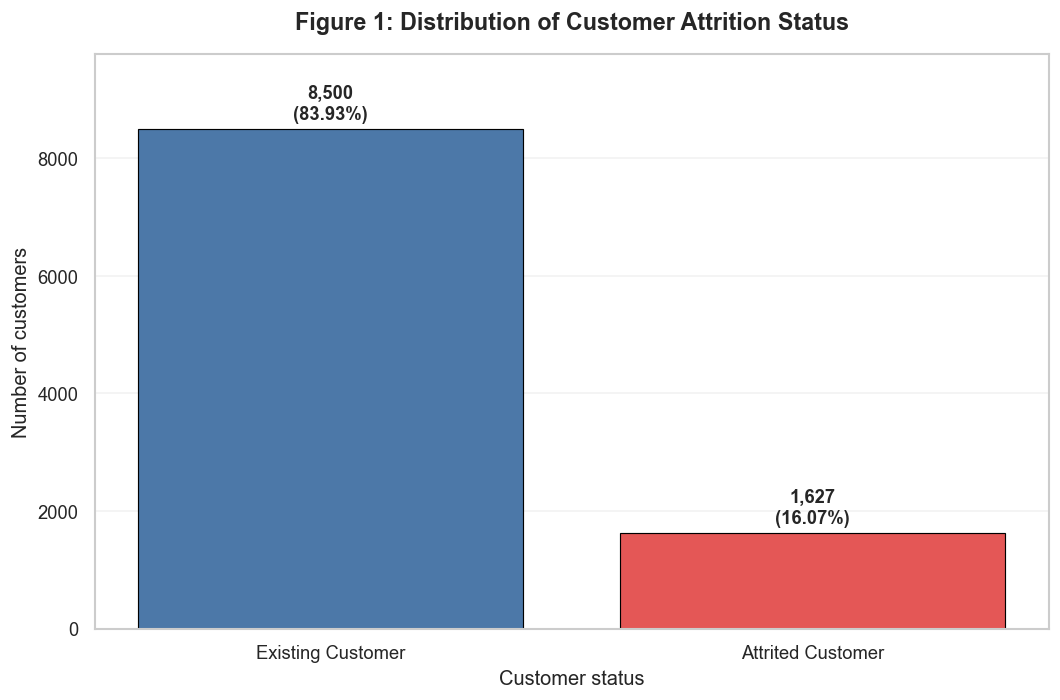

In [15]:
# Define consistent colours for the target classes
status_colours = {
    "Existing Customer": "#4C78A8",
    "Attrited Customer": "#E45756"
}

# Prepare plotting data in the previously defined class order
plot_data = (
    df[TARGET]
    .value_counts()
    .reindex(status_order)
)

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    plot_data.index,
    plot_data.values,
    color=[
        status_colours[status]
        for status in plot_data.index
    ],
    edgecolor="black",
    linewidth=0.7
)

# Add counts and percentages above each bar
for bar, count in zip(bars, plot_data.values):
    percentage = count / len(df) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Figure 1: Distribution of Customer Attrition Status",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Customer status")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, plot_data.max() * 1.15)
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.savefig(
    "figure_1_target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [16]:
# Save the target-distribution table
target_distribution.to_csv(
    "table_target_distribution.csv",
    index=False
)

print("Target-distribution outputs saved successfully:")
print("- table_target_distribution.csv")
print("- figure_1_target_distribution.png")

Target-distribution outputs saved successfully:
- table_target_distribution.csv
- figure_1_target_distribution.png


#### Target-Distribution Findings

The analytical dataset contains 8,500 existing customers and 1,627 attrited customers. Attrited customers represent 16.07% of the sample, producing a majority-to-minority ratio of approximately 5.22:1. The target variable is therefore moderately imbalanced.

A classifier that assigned every observation to the existing-customer class would achieve 83.93% accuracy while identifying no attrited customers. High accuracy alone would therefore not demonstrate useful churn classification. Model evaluation will consider accuracy alongside balanced accuracy, precision, recall, F1-score, ROC-AUC, average precision and confusion-matrix error counts.

The observed class distribution is retained during exploratory analysis and during the held-out test evaluation. Candidate class-weighting strategies will be assessed during cross-validation using the training data only. This prevents information from the held-out test set from influencing the choice of imbalance treatment or model hyperparameters.


### 3.3 Numerical-Variable Distributions by Churn Status

Selected numerical predictors are examined to understand their distributions and their unadjusted associations with customer attrition. Distribution plots are used to compare concentration, spread, skewness and overlap between existing and attrited customers. Boxplots are used to compare medians, interquartile ranges and potential extreme observations.

These comparisons are descriptive and consider one variable at a time. They do not control for the influence of other customer characteristics, interactions or non-linear relationships. They also do not establish causation or confirm that the observed differences occurred before attrition.

The subsequent multivariable models will assess whether these variables contribute predictive information when considered jointly. However, the modelling results will remain subject to the dataset’s predictor-timing limitation.


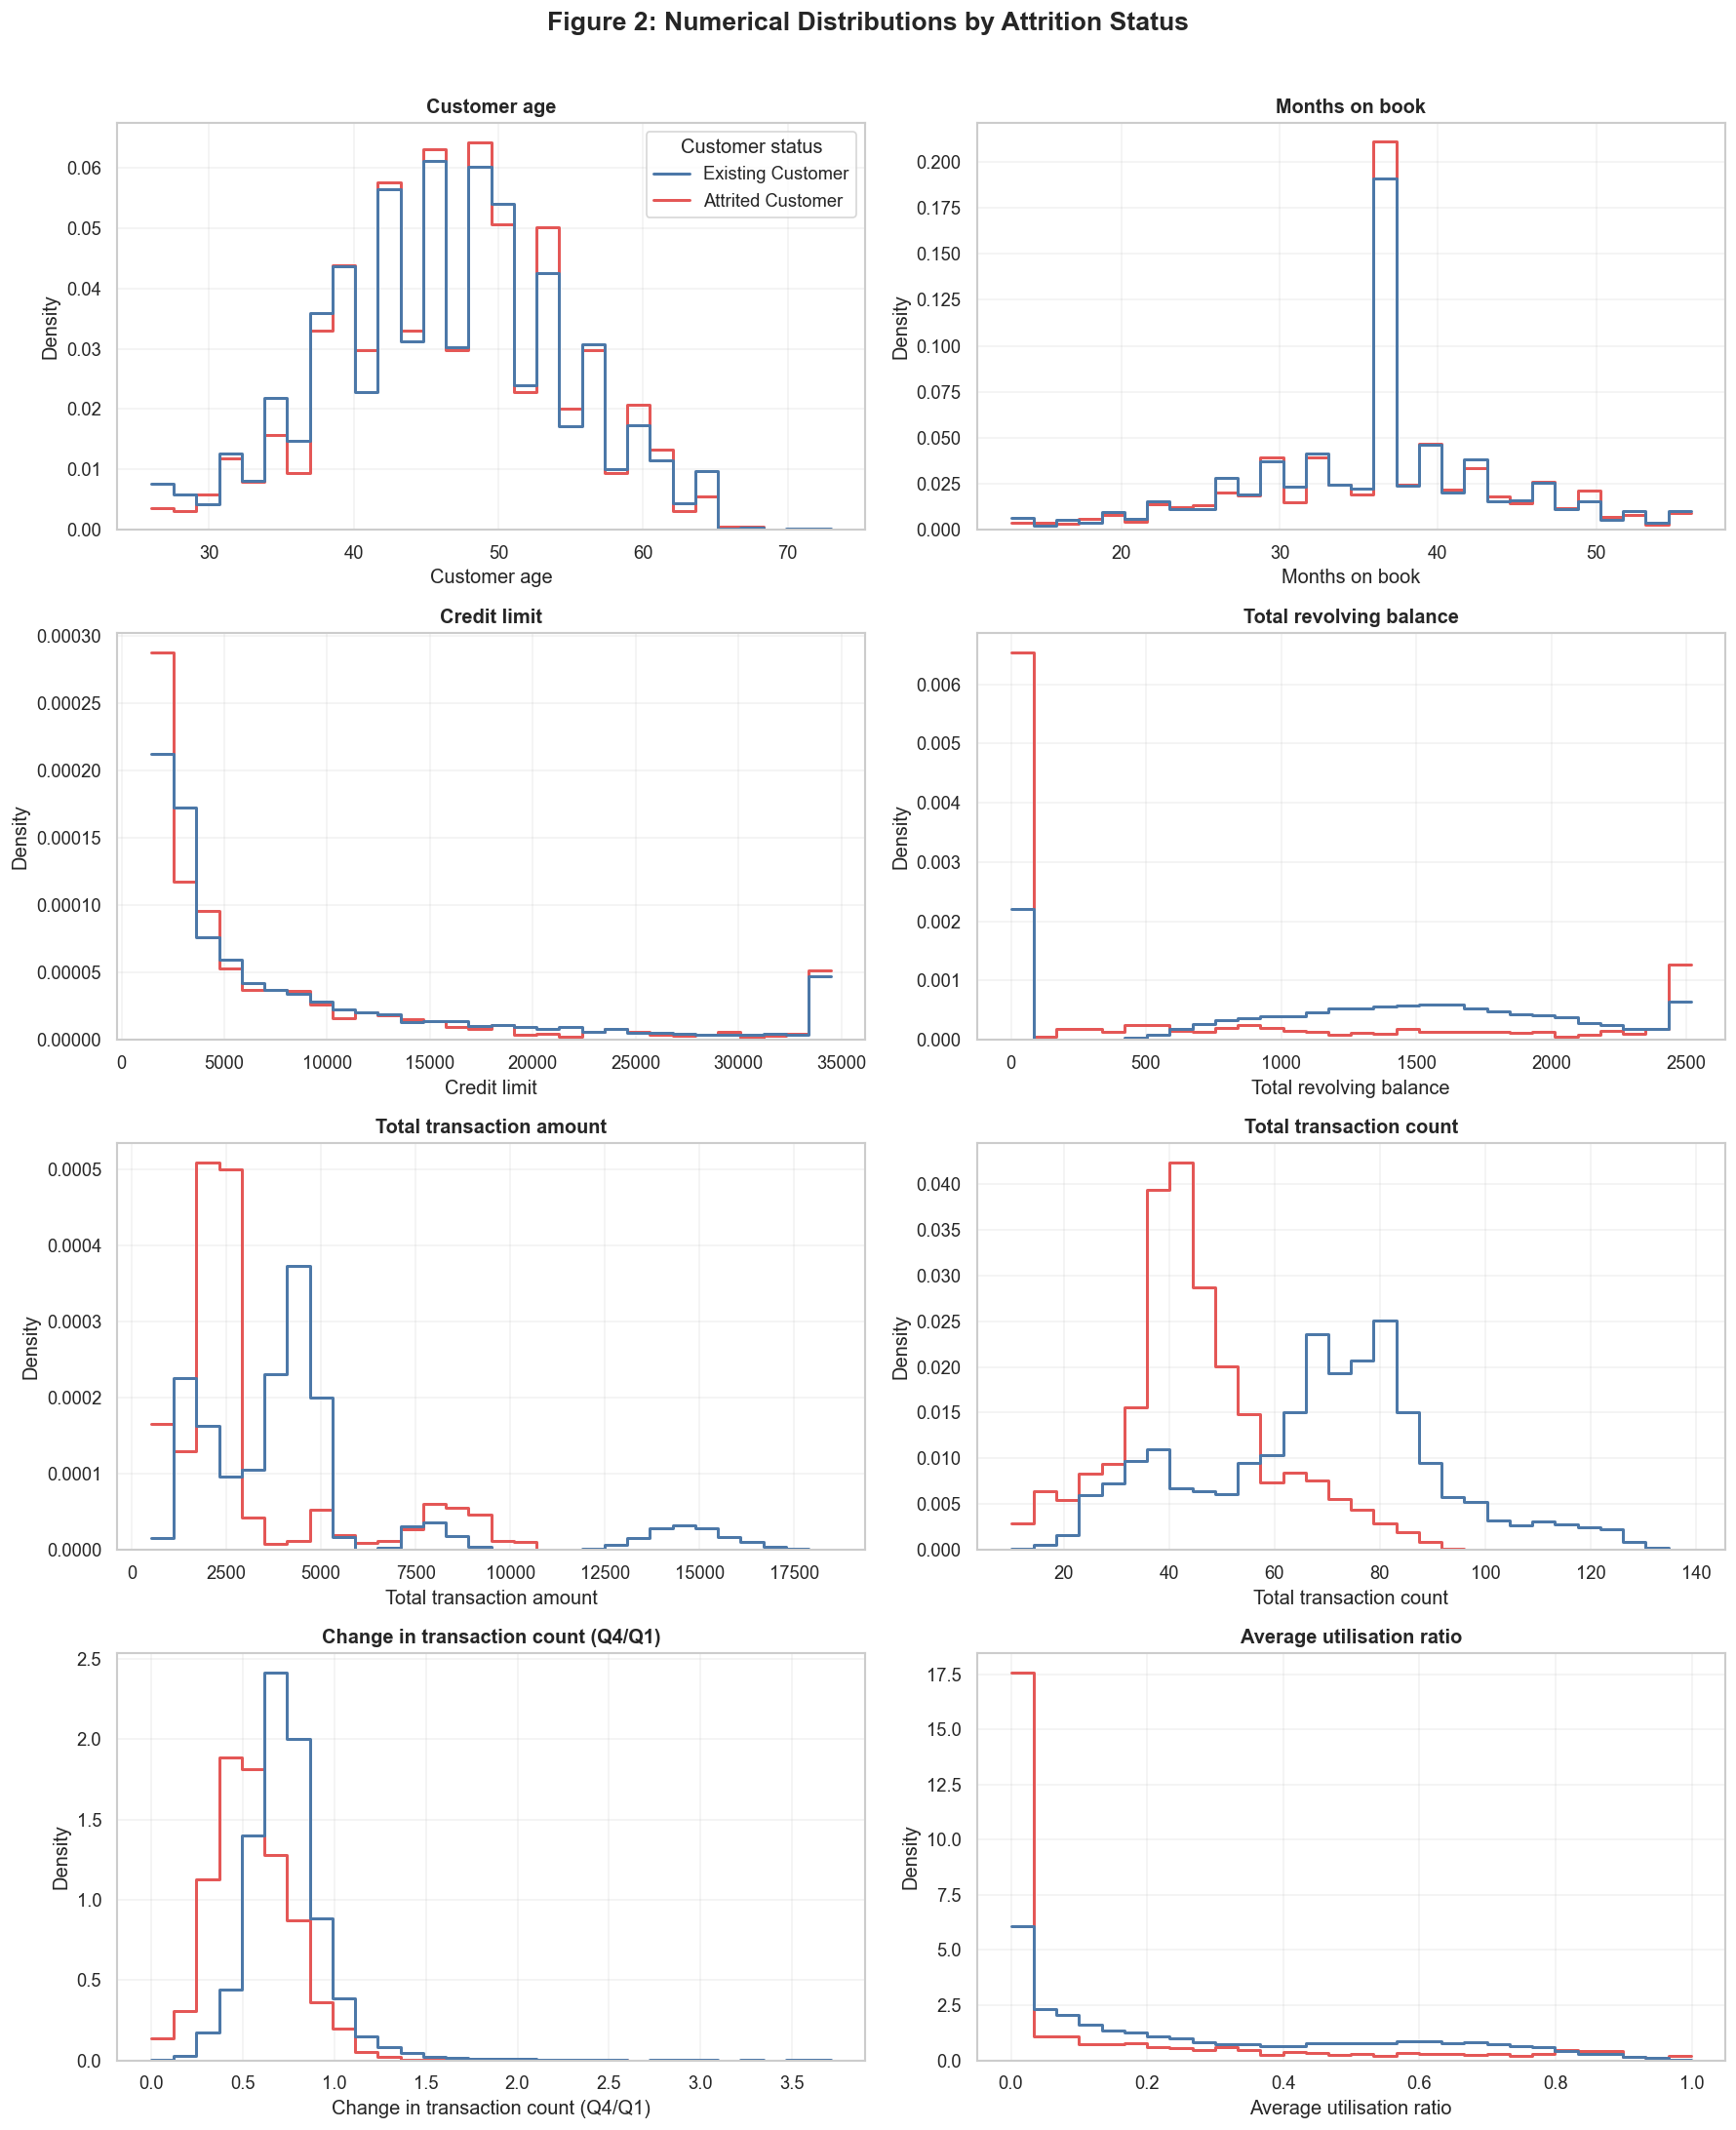

In [17]:
# Select numerical variables for detailed distribution comparison
key_numerical_variables = [
    "Customer_Age",
    "Months_on_book",
    "Credit_Limit",
    "Total_Revolving_Bal",
    "Total_Trans_Amt",
    "Total_Trans_Ct",
    "Total_Ct_Chng_Q4_Q1",
    "Avg_Utilization_Ratio"
]

# Create readable labels for figures
numerical_variable_labels = {
    "Customer_Age": "Customer age",
    "Months_on_book": "Months on book",
    "Credit_Limit": "Credit limit",
    "Total_Revolving_Bal": "Total revolving balance",
    "Total_Trans_Amt": "Total transaction amount",
    "Total_Trans_Ct": "Total transaction count",
    "Total_Ct_Chng_Q4_Q1": "Change in transaction count (Q4/Q1)",
    "Avg_Utilization_Ratio": "Average utilisation ratio"
}

fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.flatten()

for index, (ax, variable) in enumerate(
    zip(axes, key_numerical_variables)
):
    sns.histplot(
        data=df,
        x=variable,
        hue=TARGET,
        hue_order=status_order,
        palette=status_colours,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        bins=30,
        linewidth=1.8,
        ax=ax
    )

    label = numerical_variable_labels[variable]

    ax.set_title(label, fontweight="bold")
    ax.set_xlabel(label)
    ax.set_ylabel("Density")
    ax.grid(alpha=0.25)

    # Retain one shared explanatory legend only
    legend = ax.get_legend()

    if legend is not None:
        if index == 0:
            legend.set_title("Customer status")
        else:
            legend.remove()

fig.suptitle(
    "Figure 2: Numerical Distributions by Attrition Status",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.savefig(
    "figure_2_numerical_distributions_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

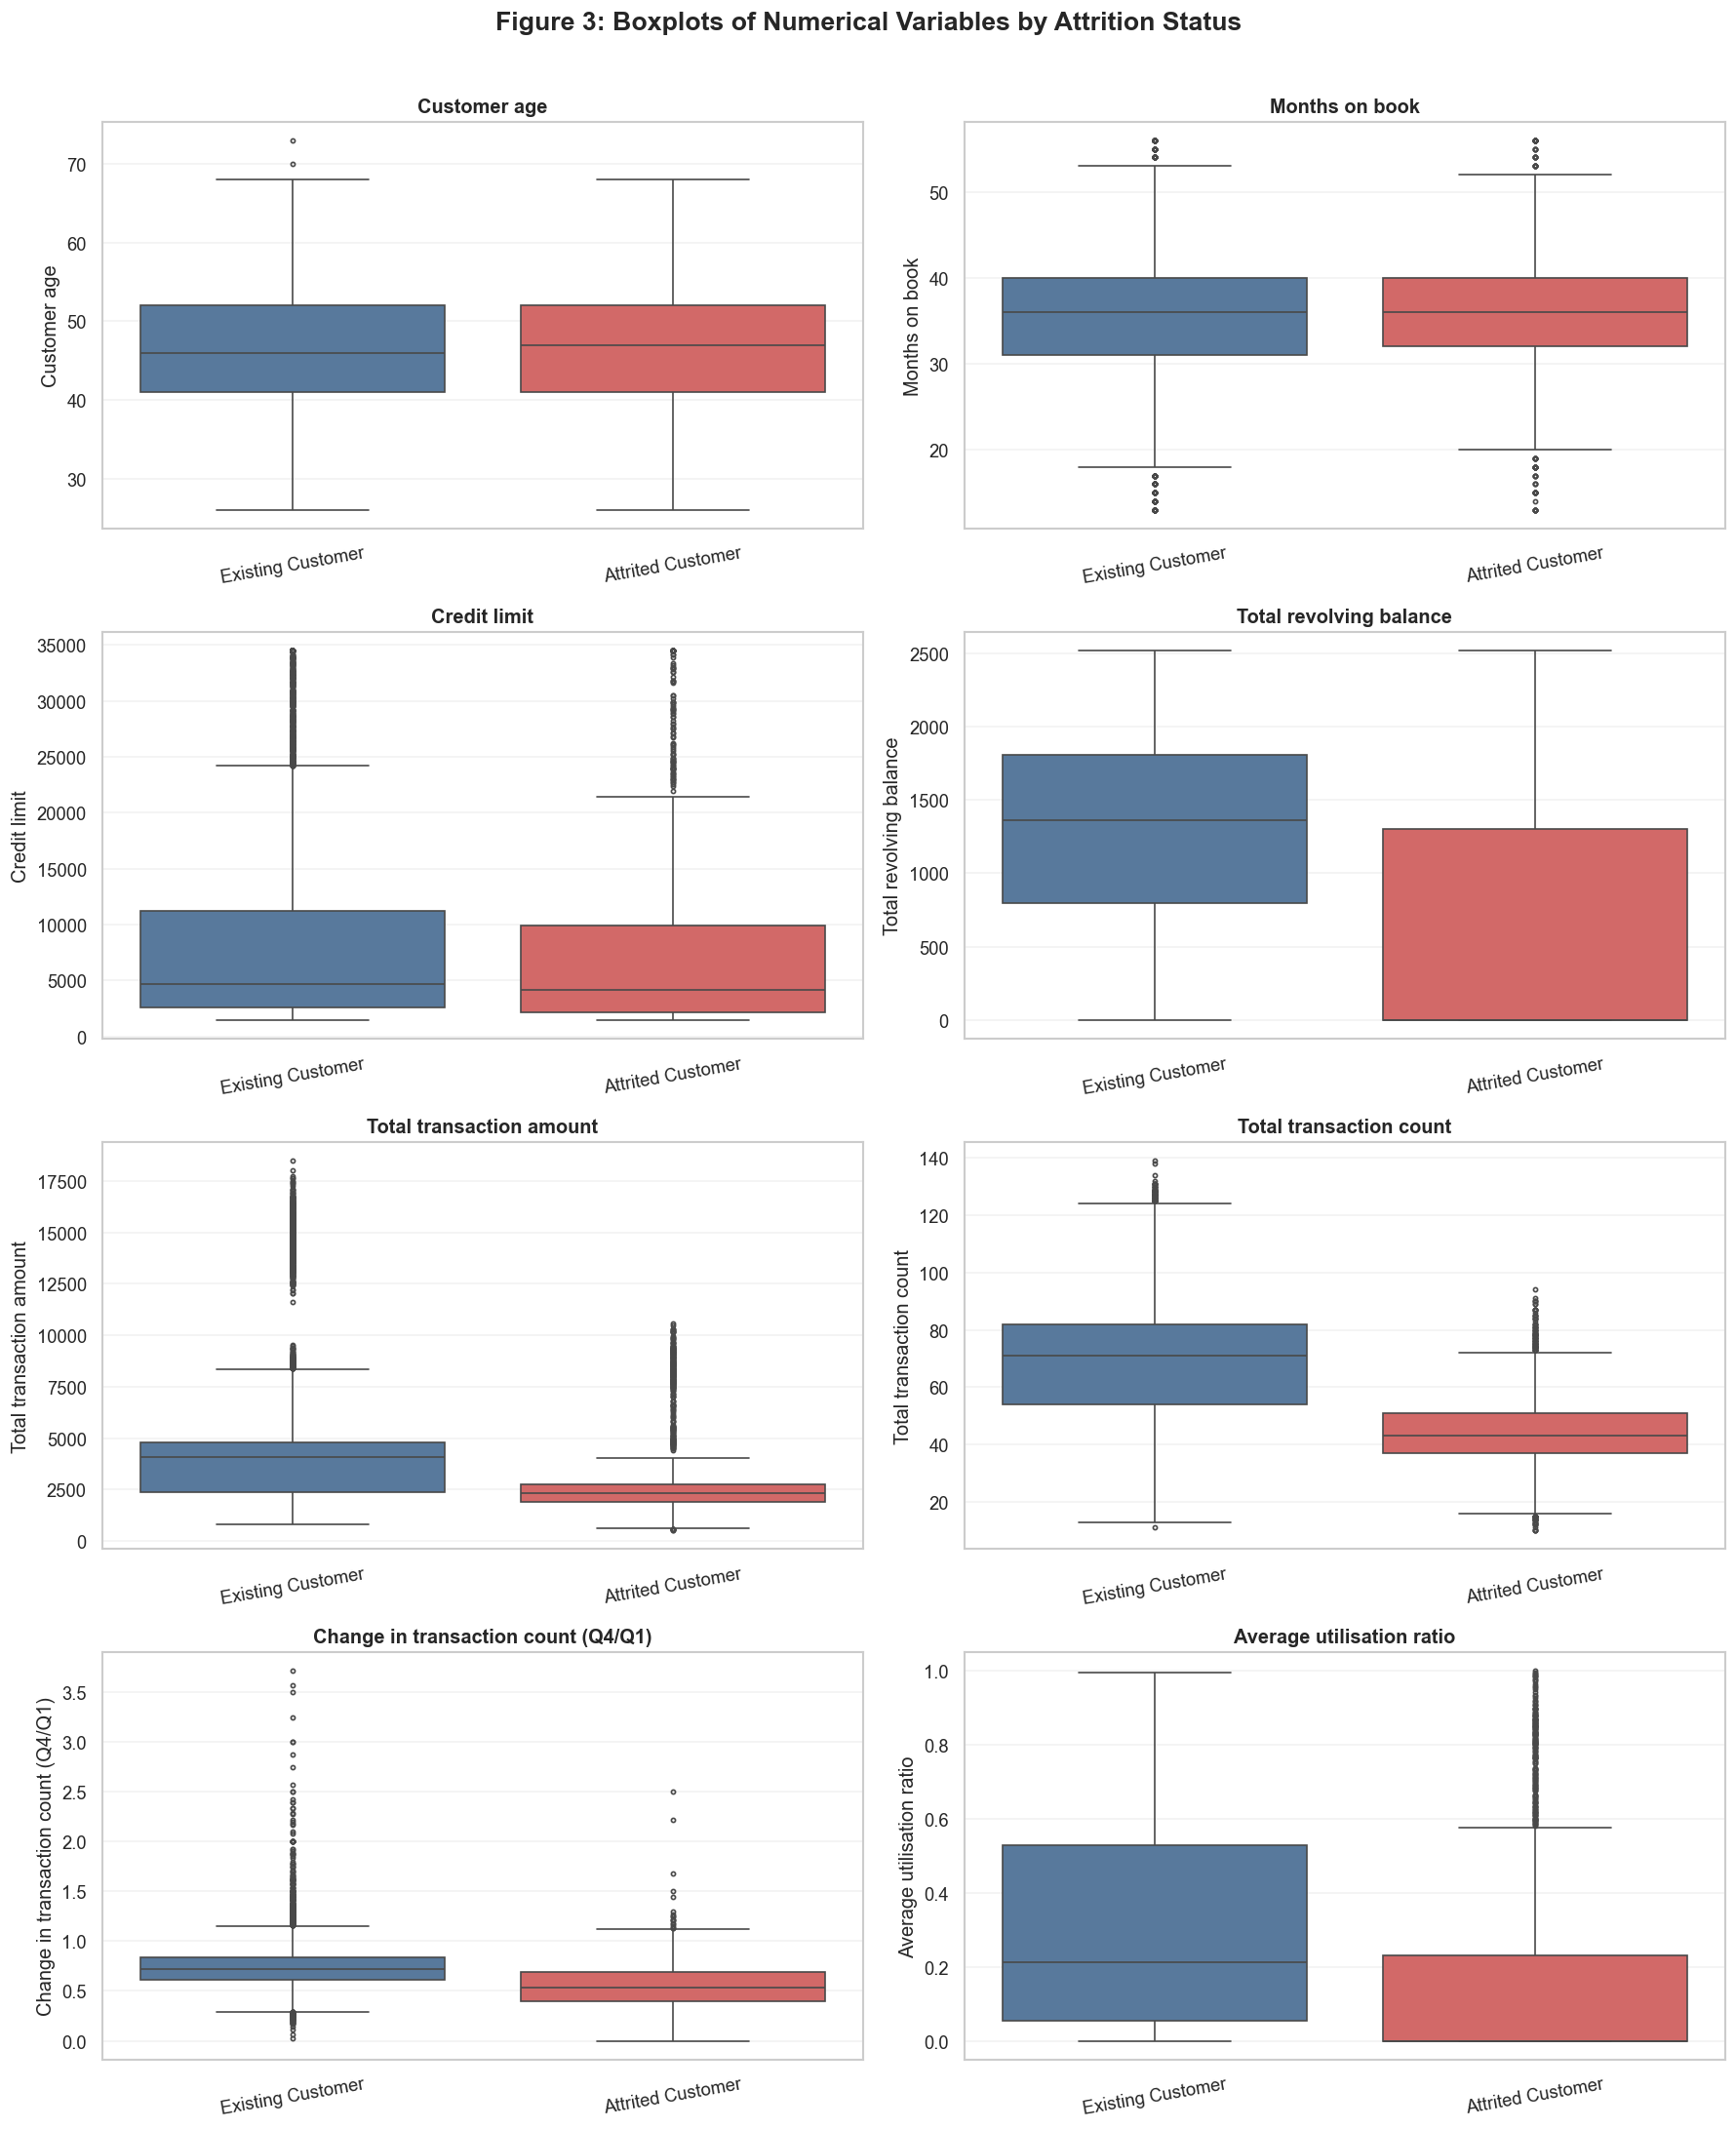

In [18]:
# Compare numerical-variable distributions using boxplots
fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.flatten()

for ax, variable in zip(axes, key_numerical_variables):
    sns.boxplot(
        data=df,
        x=TARGET,
        y=variable,
        order=status_order,
        hue=TARGET,
        hue_order=status_order,
        palette=status_colours,
        dodge=False,
        legend=False,
        showfliers=True,
        fliersize=2.5,
        linewidth=1,
        ax=ax
    )

    label = numerical_variable_labels[variable]

    ax.set_title(label, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(label)
    ax.tick_params(axis="x", rotation=10)
    ax.grid(axis="y", alpha=0.25)
    ax.grid(axis="x", visible=False)

fig.suptitle(
    "Figure 3: Boxplots of Numerical Variables by Attrition Status",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.savefig(
    "figure_3_numerical_boxplots_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [19]:
# Compare selected numerical variables across attrition groups
grouped_numerical_summary = (
    df.groupby(TARGET, observed=False)[key_numerical_variables]
    .agg(["mean", "median", "std"])
    .round(3)
    .T
    .reset_index()
)

# Rename columns for clearer presentation
grouped_numerical_summary = (
    grouped_numerical_summary.rename(columns={
        "level_0": "Variable",
        "level_1": "Statistic",
        "Existing Customer": "Existing_Customer",
        "Attrited Customer": "Attrited_Customer"
    })
)

# Use readable statistic labels
grouped_numerical_summary["Statistic"] = (
    grouped_numerical_summary["Statistic"]
    .replace({
        "mean": "Mean",
        "median": "Median",
        "std": "Standard deviation"
    })
)

# Arrange columns consistently
grouped_numerical_summary = grouped_numerical_summary[
    [
        "Variable",
        "Statistic",
        "Existing_Customer",
        "Attrited_Customer"
    ]
]

display(grouped_numerical_summary)

# Save the grouped descriptive-statistics table
grouped_numerical_summary.to_csv(
    "table_grouped_numerical_statistics.csv",
    index=False
)

print(
    "Grouped numerical statistics saved as "
    "'table_grouped_numerical_statistics.csv'."
)

Attrition_Flag,Variable,Statistic,Existing_Customer,Attrited_Customer
0,Customer_Age,Mean,46.262,46.659
1,Customer_Age,Median,46.000,47.000
2,Customer_Age,Standard deviation,8.081,7.666
3,Months_on_book,Mean,35.881,36.178
4,Months_on_book,Median,36.000,36.000
5,Months_on_book,Standard deviation,8.022,7.797
6,Credit_Limit,Mean,"8,726.878","8,136.039"
7,Credit_Limit,Median,"4,643.500","4,178.000"
8,Credit_Limit,Standard deviation,"9,084.970","9,095.334"
9,Total_Revolving_Bal,Mean,"1,256.604",672.823


Grouped numerical statistics saved as 'table_grouped_numerical_statistics.csv'.


In [20]:
# Calculate mean differences between attrited and existing customers
group_means = (
    df.groupby(TARGET, observed=False)[key_numerical_variables]
    .mean()
    .T
    .rename_axis("Variable")
    .reset_index()
)

group_means["Mean_Difference_Attrited_Minus_Existing"] = (
    group_means["Attrited Customer"]
    - group_means["Existing Customer"]
)

group_means[
    "Percentage_Difference_Relative_to_Existing"
] = (
    group_means[
        "Mean_Difference_Attrited_Minus_Existing"
    ]
    / group_means["Existing Customer"]
    * 100
)

group_means["Absolute_Percentage_Difference"] = (
    group_means[
        "Percentage_Difference_Relative_to_Existing"
    ].abs()
)

group_means = (
    group_means
    .sort_values(
        "Absolute_Percentage_Difference",
        ascending=False
    )
    .round(3)
    .reset_index(drop=True)
)

display(group_means)

# Save the mean-difference comparison table
group_means.to_csv(
    "table_numerical_mean_differences_by_churn.csv",
    index=False
)

print(
    "Numerical mean-difference table saved as "
    "'table_numerical_mean_differences_by_churn.csv'."
)

Attrition_Flag,Variable,Attrited Customer,Existing Customer,Mean_Difference_Attrited_Minus_Existing,Percentage_Difference_Relative_to_Existing,Absolute_Percentage_Difference
0,Total_Revolving_Bal,672.823,"1,256.604",-583.781,-46.457,46.457
1,Avg_Utilization_Ratio,0.162,0.296,-0.134,-45.186,45.186
2,Total_Trans_Ct,44.934,68.673,-23.739,-34.568,34.568
3,Total_Trans_Amt,"3,095.026","4,654.656","-1,559.630",-33.507,33.507
4,Total_Ct_Chng_Q4_Q1,0.554,0.742,-0.188,-25.329,25.329
5,Credit_Limit,"8,136.039","8,726.878",-590.838,-6.770,6.770
6,Customer_Age,46.659,46.262,0.397,0.859,0.859
7,Months_on_book,36.178,35.881,0.298,0.830,0.830


Numerical mean-difference table saved as 'table_numerical_mean_differences_by_churn.csv'.


#### Numerical-Distribution Findings

The exploratory comparisons show that transaction behaviour provides clearer unadjusted separation between existing and attrited customers than customer age or relationship duration. Attrited customers record substantially lower average transaction counts and transaction amounts, suggesting a retrospective association between lower engagement and attrition status.

Revolving balance, change in transaction count and credit utilisation also differ between the two groups. Existing customers generally hold higher revolving balances and utilisation ratios, while attrited customers show lower transaction-count change. In contrast, customer age and months on book display considerable distributional overlap, indicating limited class separation when considered individually.

Several numerical variables contain observations beyond the conventional boxplot whiskers. These observations are treated as potential statistical outliers rather than automatically classified as data errors. Their frequency, class distribution and business plausibility will be assessed in Section 3.6 before deciding whether any treatment is justified.

These findings are descriptive bivariate associations. They do not establish that the variables independently cause attrition, that they were necessarily measured before attrition, or that they will remain influential after the other predictors are considered jointly.


### 3.4 Categorical Variables and Attrition Rates

The five categorical predictors are examined using category frequencies and within-category attrition rates. Frequency tables show how customers are distributed across categories and identify groups with small sample sizes. Within-category attrition rates allow descriptive comparison of churn prevalence across customer groups.

Approximate 95% Wilson confidence intervals are calculated for each category-level attrition rate. These intervals show the uncertainty surrounding each estimate and are particularly important for sparsely represented categories. A high observed attrition rate based on very few customers should not be interpreted as equally reliable as a similar rate calculated from a large group.

The analysis also retains and reports categories labelled `Unknown`. This allows their frequency and attrition rate to be compared with the known categories before a treatment decision is made.

These comparisons are unadjusted and descriptive. They do not establish that a categorical characteristic causes attrition, nor do they confirm that the characteristic was recorded before the attrition outcome.


In [21]:
# Create frequency tables for all categorical predictors
categorical_frequency_tables = []

for variable in categorical_columns:
    frequency_table = (
        df[variable]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Count")
    )

    frequency_table["Percentage"] = (
        frequency_table["Count"] / len(df) * 100
    ).round(2)

    frequency_table.insert(0, "Variable", variable)

    categorical_frequency_tables.append(
        frequency_table
    )

# Combine the individual frequency tables
categorical_frequency_summary = pd.concat(
    categorical_frequency_tables,
    ignore_index=True
)

display(categorical_frequency_summary)

# Save the categorical-frequency table
categorical_frequency_summary.to_csv(
    "table_categorical_frequencies.csv",
    index=False
)

print(
    "Categorical-frequency table saved as "
    "'table_categorical_frequencies.csv'."
)

,Variable,Category,Count,Percentage
0,Gender,F,5358,52.910
1,Gender,M,4769,47.090
2,Education_Level,Graduate,3128,30.890
3,Education_Level,High School,2013,19.880
4,Education_Level,Unknown,1519,15.000
5,Education_Level,Uneducated,1487,14.680
6,Education_Level,College,1013,10.000
7,Education_Level,Post-Graduate,516,5.100
8,Education_Level,Doctorate,451,4.450
9,Marital_Status,Married,4687,46.280


Categorical-frequency table saved as 'table_categorical_frequencies.csv'.


In [22]:
# Create a temporary binary target for descriptive calculations only
churn_indicator = (
    df[TARGET] == "Attrited Customer"
).astype(int)

categorical_churn_tables = []

# Critical value for an approximate 95% confidence interval
z = 1.96

for variable in categorical_columns:
    temporary_data = pd.DataFrame({
        variable: df[variable],
        "Churn": churn_indicator
    })

    summary = (
        temporary_data
        .groupby(variable, dropna=False)["Churn"]
        .agg(["count", "sum", "mean"])
        .reset_index()
    )

    summary = summary.rename(columns={
        variable: "Category",
        "count": "Customer_Count",
        "sum": "Attrited_Count",
        "mean": "Churn_Proportion"
    })

    # Calculate Wilson 95% confidence intervals
    n = summary["Customer_Count"]
    p = summary["Churn_Proportion"]

    denominator = 1 + (z**2 / n)

    centre = (
        p + z**2 / (2 * n)
    ) / denominator

    margin = (
        z
        * np.sqrt(
            (p * (1 - p) / n)
            + (z**2 / (4 * n**2))
        )
        / denominator
    )

    summary["Churn_Rate_Percentage"] = (
        summary["Churn_Proportion"] * 100
    )

    summary["Lower_95_CI"] = (
        centre - margin
    ) * 100

    summary["Upper_95_CI"] = (
        centre + margin
    ) * 100

    summary["CI_Width"] = (
        summary["Upper_95_CI"]
        - summary["Lower_95_CI"]
    )

    summary.insert(0, "Variable", variable)

    categorical_churn_tables.append(summary)

# Combine all categorical churn-rate tables
categorical_churn_summary = pd.concat(
    categorical_churn_tables,
    ignore_index=True
)

categorical_churn_summary = categorical_churn_summary[
    [
        "Variable",
        "Category",
        "Customer_Count",
        "Attrited_Count",
        "Churn_Rate_Percentage",
        "Lower_95_CI",
        "Upper_95_CI",
        "CI_Width"
    ]
].round(2)

display(categorical_churn_summary)

# Save the categorical churn-rate table
categorical_churn_summary.to_csv(
    "table_categorical_churn_rates.csv",
    index=False
)

print(
    "Categorical churn-rate table saved as "
    "'table_categorical_churn_rates.csv'."
)

,Variable,Category,Customer_Count,Attrited_Count,Churn_Rate_Percentage,Lower_95_CI,Upper_95_CI,CI_Width
0,Gender,F,5358,930,17.360,16.370,18.390,2.030
1,Gender,M,4769,697,14.620,13.640,15.650,2.010
2,Education_Level,College,1013,154,15.200,13.120,17.540,4.420
3,Education_Level,Doctorate,451,95,21.060,17.550,25.060,7.510
4,Education_Level,Graduate,3128,487,15.570,14.340,16.880,2.540
5,Education_Level,High School,2013,306,15.200,13.700,16.840,3.140
6,Education_Level,Post-Graduate,516,92,17.830,14.770,21.370,6.600
7,Education_Level,Uneducated,1487,237,15.940,14.170,17.890,3.720
8,Education_Level,Unknown,1519,256,16.850,15.050,18.820,3.760
9,Marital_Status,Divorced,748,121,16.180,13.710,18.990,5.280


Categorical churn-rate table saved as 'table_categorical_churn_rates.csv'.


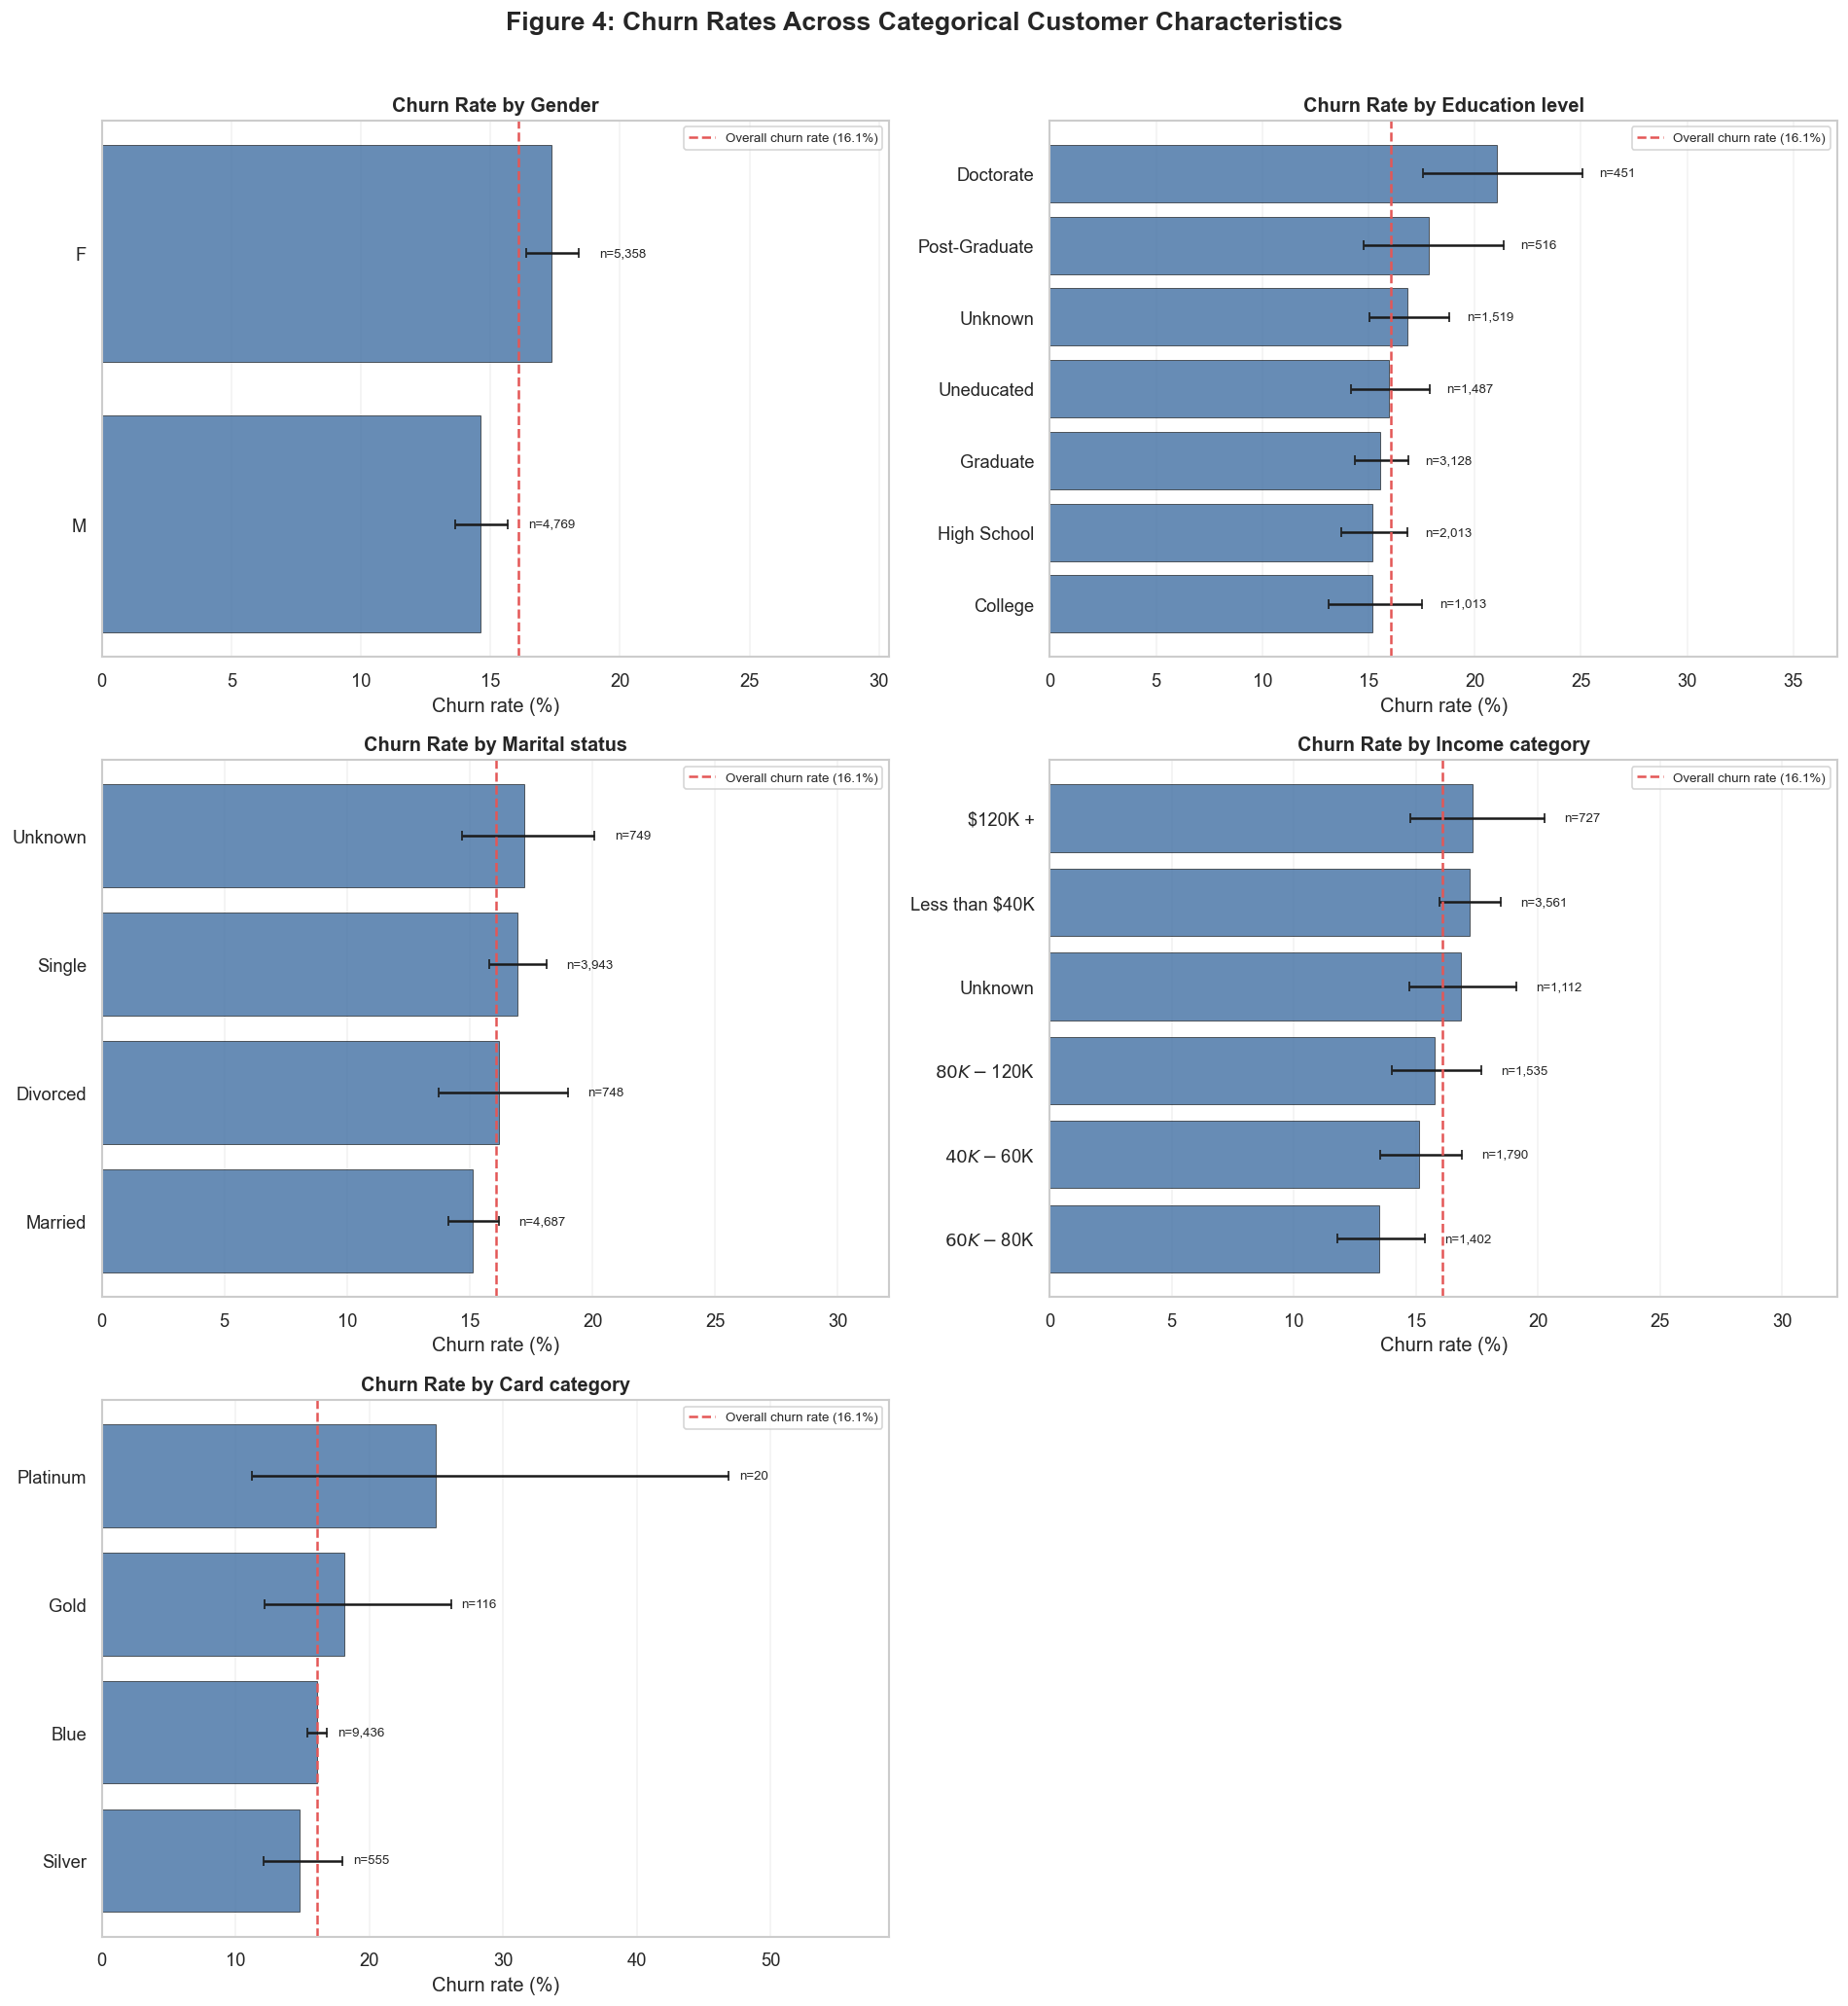

In [23]:
# Create readable labels for categorical variables
categorical_variable_labels = {
    "Gender": "Gender",
    "Education_Level": "Education level",
    "Marital_Status": "Marital status",
    "Income_Category": "Income category",
    "Card_Category": "Card category"
}

fig, axes = plt.subplots(3, 2, figsize=(16, 17))
axes = axes.flatten()

overall_churn_rate = churn_indicator.mean() * 100

for ax, variable in zip(axes, categorical_columns):
    plot_data = (
        categorical_churn_summary[
            categorical_churn_summary["Variable"] == variable
        ]
        .sort_values("Churn_Rate_Percentage")
        .copy()
    )

    lower_error = (
        plot_data["Churn_Rate_Percentage"]
        - plot_data["Lower_95_CI"]
    )

    upper_error = (
        plot_data["Upper_95_CI"]
        - plot_data["Churn_Rate_Percentage"]
    )

    bars = ax.barh(
        plot_data["Category"].astype(str),
        plot_data["Churn_Rate_Percentage"],
        xerr=[lower_error, upper_error],
        color="#4C78A8",
        alpha=0.85,
        capsize=3,
        edgecolor="black",
        linewidth=0.4
    )

    # Add the sample size for each category
    for bar, customer_count, upper_ci in zip(
        bars,
        plot_data["Customer_Count"],
        plot_data["Upper_95_CI"]
    ):
        ax.text(
            upper_ci + 0.8,
            bar.get_y() + bar.get_height() / 2,
            f"n={customer_count:,}",
            va="center",
            fontsize=8
        )

    ax.axvline(
        overall_churn_rate,
        color="#E45756",
        linestyle="--",
        linewidth=1.5,
        label=(
            "Overall churn rate "
            f"({overall_churn_rate:.1f}%)"
        )
    )

    ax.set_title(
        "Churn Rate by "
        f"{categorical_variable_labels[variable]}",
        fontweight="bold"
    )
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")
    ax.legend(fontsize=8)
    ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False)

    upper_limit = min(
        100,
        plot_data["Upper_95_CI"].max() + 12
    )
    ax.set_xlim(0, upper_limit)

# Hide the unused sixth panel
axes[-1].axis("off")

fig.suptitle(
    "Figure 4: Churn Rates Across Categorical Customer Characteristics",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.savefig(
    "figure_4_categorical_churn_rates.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [24]:
# Identify sparsely represented categories
SMALL_CATEGORY_THRESHOLD = 100

small_categories = (
    categorical_churn_summary[
        categorical_churn_summary["Customer_Count"]
        < SMALL_CATEGORY_THRESHOLD
    ]
    .sort_values("Customer_Count")
    .reset_index(drop=True)
)

print(
    "Categories containing fewer than "
    f"{SMALL_CATEGORY_THRESHOLD} customers:"
)
print(f"Number of small categories: {len(small_categories)}")

display(small_categories)

Categories containing fewer than 100 customers:
Number of small categories: 1


,Variable,Category,Customer_Count,Attrited_Count,Churn_Rate_Percentage,Lower_95_CI,Upper_95_CI,CI_Width
0,Card_Category,Platinum,20,5,25.000,11.190,46.870,35.680


#### Categorical Attrition-Rate Findings

Observed attrition rates vary across categorical customer groups, but the size and precision of these differences are not uniform. Female customers have a higher observed attrition rate than male customers, at approximately 17.36% compared with 14.62%. Differences across marital-status and income groups are comparatively modest, and several confidence intervals overlap substantially.

The Doctorate education category records an attrition rate of approximately 21.06%, but its smaller sample produces greater uncertainty than the larger education groups. The same caution applies to card categories. Blue cardholders represent approximately 93.18% of the sample, while the Platinum category contains only 20 customers. Although Platinum records an observed attrition rate of 25.00%, its 95% confidence interval is approximately 11.19% to 46.87%. This estimate is too imprecise to support a strong conclusion that Platinum customers have the highest underlying attrition risk.

The `Unknown` education, marital-status and income groups record attrition rates close to the overall sample rate. These categories are retained during exploratory analysis because they represent information unavailable or undisclosed in the original dataset. However, `Unknown` is not interpreted as a substantive customer characteristic. Its treatment is assessed separately in Section 3.7.

These findings are descriptive and unadjusted. Group-level differences may reflect relationships with transaction activity, product holdings or other customer characteristics. They do not establish causal effects, confirm pre-churn measurement or independently justify customer-retention interventions.


### 3.5 Correlation and Multicollinearity Assessment

Pearson correlation is used to examine pairwise linear relationships among the 14 numerical predictors. The binary churn indicator is also included to measure each numerical predictor’s unadjusted linear association with attrition. When one variable is binary and the other is numerical, this calculation is equivalent to a point-biserial correlation.

The predictor correlation matrix helps identify variables that may contain overlapping information. Strong multicollinearity can complicate coefficient interpretation in Logistic Regression and may affect which correlated terms LASSO retains. Tree-based models are less dependent on linear independence, although correlated variables can still divide or redistribute feature-importance measures.

Correlation coefficients describe only linear pairwise relationships. They do not capture non-linear patterns, interaction effects, causation or the temporal order of predictors and attrition. Nominal categorical predictors are excluded because assigning arbitrary numerical codes to their categories would produce potentially misleading coefficients.


In [25]:
# Create correlation data using numerical predictors
correlation_data = df[numeric_columns].copy()

# Add the descriptive binary churn indicator created earlier
correlation_data["Churn"] = churn_indicator

# Calculate Pearson correlations
correlation_matrix = correlation_data.corr(
    method="pearson"
)

print("Correlation assessment")
print("-" * 45)
print(
    f"Numerical predictors included: "
    f"{len(numeric_columns)}"
)
print(
    f"Total variables in matrix: "
    f"{correlation_matrix.shape[0]}"
)
print(
    "Binary churn indicator included: "
    f"{'Churn' in correlation_matrix.columns}"
)

Correlation assessment
---------------------------------------------
Numerical predictors included: 14
Total variables in matrix: 15
Binary churn indicator included: True


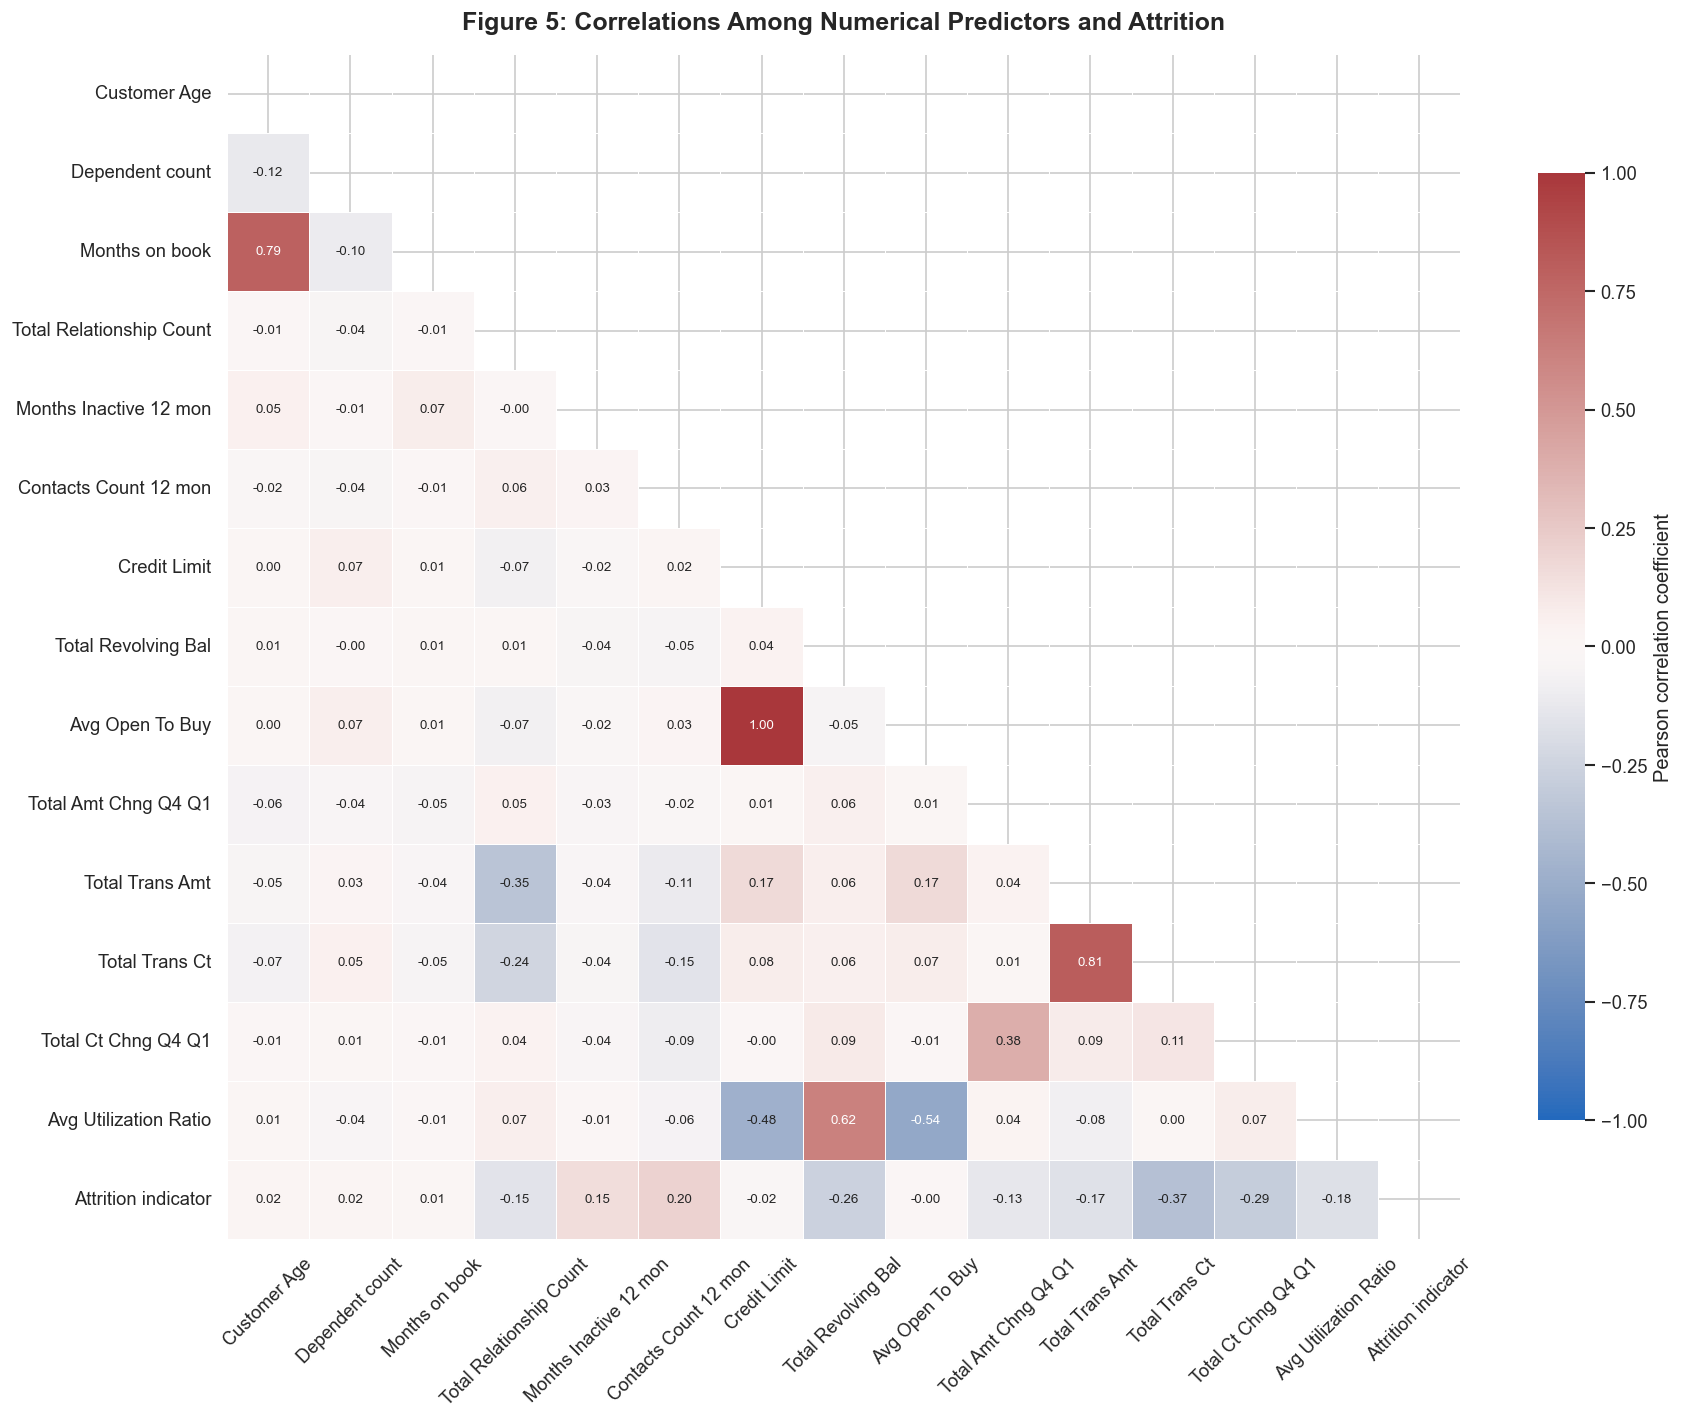

In [26]:
# Create readable labels for the correlation heatmap
correlation_labels = {
    column: column.replace("_", " ")
    for column in correlation_matrix.columns
}

correlation_labels["Churn"] = "Attrition indicator"

plot_correlation_matrix = correlation_matrix.rename(
    index=correlation_labels,
    columns=correlation_labels
)

# Mask the diagonal and upper triangle to avoid repetition
mask = np.triu(
    np.ones_like(
        plot_correlation_matrix,
        dtype=bool
    )
)

fig, ax = plt.subplots(figsize=(15, 12))

sns.heatmap(
    plot_correlation_matrix,
    mask=mask,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    annot_kws={"size": 8},
    cbar_kws={
        "label": "Pearson correlation coefficient",
        "shrink": 0.8
    },
    ax=ax
)

ax.set_title(
    "Figure 5: Correlations Among Numerical Predictors and Attrition",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig(
    "figure_5_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [27]:
# Rank numerical predictors by correlation with attrition
churn_correlations = (
    correlation_matrix["Churn"]
    .drop("Churn")
    .rename("Correlation_with_Churn")
    .to_frame()
)

churn_correlations["Absolute_Correlation"] = (
    churn_correlations["Correlation_with_Churn"]
    .abs()
)

churn_correlations = (
    churn_correlations
    .sort_values(
        "Absolute_Correlation",
        ascending=False
    )
    .round(3)
    .rename_axis("Variable")
    .reset_index()
)

display(churn_correlations)

# Save the numerical churn-correlation table
churn_correlations.to_csv(
    "table_numerical_correlations_with_churn.csv",
    index=False
)

print(
    "Numerical churn-correlation table saved as "
    "'table_numerical_correlations_with_churn.csv'."
)

,Variable,Correlation_with_Churn,Absolute_Correlation
0,Total_Trans_Ct,-0.371,0.371
1,Total_Ct_Chng_Q4_Q1,-0.290,0.290
2,Total_Revolving_Bal,-0.263,0.263
3,Contacts_Count_12_mon,0.204,0.204
4,Avg_Utilization_Ratio,-0.178,0.178
5,Total_Trans_Amt,-0.169,0.169
6,Months_Inactive_12_mon,0.152,0.152
7,Total_Relationship_Count,-0.150,0.150
8,Total_Amt_Chng_Q4_Q1,-0.131,0.131
9,Credit_Limit,-0.024,0.024


Numerical churn-correlation table saved as 'table_numerical_correlations_with_churn.csv'.


In [28]:
# Define the threshold for flagging strong predictor correlations
HIGH_CORRELATION_THRESHOLD = 0.80

# Calculate correlations among numerical predictors only
predictor_correlation_matrix = (
    df[numeric_columns].corr(method="pearson")
)

# Retain only the upper triangle to avoid duplicate pairs
upper_triangle = predictor_correlation_matrix.where(
    np.triu(
        np.ones(
            predictor_correlation_matrix.shape,
            dtype=bool
        ),
        k=1
    )
)

# Convert the matrix into a pairwise comparison table
high_correlation_pairs = (
    upper_triangle
    .stack()
    .rename("Correlation")
    .reset_index()
    .rename(columns={
        "level_0": "Variable_1",
        "level_1": "Variable_2"
    })
)

high_correlation_pairs["Absolute_Correlation"] = (
    high_correlation_pairs["Correlation"].abs()
)

high_correlation_pairs = (
    high_correlation_pairs[
        high_correlation_pairs["Absolute_Correlation"]
        >= HIGH_CORRELATION_THRESHOLD
    ]
    .sort_values(
        "Absolute_Correlation",
        ascending=False
    )
    .round(3)
    .reset_index(drop=True)
)

print(
    "Strong-correlation threshold: "
    f"|r| ≥ {HIGH_CORRELATION_THRESHOLD:.2f}"
)
print(
    "Number of strongly correlated predictor pairs: "
    f"{len(high_correlation_pairs)}"
)

display(high_correlation_pairs)

# Save the strong-correlation assessment
high_correlation_pairs.to_csv(
    "table_high_correlation_predictor_pairs.csv",
    index=False
)

print(
    "High-correlation table saved as "
    "'table_high_correlation_predictor_pairs.csv'."
)

Strong-correlation threshold: |r| ≥ 0.80
Number of strongly correlated predictor pairs: 2


,Variable_1,Variable_2,Correlation,Absolute_Correlation
0,Credit_Limit,Avg_Open_To_Buy,0.996,0.996
1,Total_Trans_Amt,Total_Trans_Ct,0.807,0.807


High-correlation table saved as 'table_high_correlation_predictor_pairs.csv'.


#### Correlation and Multicollinearity Findings

Transaction-related variables show the strongest numerical correlations with the binary attrition indicator. `Total_Trans_Ct` has the largest absolute correlation with attrition, at approximately −0.371, followed by `Total_Ct_Chng_Q4_Q1` at approximately −0.290 and `Total_Revolving_Bal` at approximately −0.263. The negative signs indicate that higher transaction frequency, greater transaction-count change and higher revolving balance are associated with a lower observed attrition outcome. `Contacts_Count_12_mon` has a positive correlation of approximately 0.204, indicating that customers with more recorded contacts have a higher observed attrition outcome.

Customer age and months on book have correlations close to zero. This supports the exploratory finding that transaction engagement has clearer unadjusted linear separation than age or relationship duration. However, a near-zero correlation does not prove that a predictor has no multivariable, non-linear or interaction-based predictive value.

`Credit_Limit` and `Avg_Open_To_Buy` are extremely strongly positively correlated. This relationship is structurally plausible because open-to-buy credit is closely related to the customer’s credit limit and revolving balance. `Total_Trans_Amt` and `Total_Trans_Ct` are also strongly positively correlated, reflecting related but distinct dimensions of transaction value and frequency.

These relationships may complicate coefficient interpretation. Regularisation can reduce coefficient magnitude, but LASSO selection may be unstable when several predictors provide overlapping information. Tree-based models can use correlated predictors, although their importance may be divided across related variables.

The correlations are unadjusted retrospective associations. They do not establish causal effects, capture non-linear relationships or confirm that the predictors were observed before attrition.


### 3.6 Outlier and Plausibility Assessment

Potential numerical outliers are identified using the conventional interquartile-range rule. For each numerical predictor, an observation is flagged when it falls below:

$$
Q1 - 1.5 \times IQR
$$

or above:

$$
Q3 + 1.5 \times IQR
$$

This rule identifies observations located far from the central portion of a distribution, but it does not determine whether those observations are erroneous. In banking data, high credit limits, large transaction amounts or unusual changes in customer activity may represent genuine customer behaviour rather than data-quality problems.

The statistical assessment is therefore supplemented with:

* observed minimum and maximum values;
* basic business-plausibility checks;
* comparison of flagged observations across attrition groups; and
* consideration of how each modelling method handles extreme values.

No observation is removed or capped solely because it is flagged by the IQR rule. A treatment decision is made only after examining whether the values are impossible, inconsistent or likely to distort the intended analysis.


In [29]:
# Assess potential outliers using the 1.5 × IQR rule
outlier_records = []

for variable in numeric_columns:
    q1 = df[variable].quantile(0.25)
    q3 = df[variable].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)

    outlier_mask = (
        (df[variable] < lower_bound)
        | (df[variable] > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())
    outlier_percentage = (
        outlier_count / len(df) * 100
    )

    outlier_records.append({
        "Variable": variable,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": outlier_percentage
    })

outlier_summary = (
    pd.DataFrame(outlier_records)
    .sort_values(
        "Outlier_Percentage",
        ascending=False
    )
    .round(3)
    .reset_index(drop=True)
)

display(outlier_summary)

# Save the IQR outlier-assessment table
outlier_summary.to_csv(
    "table_iqr_outlier_assessment.csv",
    index=False
)

print(
    "IQR outlier-assessment table saved as "
    "'table_iqr_outlier_assessment.csv'."
)

,Variable,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Credit_Limit,"2,555.000","11,067.500","8,512.500","-10,213.750","23,836.250",984,9.717
1,Avg_Open_To_Buy,"1,324.500","9,859.000","8,534.500","-11,477.250","22,660.750",963,9.509
2,Total_Trans_Amt,"2,155.500","4,741.000","2,585.500","-1,722.750","8,619.250",896,8.848
3,Contacts_Count_12_mon,2.000,3.000,1.000,0.500,4.500,629,6.211
4,Total_Amt_Chng_Q4_Q1,0.631,0.859,0.228,0.289,1.201,396,3.910
5,Total_Ct_Chng_Q4_Q1,0.582,0.818,0.236,0.228,1.172,394,3.891
6,Months_on_book,31.000,40.000,9.000,17.500,53.500,386,3.812
7,Months_Inactive_12_mon,2.000,3.000,1.000,0.500,4.500,331,3.268
8,Customer_Age,41.000,52.000,11.000,24.500,68.500,2,0.020
9,Total_Trans_Ct,45.000,81.000,36.000,-9.000,135.000,2,0.020


IQR outlier-assessment table saved as 'table_iqr_outlier_assessment.csv'.


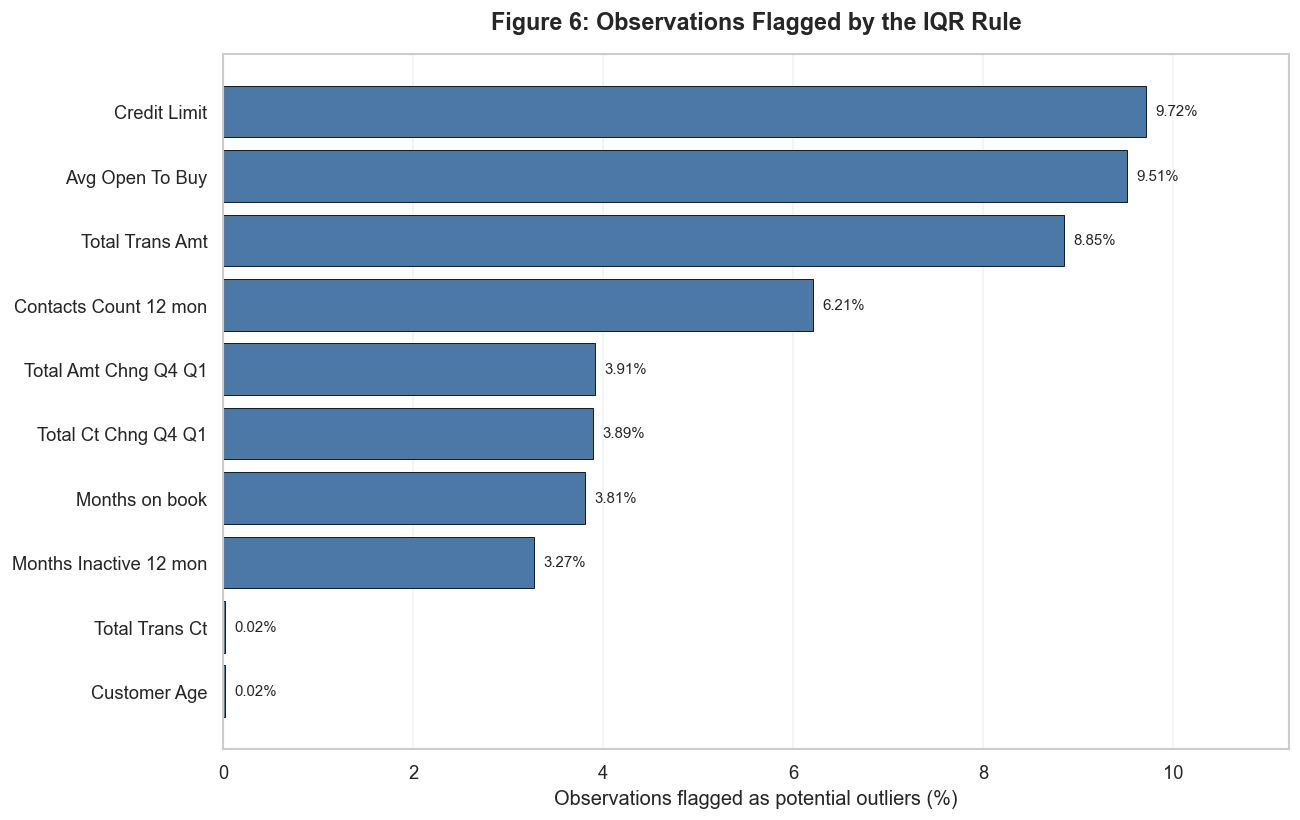

In [30]:
# Retain variables with at least one IQR-flagged observation
plot_outliers = (
    outlier_summary[
        outlier_summary["Outlier_Count"] > 0
    ]
    .sort_values("Outlier_Percentage")
    .copy()
)

# Create readable labels
plot_outliers["Plot_Label"] = (
    plot_outliers["Variable"]
    .str.replace("_", " ", regex=False)
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    plot_outliers["Plot_Label"],
    plot_outliers["Outlier_Percentage"],
    color="#4C78A8",
    edgecolor="black",
    linewidth=0.5
)

# Add percentage labels
for bar, value in zip(
    bars,
    plot_outliers["Outlier_Percentage"]
):
    ax.text(
        value + 0.1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Figure 6: Observations Flagged by the IQR Rule",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel(
    "Observations flagged as potential outliers (%)"
)
ax.set_ylabel("")
ax.set_xlim(
    0,
    plot_outliers["Outlier_Percentage"].max() + 1.5
)
ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.savefig(
    "figure_6_iqr_outlier_percentages.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [31]:
# Examine observed ranges and potentially unusual values
observed_ranges = pd.DataFrame({
    "Minimum": df[numeric_columns].min(),
    "Maximum": df[numeric_columns].max(),
    "Number_of_Zero_Values": (
        df[numeric_columns] == 0
    ).sum(),
    "Number_of_Negative_Values": (
        df[numeric_columns] < 0
    ).sum()
})

observed_ranges["Zero_Value_Percentage"] = (
    observed_ranges["Number_of_Zero_Values"]
    / len(df)
    * 100
)

observed_ranges = (
    observed_ranges
    .round(3)
    .rename_axis("Variable")
    .reset_index()
)

display(observed_ranges)

# Save the observed-range assessment
observed_ranges.to_csv(
    "table_numerical_observed_ranges.csv",
    index=False
)

print(
    "Numerical observed-range table saved as "
    "'table_numerical_observed_ranges.csv'."
)

,Variable,Minimum,Maximum,Number_of_Zero_Values,Number_of_Negative_Values,Zero_Value_Percentage
0,Customer_Age,26.000,73.000,0,0,0.000
1,Dependent_count,0.000,5.000,904,0,8.927
2,Months_on_book,13.000,56.000,0,0,0.000
3,Total_Relationship_Count,1.000,6.000,0,0,0.000
4,Months_Inactive_12_mon,0.000,6.000,29,0,0.286
5,Contacts_Count_12_mon,0.000,6.000,399,0,3.940
6,Credit_Limit,"1,438.300","34,516.000",0,0,0.000
7,Total_Revolving_Bal,0.000,"2,517.000",2470,0,24.390
8,Avg_Open_To_Buy,3.000,"34,516.000",0,0,0.000
9,Total_Amt_Chng_Q4_Q1,0.000,3.397,5,0,0.049


Numerical observed-range table saved as 'table_numerical_observed_ranges.csv'.


In [32]:
# Perform basic business-plausibility and consistency checks
expected_open_to_buy = (
    df["Credit_Limit"]
    - df["Total_Revolving_Bal"]
)

plausibility_checks = {
    "Age below 18": (
        df["Customer_Age"] < 18
    ).sum(),

    "Age above 100": (
        df["Customer_Age"] > 100
    ).sum(),

    "Negative dependent count": (
        df["Dependent_count"] < 0
    ).sum(),

    "Non-positive months on book": (
        df["Months_on_book"] <= 0
    ).sum(),

    "Relationship count below 1": (
        df["Total_Relationship_Count"] < 1
    ).sum(),

    "Negative credit limits": (
        df["Credit_Limit"] < 0
    ).sum(),

    "Negative revolving balances": (
        df["Total_Revolving_Bal"] < 0
    ).sum(),

    "Negative open-to-buy values": (
        df["Avg_Open_To_Buy"] < 0
    ).sum(),

    "Open-to-buy inconsistent with limit minus balance": (
        ~np.isclose(
            df["Avg_Open_To_Buy"],
            expected_open_to_buy,
            atol=0.01
        )
    ).sum(),

    "Negative transaction amounts": (
        df["Total_Trans_Amt"] < 0
    ).sum(),

    "Negative transaction counts": (
        df["Total_Trans_Ct"] < 0
    ).sum(),

    "Utilisation ratio below 0": (
        df["Avg_Utilization_Ratio"] < 0
    ).sum(),

    "Utilisation ratio above 1": (
        df["Avg_Utilization_Ratio"] > 1
    ).sum(),

    "Months inactive above 12": (
        df["Months_Inactive_12_mon"] > 12
    ).sum()
}

plausibility_check_table = pd.DataFrame(
    plausibility_checks.items(),
    columns=[
        "Plausibility_Check",
        "Number_of_Observations"
    ]
)

display(plausibility_check_table)

total_flagged_plausibility_issues = (
    plausibility_check_table[
        "Number_of_Observations"
    ].sum()
)

print(
    "Total observations flagged across plausibility checks: "
    f"{total_flagged_plausibility_issues:,}"
)

# Save the plausibility assessment
plausibility_check_table.to_csv(
    "table_numerical_plausibility_checks.csv",
    index=False
)

print(
    "Plausibility-check table saved as "
    "'table_numerical_plausibility_checks.csv'."
)

,Plausibility_Check,Number_of_Observations
0,Age below 18,0
1,Age above 100,0
2,Negative dependent count,0
3,Non-positive months on book,0
4,Relationship count below 1,0
5,Negative credit limits,0
6,Negative revolving balances,0
7,Negative open-to-buy values,0
8,Open-to-buy inconsistent with limit minus balance,0
9,Negative transaction amounts,0


Total observations flagged across plausibility checks: 0
Plausibility-check table saved as 'table_numerical_plausibility_checks.csv'.


In [33]:
# Compare potential outlier prevalence across attrition groups
outlier_class_records = []

existing_status_mask = (
    df[TARGET] == "Existing Customer"
)

attrited_status_mask = (
    df[TARGET] == "Attrited Customer"
)

number_existing_customers = int(
    existing_status_mask.sum()
)

number_attrited_customers = int(
    attrited_status_mask.sum()
)

for variable in numeric_columns:
    q1 = df[variable].quantile(0.25)
    q3 = df[variable].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)

    outlier_mask = (
        (df[variable] < lower_bound)
        | (df[variable] > upper_bound)
    )

    existing_outlier_count = int(
        (
            outlier_mask
            & existing_status_mask
        ).sum()
    )

    attrited_outlier_count = int(
        (
            outlier_mask
            & attrited_status_mask
        ).sum()
    )

    existing_outlier_rate = (
        existing_outlier_count
        / number_existing_customers
        * 100
    )

    attrited_outlier_rate = (
        attrited_outlier_count
        / number_attrited_customers
        * 100
    )

    outlier_class_records.append({
        "Variable": variable,
        "Existing_Customer_Outlier_Count":
            existing_outlier_count,
        "Existing_Customer_Outlier_Rate":
            existing_outlier_rate,
        "Attrited_Customer_Outlier_Count":
            attrited_outlier_count,
        "Attrited_Customer_Outlier_Rate":
            attrited_outlier_rate,
        "Rate_Difference_Attrited_Minus_Existing":
            attrited_outlier_rate
            - existing_outlier_rate
    })

outlier_class_summary = (
    pd.DataFrame(outlier_class_records)
    .sort_values(
        "Rate_Difference_Attrited_Minus_Existing",
        key=abs,
        ascending=False
    )
    .round(3)
    .reset_index(drop=True)
)

display(outlier_class_summary)

# Save the class-specific outlier assessment
outlier_class_summary.to_csv(
    "table_outlier_prevalence_by_churn_status.csv",
    index=False
)

print(
    "Class-specific outlier table saved as "
    "'table_outlier_prevalence_by_churn_status.csv'."
)

,Variable,Existing_Customer_Outlier_Count,Existing_Customer_Outlier_Rate,Attrited_Customer_Outlier_Count,Attrited_Customer_Outlier_Rate,Rate_Difference_Attrited_Minus_Existing
0,Total_Trans_Amt,808,9.506,88,5.409,-4.097
1,Total_Ct_Chng_Q4_Q1,307,3.612,87,5.347,1.736
2,Contacts_Count_12_mon,509,5.988,120,7.376,1.387
3,Total_Amt_Chng_Q4_Q1,346,4.071,50,3.073,-0.997
4,Months_Inactive_12_mon,265,3.118,66,4.057,0.939
5,Months_on_book,335,3.941,51,3.135,-0.807
6,Avg_Open_To_Buy,801,9.424,162,9.957,0.533
7,Customer_Age,2,0.024,0,0.000,-0.024
8,Total_Trans_Ct,2,0.024,0,0.000,-0.024
9,Credit_Limit,826,9.718,158,9.711,-0.007


Class-specific outlier table saved as 'table_outlier_prevalence_by_churn_status.csv'.


#### Outlier-treatment decision

The IQR assessment identified statistically unusual observations in several numerical variables. However, the subsequent plausibility checks found no impossible ages, negative financial values, negative transaction counts, utilisation ratios outside the expected zero-to-one range, inactivity periods exceeding twelve months, or inconsistencies in the relationship between credit limit, revolving balance, and average open-to-buy credit.

Potential outliers occurred among both existing and attrited customers and appeared consistent with plausible variation in customer financial behaviour. For example, unusually high credit limits, balances, and transaction activity may represent genuine high-value or highly active customers rather than data errors. Removing or capping these observations solely because they exceeded an IQR threshold could therefore eliminate commercially meaningful cases, alter the observed class distribution, and reduce the representativeness of the analysis.

Accordingly, no observations are removed, capped, or transformed solely on the basis of the IQR rule. Numerical variables will be standardised for the linear models to place predictors on comparable scales; however, standardisation does not eliminate the potential influence of extreme observations. Tree-based models do not require feature scaling, although unusual values may still influence the locations of candidate splits. These considerations will be acknowledged when interpreting model coefficients, feature contributions, and study limitations.

All model-specific preprocessing parameters, including scaling statistics, will be estimated from the training data only and applied unchanged to validation and test observations. The held-out test set will not be used to select or modify any preprocessing treatment.


### 3.7 Assessment and treatment of `Unknown` categories

Although no conventional null values were detected, `Education_Level`, `Marital_Status`, and `Income_Category` contain the explicit label `Unknown`. These observations represent unavailable or unrecorded information rather than confirmed substantive customer characteristics. They therefore require explicit assessment and a documented treatment decision.

The frequency and observed churn rate of each `Unknown` group are compared with the corresponding known categories and the overall sample churn rate. This descriptive assessment examines whether customers with unrecorded information display a different attrition pattern and whether combining them with another category could conceal potentially relevant information.

These comparisons are exploratory and do not independently establish predictive importance or causation. The final treatment must also preserve the meaning of the original data and avoid introducing unsupported assumptions through imputation.


In [34]:
unknown_variables = [
    "Education_Level",
    "Marital_Status",
    "Income_Category"
]

unknown_assessment_records = []

overall_churn_rate = churn_indicator.mean() * 100

for variable in unknown_variables:
    unknown_mask = (
        df[variable]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("unknown")
    )

    known_mask = ~unknown_mask

    unknown_count = int(unknown_mask.sum())
    known_count = int(known_mask.sum())

    unknown_attrited_count = int(
        churn_indicator.loc[unknown_mask].sum()
    )
    known_attrited_count = int(
        churn_indicator.loc[known_mask].sum()
    )

    unknown_churn_rate = (
        unknown_attrited_count / unknown_count * 100
        if unknown_count > 0
        else np.nan
    )

    known_churn_rate = (
        known_attrited_count / known_count * 100
        if known_count > 0
        else np.nan
    )

    rate_difference = (
        unknown_churn_rate - known_churn_rate
    )

    unknown_assessment_records.append({
        "Variable": variable,
        "Unknown_Count": unknown_count,
        "Unknown_Percentage": unknown_count / len(df) * 100,
        "Unknown_Attrited_Count": unknown_attrited_count,
        "Unknown_Churn_Rate_Percentage": unknown_churn_rate,
        "Known_Count": known_count,
        "Known_Attrited_Count": known_attrited_count,
        "Known_Churn_Rate_Percentage": known_churn_rate,
        "Rate_Difference_Percentage_Points": rate_difference,
        "Absolute_Rate_Difference": abs(rate_difference)
    })

unknown_assessment = (
    pd.DataFrame(unknown_assessment_records)
    .sort_values(
        "Absolute_Rate_Difference",
        ascending=False
    )
    .round(2)
)

display(unknown_assessment)

print(f"Overall dataset churn rate: {overall_churn_rate:.2f}%")

unknown_assessment.to_csv(
    "table_unknown_category_assessment.csv",
    index=False
)

print(
    "Unknown-category assessment saved as "
    "'table_unknown_category_assessment.csv'."
)

,Variable,Unknown_Count,Unknown_Percentage,Unknown_Attrited_Count,Unknown_Churn_Rate_Percentage,Known_Count,Known_Attrited_Count,Known_Churn_Rate_Percentage,Rate_Difference_Percentage_Points,Absolute_Rate_Difference
1,Marital_Status,749,7.400,129,17.220,9378,1498,15.970,1.250,1.250
0,Education_Level,1519,15.000,256,16.850,8608,1371,15.930,0.930,0.930
2,Income_Category,1112,10.980,187,16.820,9015,1440,15.970,0.840,0.840


Overall dataset churn rate: 16.07%
Unknown-category assessment saved as 'table_unknown_category_assessment.csv'.


In [35]:
# Create indicators for descriptive assessment only
unknown_indicator_data = pd.DataFrame(index=df.index)

for variable in unknown_variables:
    unknown_indicator_data[f"{variable}_Unknown"] = (
        df[variable]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("unknown")
        .astype(int)
    )

unknown_indicator_data["Number_of_Unknown_Fields"] = (
    unknown_indicator_data.sum(axis=1)
)

unknown_indicator_data["Churn"] = churn_indicator

unknown_overlap_summary = (
    unknown_indicator_data
    .groupby(
        "Number_of_Unknown_Fields",
        observed=False
    )["Churn"]
    .agg(
        Customer_Count="count",
        Attrited_Count="sum",
        Churn_Rate_Percentage="mean"
    )
    .reset_index()
)

unknown_overlap_summary["Percentage_of_Customers"] = (
    unknown_overlap_summary["Customer_Count"]
    / len(df)
    * 100
)

unknown_overlap_summary["Churn_Rate_Percentage"] = (
    unknown_overlap_summary["Churn_Rate_Percentage"]
    * 100
)

unknown_overlap_summary[
    "Difference_from_Overall_Churn_Rate"
] = (
    unknown_overlap_summary["Churn_Rate_Percentage"]
    - overall_churn_rate
)

unknown_overlap_summary = unknown_overlap_summary.round(2)

display(unknown_overlap_summary)

unknown_overlap_summary.to_csv(
    "table_unknown_category_overlap.csv",
    index=False
)

print(
    "Unknown-category overlap assessment saved as "
    "'table_unknown_category_overlap.csv'."
)

,Number_of_Unknown_Fields,Customer_Count,Attrited_Count,Churn_Rate_Percentage,Percentage_of_Customers,Difference_from_Overall_Churn_Rate
0,0,7081,1113,15.720,69.920,-0.350
1,1,2719,457,16.810,26.850,0.740
2,2,320,56,17.500,3.160,1.430
3,3,7,1,14.290,0.070,-1.780


Unknown-category overlap assessment saved as 'table_unknown_category_overlap.csv'.


#### Treatment decision for `Unknown` categories

The `Unknown` observations are retained as explicit categories rather than deleted or replaced through statistical imputation. Removing these observations would reduce the available sample and could alter its composition if unavailable information is systematically concentrated among particular customer groups. Similarly, replacing `Unknown` with the most frequent education, marital-status, or income category would assign unsupported demographic information to customers and create artificial certainty.

Retaining `Unknown` as a separate category preserves the information recorded in the original dataset and allows the models to determine whether information availability contributes to classification. Any resulting contribution will be interpreted as an association with unavailable or unrecorded information rather than as an effect of a substantive demographic characteristic.

Categorical predictors will be encoded within the modelling pipelines. The encoder will be fitted using the relevant training data only, including separately within each cross-validation training fold during model selection. Previously unseen categories in validation or test data will be handled using the encoder’s unknown-category functionality, without refitting or learning from those observations.

No additional missingness indicators are added to the model because one-hot encoding the retained `Unknown` levels already represents the same information and avoids unnecessary duplication.


### 3.8 Summary of exploratory findings and analytical decisions

The exploratory analysis produced the following principal findings and corresponding analytical decisions:

1. The original dataset contained 10,127 customer observations and 23 variables. After excluding the unique customer identifier and two pre-existing classifier-output variables, the analytical dataset contained 19 predictors and one target variable.

2. No completely duplicated records, duplicated customer identifiers, or conventional null values were detected.

3. `Education_Level`, `Marital_Status`, and `Income_Category` contained explicit `Unknown` values. These observations are retained as separate information-availability categories rather than deleted or imputed.

4. Attrited customers represented 16.07% of the sample, producing a majority-to-minority ratio of approximately 5.22:1. Model performance must therefore be evaluated using minority-class and threshold-independent measures in addition to accuracy.

5. Transactional engagement variables, particularly total transaction count, transaction-count change, transaction amount, and revolving balance, displayed clearer unadjusted relationships with attrition than customer age or relationship duration.

6. `Credit_Limit` and `Avg_Open_To_Buy` were highly correlated, indicating potential predictor redundancy and multicollinearity concerns for the linear models. The relationship between transaction count and transaction amount will also require consideration during model interpretation.

7. The IQR method identified statistically unusual observations in several numerical variables. However, the plausibility assessment did not identify impossible values or obvious data-entry errors. These observations are therefore retained as plausible customer behaviour.

8. The dataset documentation does not confirm that every predictor was measured before the recorded churn outcome. Consequently, the analysis is framed as retrospective cross-sectional churn classification rather than verified prospective churn forecasting. This limitation restricts claims about real-time deployment and early intervention.

9. All relationships identified during exploratory analysis are unadjusted associations. They do not establish causality and do not demonstrate that a predictor will remain influential after other customer characteristics are considered.

These findings inform the subsequent train–test split, fold-specific preprocessing, class-imbalance strategy, model development, multi-metric evaluation, and interpretation procedures.


## 4. Train–Test Partitioning and Model Preprocessing

The predictor matrix and binary target are separated before model development. The data are then divided using a reproducible stratified 80:20 train–test split. Stratification preserves approximately the same proportion of attrited and existing customers in both partitions, which is important given the observed class imbalance.

The eventual test partition contributed to the full-sample descriptive exploration but is held out from model development. It is not used for hyperparameter tuning, model selection, threshold selection or estimation of preprocessing parameters. Categorical encoding and numerical scaling are incorporated within modelling pipelines so that they are fitted only on the relevant training data. During cross-validation, these operations are re-estimated separately within each training fold before being applied to its corresponding validation fold.

This procedure protects the evaluation from preprocessing and model-selection leakage. However, it does not resolve the separate temporal limitation identified in Section 2.2 because the dataset documentation does not confirm that every predictor was recorded before churn. The resulting models are therefore evaluated as retrospective classifiers rather than verified prospective forecasting systems.


In [36]:
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_validate
)

from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PolynomialFeatures
)

from sklearn.pipeline import Pipeline

print("Data-partitioning and preprocessing libraries imported successfully.")

Data-partitioning and preprocessing libraries imported successfully.


In [37]:
# Separate predictors and target
X = df.drop(columns=TARGET).copy()

target_mapping = {
    "Existing Customer": 0,
    "Attrited Customer": 1
}

unexpected_target_labels = (
    set(df[TARGET].dropna().unique())
    - set(target_mapping)
)

if unexpected_target_labels:
    raise ValueError(
        "Unexpected target labels detected: "
        f"{sorted(unexpected_target_labels)}"
    )

y = df[TARGET].map(target_mapping)

if y.isna().any():
    raise ValueError(
        "The binary target contains missing values "
        "after mapping."
    )

y = y.astype(int)
y.name = "Churn"

print(f"Predictor matrix dimensions: {X.shape}")
print(f"Target observations: {len(y):,}")
print(f"Predictor–target indices aligned: {X.index.equals(y.index)}")

print("\nBinary target coding:")
print("0 = Existing Customer")
print("1 = Attrited Customer")

print("\nBinary target distribution:")
print(
    y.value_counts()
    .sort_index()
    .rename(index={
        0: "Existing Customer (0)",
        1: "Attrited Customer (1)"
    })
)

print(f"\nMissing binary target values: {y.isna().sum():,}")

Predictor matrix dimensions: (10127, 19)
Target observations: 10,127
Predictor–target indices aligned: True

Binary target coding:
0 = Existing Customer
1 = Attrited Customer

Binary target distribution:
Churn
Existing Customer (0)    8500
Attrited Customer (1)    1627
Name: count, dtype: int64

Missing binary target values: 0


In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
    shuffle=True
)

# Verify the integrity of the partition
overlapping_indices = X_train.index.intersection(
    X_test.index
)

all_observations_accounted_for = (
    len(X_train) + len(X_test) == len(X)
)

train_indices_aligned = X_train.index.equals(
    y_train.index
)

test_indices_aligned = X_test.index.equals(
    y_test.index
)

print("Stratified train–test split completed.")
print("-" * 55)

print(
    f"Training set: {X_train.shape[0]:,} observations "
    f"× {X_train.shape[1]} predictors"
)

print(
    f"Test set:     {X_test.shape[0]:,} observations "
    f"× {X_test.shape[1]} predictors"
)

print("\nPartition-integrity checks:")
print(
    "All observations accounted for: "
    f"{all_observations_accounted_for}"
)
print(
    "Overlapping train/test indices: "
    f"{len(overlapping_indices):,}"
)
print(
    "Training predictors and target aligned: "
    f"{train_indices_aligned}"
)
print(
    "Test predictors and target aligned: "
    f"{test_indices_aligned}"
)

Stratified train–test split completed.
-------------------------------------------------------
Training set: 8,101 observations × 19 predictors
Test set:     2,026 observations × 19 predictors

Partition-integrity checks:
All observations accounted for: True
Overlapping train/test indices: 0
Training predictors and target aligned: True
Test predictors and target aligned: True


In [39]:
split_distribution_records = []

dataset_partitions = {
    "Complete dataset": y,
    "Training set": y_train,
    "Test set": y_test
}

class_labels = {
    0: "Existing Customer",
    1: "Attrited Customer"
}

for partition_name, target_values in dataset_partitions.items():
    class_counts = (
        target_values
        .value_counts()
        .reindex([0, 1], fill_value=0)
    )

    for class_value, class_label in class_labels.items():
        count = int(class_counts.loc[class_value])

        split_distribution_records.append({
            "Dataset_Partition": partition_name,
            "Class_Value": class_value,
            "Customer_Status": class_label,
            "Count": count,
            "Percentage": count / len(target_values) * 100
        })

split_distribution = (
    pd.DataFrame(split_distribution_records)
    .round({"Percentage": 2})
)

display(split_distribution)

print(
    f"Complete-dataset churn rate: {y.mean() * 100:.2f}%"
)
print(
    f"Training-set churn rate:     {y_train.mean() * 100:.2f}%"
)
print(
    f"Test-set churn rate:         {y_test.mean() * 100:.2f}%"
)

split_distribution.to_csv(
    "table_train_test_class_distribution.csv",
    index=False
)

print(
    "\nTrain–test class-distribution table saved as "
    "'table_train_test_class_distribution.csv'."
)

,Dataset_Partition,Class_Value,Customer_Status,Count,Percentage
0,Complete dataset,0,Existing Customer,8500,83.930
1,Complete dataset,1,Attrited Customer,1627,16.070
2,Training set,0,Existing Customer,6799,83.930
3,Training set,1,Attrited Customer,1302,16.070
4,Test set,0,Existing Customer,1701,83.960
5,Test set,1,Attrited Customer,325,16.040


Complete-dataset churn rate: 16.07%
Training-set churn rate:     16.07%
Test-set churn rate:         16.04%

Train–test class-distribution table saved as 'table_train_test_class_distribution.csv'.


In [40]:
numeric_features = (
    X_train
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)

categorical_features = (
    X_train
    .select_dtypes(include=["object", "category"])
    .columns
    .tolist()
)

identified_features = (
    numeric_features + categorical_features
)

unassigned_features = sorted(
    set(X_train.columns) - set(identified_features)
)

duplicated_assignments = sorted(
    set(numeric_features).intersection(
        categorical_features
    )
)

all_features_accounted_for = (
    set(identified_features) == set(X_train.columns)
)

print("Feature-type identification completed.")
print("-" * 55)

print(f"Numerical features:   {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")
print(f"Total features:       {len(identified_features)}")

print(
    "All predictors assigned exactly once: "
    f"{all_features_accounted_for and not duplicated_assignments}"
)

print(f"Unassigned predictors: {unassigned_features}")
print(f"Duplicated assignments: {duplicated_assignments}")

print("\nNumerical feature names:")
for feature in numeric_features:
    print(f"- {feature}")

print("\nCategorical feature names:")
for feature in categorical_features:
    print(f"- {feature}")

Feature-type identification completed.
-------------------------------------------------------
Numerical features:   14
Categorical features: 5
Total features:       19
All predictors assigned exactly once: True
Unassigned predictors: []
Duplicated assignments: []

Numerical feature names:
- Customer_Age
- Dependent_count
- Months_on_book
- Total_Relationship_Count
- Months_Inactive_12_mon
- Contacts_Count_12_mon
- Credit_Limit
- Total_Revolving_Bal
- Avg_Open_To_Buy
- Total_Amt_Chng_Q4_Q1
- Total_Trans_Amt
- Total_Trans_Ct
- Total_Ct_Chng_Q4_Q1
- Avg_Utilization_Ratio

Categorical feature names:
- Gender
- Education_Level
- Marital_Status
- Income_Category
- Card_Category


In [41]:
numeric_transformer = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print("Base preprocessing specification defined successfully.")
print("- Numerical predictors: standardised")
print("- Categorical predictors: one-hot encoded")
print("- First category: omitted as the reference level")
print("- Previously unseen categories: ignored safely")
print("- Unassigned columns: dropped")
print("\nThe preprocessor has not been fitted.")

Base preprocessing specification defined successfully.
- Numerical predictors: standardised
- Categorical predictors: one-hot encoded
- First category: omitted as the reference level
- Previously unseen categories: ignored safely
- Unassigned columns: dropped

The preprocessor has not been fitted.


### 4.1 Partitioning and preprocessing strategy

The target variable was encoded as `0` for existing customers and `1` for attrited customers, making customer attrition the positive class. A reproducible stratified 80:20 split produced 8,101 training observations and 2,026 held-out test observations. The churn prevalence remained approximately 16.07% in both partitions, confirming that stratification preserved the original class distribution.

The exploratory analysis in Section 3 described the complete analytical dataset and informed general data-treatment decisions, including retaining plausible extreme observations and preserving `Unknown` category levels. This means that the eventual test observations contributed to the full-sample descriptive assessment. However, the test partition is not used to estimate scaling parameters, categorical mappings, model hyperparameters, class weights, classification thresholds or fitted feature-selection rules. It is therefore held out from model development and used once for final comparative evaluation.

All five categorical predictors are represented using one-hot encoding. This avoids imposing artificial numerical order or equal spacing on nominal variables such as gender, marital status, education, income category, and card category. The first level generated for each predictor is omitted as a reference category, reducing exact dummy-variable redundancy and supporting interpretation of the linear-model coefficients. Categories not encountered during fitting are handled without refitting the encoder, although they are represented using the same all-zero pattern as the relevant reference level and must therefore be interpreted cautiously.

Numerical predictors are standardised by subtracting the training mean and dividing by the training standard deviation. This places predictors on comparable scales, which is particularly important for coefficient estimation and regularisation in Logistic Regression and LASSO. Scaling is not required by Decision Tree or Random Forest because it preserves the ordering of numerical observations and therefore does not materially change their candidate split structure.

The preprocessing specification is not fitted independently before validation. Instead, it is included within each model pipeline so that numerical scaling and categorical encoding are estimated separately within every cross-validation training fold and subsequently applied to the corresponding validation fold. After model selection, the chosen pipeline is refitted on the complete training partition and applied unchanged to the held-out test set. This procedure prevents validation and test observations from determining fitted preprocessing parameters.


## 5. Class-Imbalance Strategy and Baseline Performance

Customer attrition represents 16.07% of the analytical sample, producing a majority-to-minority ratio of approximately 5.22:1. Consequently, a classifier that assigns every customer to the existing-customer class can achieve high accuracy while producing zero recall for attrited customers. A majority-class baseline is therefore included to demonstrate why accuracy alone is insufficient and to provide a transparent reference against which the fitted models can be assessed.

Class imbalance is addressed primarily through model-based class weighting rather than synthetic oversampling. Balanced class weights increase the contribution of minority-class classification errors to the model’s objective function without generating artificial customer observations. Both unweighted and balanced specifications will be considered during hyperparameter tuning so that the value of weighting is determined from cross-validation performance rather than assumed in advance.

Synthetic oversampling is not included in the primary workflow. The dataset contains a mixture of continuous and categorical predictors, and ordinary SMOTE applied after one-hot encoding could generate feature combinations that do not correspond clearly to genuine customer profiles. More specialised mixed-data resampling methods are available, but introducing them would expand the analytical scope and complicate the comparison without directly addressing the study’s four-model research objective.

Class-weight choices are evaluated only within cross-validation on the training partition. The held-out test set is not used to select the imbalance strategy, model hyperparameters, or classification threshold. Performance is assessed using balanced accuracy, attrited-customer precision, recall and F1-score, ROC-AUC, precision–recall AUC, and classification-error counts in addition to conventional accuracy.


In [42]:
from sklearn.dummy import DummyClassifier

from sklearn.model_selection import cross_val_predict

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    auc,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay,
    make_scorer
)

print("Baseline and evaluation libraries imported successfully.")

Baseline and evaluation libraries imported successfully.


In [43]:
CV_FOLDS = 5
POSITIVE_CLASS = 1
PRIMARY_SELECTION_METRIC = "average_precision"

stratified_cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring_metrics = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(
        precision_score,
        pos_label=POSITIVE_CLASS,
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        pos_label=POSITIVE_CLASS,
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        pos_label=POSITIVE_CLASS,
        zero_division=0
    ),
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

print("Cross-validation configuration completed.")
print("-" * 55)
print(f"Number of folds: {stratified_cv.get_n_splits()}")
print("Stratification: enabled")
print("Shuffling: enabled")
print(f"Positive class: {POSITIVE_CLASS} (Attrited Customer)")
print(
    "Primary hyperparameter-selection metric: "
    f"{PRIMARY_SELECTION_METRIC}"
)
print(
    "Final model comparison: based on the complete "
    "multi-metric evidence"
)

Cross-validation configuration completed.
-------------------------------------------------------
Number of folds: 5
Stratification: enabled
Shuffling: enabled
Positive class: 1 (Attrited Customer)
Primary hyperparameter-selection metric: average_precision
Final model comparison: based on the complete multi-metric evidence


In [44]:
dummy_model = DummyClassifier(
    strategy="prior",
    random_state=RANDOM_STATE
)

dummy_cv_results = cross_validate(
    estimator=dummy_model,
    X=X_train,
    y=y_train,
    cv=stratified_cv,
    scoring=scoring_metrics,
    return_train_score=False,
    n_jobs=-1
)

metric_display_names = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced Accuracy",
    "precision": "Attrited-Customer Precision",
    "recall": "Attrited-Customer Recall",
    "f1": "Attrited-Customer F1",
    "roc_auc": "ROC-AUC",
    "average_precision": "Average Precision"
}

dummy_summary_records = []

for metric_key, metric_name in metric_display_names.items():
    fold_scores = dummy_cv_results[
        f"test_{metric_key}"
    ]

    dummy_summary_records.append({
        "Model": "Prior-probability baseline",
        "Metric": metric_name,
        "Mean_CV_Score": fold_scores.mean(),
        "Standard_Deviation": fold_scores.std(ddof=1),
        "Minimum_Fold_Score": fold_scores.min(),
        "Maximum_Fold_Score": fold_scores.max()
    })

dummy_cv_summary = (
    pd.DataFrame(dummy_summary_records)
    .round(4)
)

display(dummy_cv_summary)

dummy_cv_summary.to_csv(
    "table_dummy_baseline_cross_validation.csv",
    index=False
)

print(
    "Baseline cross-validation results saved as "
    "'table_dummy_baseline_cross_validation.csv'."
)

,Model,Metric,Mean_CV_Score,Standard_Deviation,Minimum_Fold_Score,Maximum_Fold_Score
0,Prior-probability baseline,Accuracy,0.839,0.000,0.839,0.840
1,Prior-probability baseline,Balanced Accuracy,0.500,0.000,0.500,0.500
2,Prior-probability baseline,Attrited-Customer Precision,0.000,0.000,0.000,0.000
3,Prior-probability baseline,Attrited-Customer Recall,0.000,0.000,0.000,0.000
4,Prior-probability baseline,Attrited-Customer F1,0.000,0.000,0.000,0.000
5,Prior-probability baseline,ROC-AUC,0.500,0.000,0.500,0.500
6,Prior-probability baseline,Average Precision,0.161,0.000,0.161,0.161


Baseline cross-validation results saved as 'table_dummy_baseline_cross_validation.csv'.


### 5.1 Baseline interpretation and imbalance strategy

The prior-probability baseline demonstrates why conventional accuracy is insufficient for evaluating churn classification. Because the existing-customer class is dominant, the baseline assigns every hard classification to that class and achieves approximately 83.9% accuracy. Nevertheless, its precision, recall, and F1-score for attrited customers are all zero. Its balanced accuracy and ROC-AUC are approximately 0.50, indicating no discriminatory ability, while its average precision is approximately equal to the 16.07% attrition prevalence.

The fitted machine-learning models are therefore assessed according to their ability to distinguish and identify attrited customers rather than their overall accuracy alone. Average precision is used as the primary hyperparameter-selection metric because it summarises the precision–recall relationship and is especially informative when the positive class is comparatively uncommon. ROC-AUC, balanced accuracy, attrited-customer precision, recall and F1-score, probability-quality measures, and confusion-matrix error counts will also be considered. Small differences in any single summary metric will not be treated automatically as evidence that one model is materially superior.

Both unweighted and balanced-class configurations are considered during hyperparameter tuning for models that support class weighting. This enables the cross-validation evidence to determine whether placing additional emphasis on attrited-customer errors improves the selected performance criterion and the wider balance of results. The held-out test set is not used to select class weights, model hyperparameters, or decision thresholds.

Synthetic oversampling is not applied in the primary analysis. The dataset contains both continuous and categorical predictors, and ordinary SMOTE applied to one-hot-encoded data could create artificial feature combinations that do not correspond clearly to valid customer profiles. Class weighting addresses unequal class representation without changing the observed predictor values or generating synthetic customers. This choice also maintains a focused and comparable four-model analysis consistent with the study’s research objectives.


## 6. Model Development and Hyperparameter Tuning

Four supervised classification approaches are developed: Logistic Regression, LASSO-regularised Logistic Regression, Decision Tree, and Random Forest. Each estimator is incorporated within a pipeline containing the required preprocessing specification. This ensures that numerical scaling and categorical encoding are fitted within the relevant training fold rather than before cross-validation.

Hyperparameters are selected using grid search with five-fold stratified cross-validation on the training partition. Average precision is used as the primary refitting metric because the outcome is imbalanced and the study is particularly concerned with distinguishing attrited customers. The complete cross-validation evidence—including balanced accuracy, attrited-customer precision, recall and F1-score, ROC-AUC, and average precision—is retained for interpretation rather than relying on the refitting metric alone.

The LASSO analysis includes two predictor specifications. The first uses the original main-effect predictors after standardisation and categorical encoding. A supplementary expanded specification introduces second-degree numerical terms, including squared effects and pairwise interactions, before applying L1 regularisation. This assesses whether allowing limited non-linearity and interaction structure improves performance sufficiently to justify the resulting increase in fitted-model complexity. The expanded specification is treated as an extension of the LASSO model family rather than as a fifth unrelated modelling technique.

Decision Tree tuning evaluates the split criterion, maximum depth, minimum number of observations per terminal leaf, cost-complexity pruning parameter and class-weighting specification. For Random Forest, the ensemble size is fixed at 300 trees, while maximum tree depth, minimum terminal-leaf size, feature sampling and class weighting are tuned. For all model families, candidate configurations are evaluated using the training partition only.

The held-out test set is not used during preprocessing estimation, class-weight selection, hyperparameter tuning, or comparison of candidate specifications. It is applied only after the final configurations have been selected. Small differences between models will be interpreted alongside fold-to-fold variability, classification errors, structural complexity, and the practical understandability of the fitted models.


### 6.1 Logistic Regression with L2 regularisation

Logistic Regression is used as the principal linear benchmark. It estimates the probability of customer attrition by modelling the log-odds of the positive outcome as an additive linear function of the transformed predictors.

The model has a comparatively transparent fitted structure because every prediction is derived from an intercept and a complete set of inspectable coefficients. A positive coefficient indicates an association with higher predicted churn odds, while a negative coefficient indicates an association with lower predicted churn odds, holding the other encoded predictors constant. For categorical predictors, coefficients are interpreted relative to the omitted reference category. For standardised numerical predictors, a coefficient represents the change associated with a one-standard-deviation increase in the original variable.

Coefficient magnitudes will be interpreted cautiously. Numerical predictors are standardised, whereas one-hot-encoded categories are binary; consequently, their coefficient sizes are not automatically comparable on an identical substantive scale. Correlated predictors may also divide or destabilise coefficient contributions, and an additive linear specification may not capture important non-linear relationships or interactions.

L2 regularisation is applied to reduce coefficient instability and limit overfitting by shrinking coefficients towards zero without ordinarily removing predictors from the fitted model. The inverse regularisation parameter, `C`, and the class-weighting specification are selected through cross-validation. Larger values of `C` apply weaker regularisation, while smaller values apply stronger regularisation.

The fitted coefficients describe conditional predictive associations rather than causal effects. Their usefulness will therefore be evaluated in relation to predictive performance, structural complexity, complete-model understandability, and the traceability of individual predictions.


In [45]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                penalty="l2",
                solver="lbfgs",
                max_iter=5000,
                random_state=RANDOM_STATE
            )
        )
    ]
)

logistic_parameter_grid = {
    "classifier__C": [
        0.001,
        0.01,
        0.1,
        1.0,
        10.0,
        100.0
    ],
    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

logistic_grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_parameter_grid,
    scoring=scoring_metrics,
    refit=PRIMARY_SELECTION_METRIC,
    cv=stratified_cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
    error_score="raise"
)

logistic_parameter_combinations = (
    len(logistic_parameter_grid["classifier__C"])
    * len(
        logistic_parameter_grid[
            "classifier__class_weight"
        ]
    )
)

print(
    "L2 Logistic Regression pipeline and "
    "parameter grid configured."
)
print(
    "Primary refitting metric: "
    f"{PRIMARY_SELECTION_METRIC}"
)
print(
    "Number of parameter combinations: "
    f"{logistic_parameter_combinations}"
)
print(
    "Total cross-validation fits: "
    f"{logistic_parameter_combinations * CV_FOLDS}"
)

L2 Logistic Regression pipeline and parameter grid configured.
Primary refitting metric: average_precision
Number of parameter combinations: 12
Total cross-validation fits: 60


In [46]:
logistic_grid_search.fit(
    X_train,
    y_train
)

best_logistic_model = (
    logistic_grid_search.best_estimator_
)

best_logistic_index = (
    logistic_grid_search.best_index_
)

print("L2 Logistic Regression tuning completed.")
print("-" * 60)

print("Best parameters:")
for parameter, value in (
    logistic_grid_search.best_params_.items()
):
    print(f"- {parameter}: {value}")

print(
    "\nPrimary refitting metric: "
    f"{PRIMARY_SELECTION_METRIC}"
)
print(
    "Best mean cross-validation average precision: "
    f"{logistic_grid_search.best_score_:.4f}"
)

print("\nCross-validation scores at selected configuration:")

for metric_key, metric_name in metric_display_names.items():
    mean_score = logistic_grid_search.cv_results_[
        f"mean_test_{metric_key}"
    ][best_logistic_index]

    std_score = logistic_grid_search.cv_results_[
        f"std_test_{metric_key}"
    ][best_logistic_index]

    print(
        f"- {metric_name}: "
        f"{mean_score:.4f} ± {std_score:.4f}"
    )

print(
    "\nThe selected pipeline has been refitted "
    "automatically on the complete training set."
)
print(
    "The held-out test set has not been evaluated."
)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
L2 Logistic Regression tuning completed.
------------------------------------------------------------
Best parameters:
- classifier__C: 0.1
- classifier__class_weight: None

Primary refitting metric: average_precision
Best mean cross-validation average precision: 0.7634

Cross-validation scores at selected configuration:
- Accuracy: 0.9045 ± 0.0022
- Balanced Accuracy: 0.7689 ± 0.0090
- Attrited-Customer Precision: 0.7773 ± 0.0143
- Attrited-Customer Recall: 0.5692 ± 0.0204
- Attrited-Customer F1: 0.6568 ± 0.0115
- ROC-AUC: 0.9237 ± 0.0075
- Average Precision: 0.7634 ± 0.0161

The selected pipeline has been refitted automatically on the complete training set.
The held-out test set has not been evaluated.


In [47]:
logistic_cv_results = pd.DataFrame(
    logistic_grid_search.cv_results_
)

logistic_results_table = logistic_cv_results[
    [
        "param_classifier__C",
        "param_classifier__class_weight",
        "rank_test_average_precision",
        "mean_test_accuracy",
        "mean_test_balanced_accuracy",
        "mean_test_precision",
        "mean_test_recall",
        "mean_test_f1",
        "mean_test_roc_auc",
        "std_test_roc_auc",
        "mean_test_average_precision",
        "std_test_average_precision",
        "mean_train_average_precision"
    ]
].copy()

logistic_results_table = logistic_results_table.rename(
    columns={
        "param_classifier__C": "C",
        "param_classifier__class_weight": "Class_Weight",
        "rank_test_average_precision":
            "Average_Precision_Rank",
        "mean_test_accuracy": "CV_Accuracy",
        "mean_test_balanced_accuracy":
            "CV_Balanced_Accuracy",
        "mean_test_precision": "CV_Precision",
        "mean_test_recall": "CV_Recall",
        "mean_test_f1": "CV_F1",
        "mean_test_roc_auc": "CV_ROC_AUC",
        "std_test_roc_auc":
            "ROC_AUC_Standard_Deviation",
        "mean_test_average_precision":
            "CV_Average_Precision",
        "std_test_average_precision":
            "Average_Precision_Standard_Deviation",
        "mean_train_average_precision":
            "Training_Average_Precision"
    }
)

logistic_results_table["C"] = (
    logistic_results_table["C"].astype(float)
)

logistic_results_table["Class_Weight"] = (
    logistic_results_table["Class_Weight"]
    .astype(str)
    .replace({"None": "Unweighted"})
)

logistic_results_table[
    "Average_Precision_Generalisation_Gap"
] = (
    logistic_results_table[
        "Training_Average_Precision"
    ]
    - logistic_results_table[
        "CV_Average_Precision"
    ]
)

logistic_results_table["Selected_Configuration"] = (
    logistic_results_table[
        "Average_Precision_Rank"
    ] == 1
)

logistic_results_table = (
    logistic_results_table
    .sort_values(
        [
            "Average_Precision_Rank",
            "CV_Average_Precision"
        ],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

columns_to_round = [
    column
    for column in logistic_results_table.columns
    if column not in [
        "Class_Weight",
        "Selected_Configuration"
    ]
]

logistic_results_table[columns_to_round] = (
    logistic_results_table[columns_to_round]
    .round(4)
)

display(logistic_results_table)

logistic_results_table.to_csv(
    "table_logistic_regression_grid_search.csv",
    index=False
)

print(
    "Logistic Regression grid-search results saved as "
    "'table_logistic_regression_grid_search.csv'."
)

,C,Class_Weight,Average_Precision_Rank,CV_Accuracy,CV_Balanced_Accuracy,CV_Precision,CV_Recall,CV_F1,CV_ROC_AUC,ROC_AUC_Standard_Deviation,CV_Average_Precision,Average_Precision_Standard_Deviation,Training_Average_Precision,Average_Precision_Generalisation_Gap,Selected_Configuration
0,0.100,Unweighted,1,0.904,0.769,0.777,0.569,0.657,0.924,0.007,0.763,0.016,0.769,0.005,True
1,1.000,Unweighted,2,0.904,0.775,0.765,0.584,0.662,0.925,0.007,0.763,0.017,0.769,0.006,False
2,100.000,Unweighted,3,0.905,0.776,0.765,0.588,0.664,0.925,0.007,0.763,0.017,0.769,0.006,False
3,10.000,Unweighted,4,0.904,0.775,0.763,0.585,0.662,0.925,0.007,0.763,0.017,0.769,0.006,False
4,0.010,Unweighted,5,0.900,0.732,0.822,0.483,0.608,0.914,0.009,0.752,0.013,0.756,0.003,False
5,0.100,balanced,6,0.851,0.852,0.523,0.853,0.648,0.925,0.007,0.750,0.018,0.756,0.005,False
6,0.010,balanced,7,0.848,0.846,0.517,0.843,0.640,0.920,0.008,0.750,0.015,0.753,0.004,False
7,1.000,balanced,8,0.849,0.847,0.518,0.846,0.642,0.925,0.007,0.748,0.019,0.754,0.006,False
8,100.000,balanced,9,0.848,0.848,0.517,0.846,0.642,0.925,0.007,0.748,0.019,0.754,0.006,False
9,10.000,balanced,10,0.849,0.848,0.518,0.847,0.643,0.925,0.007,0.748,0.019,0.754,0.006,False


Logistic Regression grid-search results saved as 'table_logistic_regression_grid_search.csv'.


In [48]:
best_logistic_index = (
    logistic_grid_search.best_index_
)

best_logistic_cv_records = []

for metric_key, metric_name in metric_display_names.items():
    best_logistic_cv_records.append({
        "Model": "Logistic Regression (L2)",
        "Metric": metric_name,
        "Mean_CV_Score":
            logistic_grid_search.cv_results_[
                f"mean_test_{metric_key}"
            ][best_logistic_index],
        "Standard_Deviation":
            logistic_grid_search.cv_results_[
                f"std_test_{metric_key}"
            ][best_logistic_index]
    })

best_logistic_cv_summary = (
    pd.DataFrame(best_logistic_cv_records)
    .round({
        "Mean_CV_Score": 4,
        "Standard_Deviation": 4
    })
)

display(best_logistic_cv_summary)

best_logistic_cv_summary.to_csv(
    "table_best_logistic_regression_cv_summary.csv",
    index=False
)

print(
    "Selected Logistic Regression cross-validation "
    "summary saved as "
    "'table_best_logistic_regression_cv_summary.csv'."
)

,Model,Metric,Mean_CV_Score,Standard_Deviation
0,Logistic Regression (L2),Accuracy,0.904,0.002
1,Logistic Regression (L2),Balanced Accuracy,0.769,0.009
2,Logistic Regression (L2),Attrited-Customer Precision,0.777,0.014
3,Logistic Regression (L2),Attrited-Customer Recall,0.569,0.020
4,Logistic Regression (L2),Attrited-Customer F1,0.657,0.011
5,Logistic Regression (L2),ROC-AUC,0.924,0.007
6,Logistic Regression (L2),Average Precision,0.763,0.016


Selected Logistic Regression cross-validation summary saved as 'table_best_logistic_regression_cv_summary.csv'.


#### Logistic Regression cross-validation findings

The grid search selected an L2-regularised Logistic Regression model with an inverse regularisation parameter of \(C = 0.1\) and no class weighting. Relative to the default value of \(C = 1.0\), the selected value applies stronger coefficient shrinkage, indicating that additional regularisation produced the highest mean cross-validation average precision among the evaluated configurations.

The unweighted specification achieved a mean five-fold cross-validation average precision of 0.7634 (SD = 0.0161) and a mean ROC-AUC of 0.9237 (SD = 0.0075). Both measures substantially exceeded the prior-probability baseline, which produced average precision approximately equal to the 0.1607 attrition prevalence and a ROC-AUC of approximately 0.50. The selected model therefore demonstrated strong ability to rank attrited customers above existing customers within the training folds.

At the default classification threshold of 0.50, the selected model achieved mean accuracy of 0.9045, balanced accuracy of 0.7689, attrited-customer precision of 0.7773, recall of 0.5692, and F1-score of 0.6568. The difference between precision and recall indicates that its positive classifications were comparatively reliable, but it failed to identify approximately 43% of attrited customers within the validation folds. This error trade-off may be important in a retention context and is examined later using the held-out confusion-matrix counts at the same common threshold of 0.50.

The selection of no class weighting indicates that balanced weights did not produce the highest average precision within the evaluated Logistic Regression grid. This result does not demonstrate that weighting is universally ineffective; it applies specifically to the present data, predictor specification, candidate grid, and selection criterion.

Logistic Regression remains an important benchmark because it combines strong cross-validated discrimination with a completely inspectable coefficient structure. Nevertheless, the reported cross-validation results were used during hyperparameter selection and should not be treated as final generalisation estimates. Final performance will be assessed once on the held-out test set after all candidate models have been developed and compared.


### 6.2 LASSO-regularised Logistic Regression

LASSO Logistic Regression applies an L1 penalty to the logistic loss function. Unlike L2 regularisation, an L1 penalty can shrink some fitted coefficients exactly to zero, providing embedded feature selection and potentially producing a sparser fitted model.

The main-effects LASSO uses the same standardised numerical predictors and one-hot-encoded categorical predictors as the L2 Logistic Regression model. The inverse regularisation parameter, `C`, controls the strength of coefficient shrinkage and is selected alongside the class-weighting specification using five-fold stratified cross-validation. Smaller values of `C` impose stronger regularisation and are generally expected to produce fewer non-zero coefficients.

Sparsity is assessed at the transformed-feature level. For example, LASSO may remove one encoded level of a categorical predictor while retaining another; this does not necessarily mean that the complete original variable has been excluded. Feature selection may also be unstable when predictors are strongly correlated because LASSO can retain one member of a correlated group while shrinking another, even when both represent related information.

A supplementary expanded LASSO specification introduces second-degree numerical terms before L1 regularisation. These terms allow the model to represent squared relationships and pairwise interactions that are absent from the additive main-effects specification. The analysis will determine whether this additional flexibility produces a meaningful improvement in cross-validated performance or merely increases the number and complexity of candidate terms.

Interpretability is therefore evaluated using three practical dimensions: the complexity of the fitted model, whether the complete fitted model can be understood, and whether an individual prediction can be traced through its active terms. A model containing fewer non-zero coefficients may be structurally simpler, but interaction and squared terms may make those coefficients more difficult to communicate and use. Consequently, sparsity will not be treated automatically as evidence of superior interpretability.


In [49]:
lasso_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                max_iter=5000,
                random_state=RANDOM_STATE
            )
        )
    ]
)

lasso_parameter_grid = {
    "classifier__C": [
        0.001,
        0.01,
        0.1,
        1.0,
        10.0,
        100.0
    ],
    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

lasso_grid_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_parameter_grid,
    scoring=scoring_metrics,
    refit=PRIMARY_SELECTION_METRIC,
    cv=stratified_cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
    error_score="raise"
)

lasso_parameter_combinations = (
    len(lasso_parameter_grid["classifier__C"])
    * len(
        lasso_parameter_grid[
            "classifier__class_weight"
        ]
    )
)

print(
    "Main-effects LASSO pipeline and "
    "parameter grid configured."
)
print(
    "Primary refitting metric: "
    f"{PRIMARY_SELECTION_METRIC}"
)
print(
    "Number of parameter combinations: "
    f"{lasso_parameter_combinations}"
)
print(
    "Total cross-validation fits: "
    f"{lasso_parameter_combinations * CV_FOLDS}"
)

Main-effects LASSO pipeline and parameter grid configured.
Primary refitting metric: average_precision
Number of parameter combinations: 12
Total cross-validation fits: 60


In [50]:
lasso_grid_search.fit(
    X_train,
    y_train
)

best_lasso_model = (
    lasso_grid_search.best_estimator_
)

best_lasso_index = (
    lasso_grid_search.best_index_
)

print("Main-effects LASSO tuning completed.")
print("-" * 60)

print("Best parameters:")
for parameter, value in (
    lasso_grid_search.best_params_.items()
):
    print(f"- {parameter}: {value}")

print(
    "\nPrimary refitting metric: "
    f"{PRIMARY_SELECTION_METRIC}"
)
print(
    "Best mean cross-validation average precision: "
    f"{lasso_grid_search.best_score_:.4f}"
)

print("\nCross-validation scores at selected configuration:")

for metric_key, metric_name in metric_display_names.items():
    mean_score = lasso_grid_search.cv_results_[
        f"mean_test_{metric_key}"
    ][best_lasso_index]

    std_score = lasso_grid_search.cv_results_[
        f"std_test_{metric_key}"
    ][best_lasso_index]

    print(
        f"- {metric_name}: "
        f"{mean_score:.4f} ± {std_score:.4f}"
    )

print(
    "\nThe selected LASSO pipeline has been refitted "
    "automatically on the complete training set."
)
print(
    "The held-out test set has not been evaluated."
)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Main-effects LASSO tuning completed.
------------------------------------------------------------
Best parameters:
- classifier__C: 0.1
- classifier__class_weight: None

Primary refitting metric: average_precision
Best mean cross-validation average precision: 0.7634

Cross-validation scores at selected configuration:
- Accuracy: 0.9048 ± 0.0026
- Balanced Accuracy: 0.7713 ± 0.0117
- Attrited-Customer Precision: 0.7756 ± 0.0128
- Attrited-Customer Recall: 0.5745 ± 0.0261
- Attrited-Customer F1: 0.6596 ± 0.0155
- ROC-AUC: 0.9248 ± 0.0075
- Average Precision: 0.7634 ± 0.0153

The selected LASSO pipeline has been refitted automatically on the complete training set.
The held-out test set has not been evaluated.


In [51]:
lasso_cv_results = pd.DataFrame(
    lasso_grid_search.cv_results_
)

lasso_results_table = lasso_cv_results[
    [
        "param_classifier__C",
        "param_classifier__class_weight",
        "rank_test_average_precision",
        "mean_test_accuracy",
        "mean_test_balanced_accuracy",
        "mean_test_precision",
        "mean_test_recall",
        "mean_test_f1",
        "mean_test_roc_auc",
        "std_test_roc_auc",
        "mean_test_average_precision",
        "std_test_average_precision",
        "mean_train_average_precision"
    ]
].copy()

lasso_results_table = lasso_results_table.rename(
    columns={
        "param_classifier__C": "C",
        "param_classifier__class_weight": "Class_Weight",
        "rank_test_average_precision":
            "Average_Precision_Rank",
        "mean_test_accuracy": "CV_Accuracy",
        "mean_test_balanced_accuracy":
            "CV_Balanced_Accuracy",
        "mean_test_precision": "CV_Precision",
        "mean_test_recall": "CV_Recall",
        "mean_test_f1": "CV_F1",
        "mean_test_roc_auc": "CV_ROC_AUC",
        "std_test_roc_auc":
            "ROC_AUC_Standard_Deviation",
        "mean_test_average_precision":
            "CV_Average_Precision",
        "std_test_average_precision":
            "Average_Precision_Standard_Deviation",
        "mean_train_average_precision":
            "Training_Average_Precision"
    }
)

lasso_results_table["C"] = (
    lasso_results_table["C"].astype(float)
)

lasso_results_table["Class_Weight"] = (
    lasso_results_table["Class_Weight"]
    .astype(str)
    .replace({"None": "Unweighted"})
)

lasso_results_table[
    "Average_Precision_Generalisation_Gap"
] = (
    lasso_results_table[
        "Training_Average_Precision"
    ]
    - lasso_results_table[
        "CV_Average_Precision"
    ]
)

lasso_results_table["Selected_Configuration"] = (
    lasso_results_table[
        "Average_Precision_Rank"
    ] == 1
)

lasso_results_table = (
    lasso_results_table
    .sort_values(
        [
            "Average_Precision_Rank",
            "CV_Average_Precision"
        ],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

lasso_numeric_columns = (
    lasso_results_table
    .select_dtypes(include=np.number)
    .columns
)

lasso_results_table[lasso_numeric_columns] = (
    lasso_results_table[lasso_numeric_columns]
    .round(4)
)

display(lasso_results_table)

lasso_results_table.to_csv(
    "table_lasso_grid_search.csv",
    index=False
)

print(
    "Main-effects LASSO grid-search results saved as "
    "'table_lasso_grid_search.csv'."
)

,C,Class_Weight,Average_Precision_Rank,CV_Accuracy,CV_Balanced_Accuracy,CV_Precision,CV_Recall,CV_F1,CV_ROC_AUC,ROC_AUC_Standard_Deviation,CV_Average_Precision,Average_Precision_Standard_Deviation,Training_Average_Precision,Average_Precision_Generalisation_Gap,Selected_Configuration
0,0.100,Unweighted,1,0.905,0.771,0.776,0.575,0.660,0.925,0.007,0.763,0.015,0.766,0.003,True
1,10.000,Unweighted,2,0.904,0.776,0.764,0.586,0.663,0.925,0.007,0.763,0.017,0.769,0.006,False
2,100.000,Unweighted,3,0.904,0.776,0.764,0.587,0.663,0.925,0.007,0.763,0.017,0.769,0.006,False
3,1.000,Unweighted,4,0.905,0.776,0.768,0.585,0.664,0.925,0.008,0.762,0.017,0.768,0.006,False
4,0.100,balanced,5,0.847,0.849,0.516,0.853,0.642,0.926,0.007,0.749,0.018,0.752,0.003,False
5,100.000,balanced,6,0.848,0.847,0.517,0.846,0.642,0.925,0.007,0.748,0.019,0.754,0.006,False
6,10.000,balanced,7,0.848,0.847,0.517,0.846,0.642,0.925,0.007,0.748,0.019,0.754,0.006,False
7,1.000,balanced,8,0.849,0.848,0.518,0.846,0.642,0.925,0.007,0.748,0.019,0.754,0.006,False
8,0.010,balanced,9,0.831,0.845,0.485,0.865,0.622,0.920,0.007,0.739,0.011,0.740,0.002,False
9,0.010,Unweighted,10,0.895,0.715,0.817,0.449,0.579,0.903,0.009,0.730,0.011,0.731,0.001,False


Main-effects LASSO grid-search results saved as 'table_lasso_grid_search.csv'.


In [52]:
best_lasso_index = (
    lasso_grid_search.best_index_
)

best_lasso_cv_records = []

for metric_key, metric_name in metric_display_names.items():
    best_lasso_cv_records.append({
        "Model": "LASSO Logistic Regression",
        "Metric": metric_name,
        "Mean_CV_Score":
            lasso_grid_search.cv_results_[
                f"mean_test_{metric_key}"
            ][best_lasso_index],
        "Standard_Deviation":
            lasso_grid_search.cv_results_[
                f"std_test_{metric_key}"
            ][best_lasso_index]
    })

best_lasso_cv_summary = (
    pd.DataFrame(best_lasso_cv_records)
    .round({
        "Mean_CV_Score": 4,
        "Standard_Deviation": 4
    })
)

display(best_lasso_cv_summary)

best_lasso_cv_summary.to_csv(
    "table_best_lasso_cv_summary.csv",
    index=False
)

print(
    "Selected main-effects LASSO cross-validation "
    "summary saved as "
    "'table_best_lasso_cv_summary.csv'."
)

,Model,Metric,Mean_CV_Score,Standard_Deviation
0,LASSO Logistic Regression,Accuracy,0.905,0.003
1,LASSO Logistic Regression,Balanced Accuracy,0.771,0.012
2,LASSO Logistic Regression,Attrited-Customer Precision,0.776,0.013
3,LASSO Logistic Regression,Attrited-Customer Recall,0.575,0.026
4,LASSO Logistic Regression,Attrited-Customer F1,0.660,0.015
5,LASSO Logistic Regression,ROC-AUC,0.925,0.007
6,LASSO Logistic Regression,Average Precision,0.763,0.015


Selected main-effects LASSO cross-validation summary saved as 'table_best_lasso_cv_summary.csv'.


#### Main-effects LASSO cross-validation findings

The grid search selected a main-effects LASSO Logistic Regression model with \(C = 0.1\) and no class weighting. The selected regularisation strength and class-weighting configuration were therefore identical to those selected for the L2-regularised Logistic Regression model. The value \(C = 0.1\) applies comparatively strong L1 regularisation, allowing less informative transformed-feature coefficients to be reduced exactly to zero.

The selected LASSO model achieved mean five-fold cross-validation average precision of 0.7634 (SD = 0.0153) and mean ROC-AUC of 0.9248 (SD = 0.0075). At the default threshold of 0.50, it produced mean accuracy of 0.9048, balanced accuracy of 0.7713, attrited-customer precision of 0.7756, recall of 0.5745, and F1-score of 0.6596.

The predictive results were extremely similar to those of L2 Logistic Regression. Both models produced average precision of 0.7634 when rounded to four decimal places, while LASSO’s mean ROC-AUC exceeded the L2 result by only 0.0011. The differences in balanced accuracy, precision, recall, and F1-score were also small relative to the observed fold-to-fold variability. These results should therefore not be interpreted as evidence that main-effects LASSO is materially more predictive than L2 Logistic Regression.

As with the L2 model, the unweighted configuration produced the highest average precision within the evaluated grid. Balanced class weighting therefore did not improve the primary ranking criterion sufficiently to be selected for this predictor specification. At the default threshold, LASSO identified approximately 57% of attrited customers while maintaining precision of approximately 78%, leaving a substantial proportion of attrited customers undetected.

The principal potential advantage of main-effects LASSO is consequently structural sparsity rather than a clear improvement in predictive performance. Its fitted complexity will be assessed by counting the transformed features with non-zero coefficients and examining whether the retained terms remain substantively understandable. The expanded LASSO specification will then assess whether adding squared and interaction effects improves performance sufficiently to justify greater model complexity.


In [53]:
# Extract transformed feature names and fitted LASSO coefficients
lasso_feature_names = (
    best_lasso_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

lasso_coefficients = (
    best_lasso_model
    .named_steps["classifier"]
    .coef_
    .ravel()
)

lasso_coefficient_table = pd.DataFrame({
    "Transformed_Feature": lasso_feature_names,
    "Coefficient": lasso_coefficients
})

lasso_coefficient_table["Absolute_Coefficient"] = (
    lasso_coefficient_table["Coefficient"].abs()
)

lasso_coefficient_table["Selected_by_LASSO"] = (
    ~np.isclose(
        lasso_coefficient_table["Coefficient"],
        0.0,
        atol=1e-10
    )
)

lasso_coefficient_table = (
    lasso_coefficient_table
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

total_lasso_features = len(
    lasso_coefficient_table
)

selected_lasso_features = int(
    lasso_coefficient_table[
        "Selected_by_LASSO"
    ].sum()
)

removed_lasso_features = (
    total_lasso_features - selected_lasso_features
)

lasso_sparsity_percentage = (
    removed_lasso_features
    / total_lasso_features
    * 100
)

print("Main-effects LASSO sparsity assessment")
print("-" * 55)
print(
    f"Total transformed features: "
    f"{total_lasso_features}"
)
print(
    f"Non-zero coefficients: "
    f"{selected_lasso_features}"
)
print(
    f"Zero coefficients: "
    f"{removed_lasso_features}"
)
print(
    f"Coefficient sparsity: "
    f"{lasso_sparsity_percentage:.2f}%"
)

display(lasso_coefficient_table)

lasso_coefficient_table.to_csv(
    "table_main_effects_lasso_coefficients.csv",
    index=False
)

print(
    "\nMain-effects LASSO coefficient table saved as "
    "'table_main_effects_lasso_coefficients.csv'."
)

Main-effects LASSO sparsity assessment
-------------------------------------------------------
Total transformed features: 32
Non-zero coefficients: 17
Zero coefficients: 15
Coefficient sparsity: 46.88%


,Transformed_Feature,Coefficient,Absolute_Coefficient,Selected_by_LASSO
0,Total_Trans_Ct,-2.520,2.520,True
1,Total_Trans_Amt,1.392,1.392,True
2,Total_Revolving_Bal,-0.714,0.714,True
3,Total_Relationship_Count,-0.713,0.713,True
4,Total_Ct_Chng_Q4_Q1,-0.649,0.649,True
5,Gender_M,-0.637,0.637,True
6,Contacts_Count_12_mon,0.526,0.526,True
7,Marital_Status_Married,-0.483,0.483,True
8,Months_Inactive_12_mon,0.479,0.479,True
9,Dependent_count,0.210,0.210,True



Main-effects LASSO coefficient table saved as 'table_main_effects_lasso_coefficients.csv'.


### 6.3 Decision Tree

Decision Tree is used as a non-linear, rule-based alternative to the coefficient-based models. It recursively divides the predictor space using decision thresholds selected to increase class separation. This allows the model to represent non-linear relationships and interactions without requiring them to be specified before fitting.

The fitted structure supports direct customer-level traceability because an individual prediction can be followed from the root node to one terminal leaf. However, this does not guarantee that the complete model will remain easy to understand. A tree containing many levels, nodes and leaves may produce too many rules for practical inspection or communication.

The candidate hyperparameters include the split criterion, maximum depth, minimum number of observations per terminal leaf, cost-complexity pruning parameter and class-weighting specification. These values are selected through five-fold stratified cross-validation using average precision as the primary refitting metric.

The final Decision Tree will be evaluated using predictive performance, realised depth, total nodes, terminal leaves, complete-model understandability and individual-prediction traceability. Its rule-based structure will be interpreted as predictive rather than causal.


In [54]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            DecisionTreeClassifier(
                random_state=RANDOM_STATE
            )
        )
    ]
)

decision_tree_parameter_grid = {
    "classifier__criterion": [
        "gini",
        "entropy"
    ],
    "classifier__max_depth": [
        3,
        5,
        7,
        10,
        None
    ],
    "classifier__min_samples_leaf": [
        5,
        10,
        20,
        40
    ],
    "classifier__ccp_alpha": [
        0.0,
        0.001,
        0.005
    ],
    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

decision_tree_grid_search = GridSearchCV(
    estimator=decision_tree_pipeline,
    param_grid=decision_tree_parameter_grid,
    scoring=scoring_metrics,
    refit=PRIMARY_SELECTION_METRIC,
    cv=stratified_cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
    error_score="raise"
)

number_of_tree_combinations = int(
    np.prod([
        len(values)
        for values in (
            decision_tree_parameter_grid.values()
        )
    ])
)

print(
    "Decision Tree pipeline and parameter grid "
    "configured."
)
print(
    "Primary refitting metric: "
    f"{PRIMARY_SELECTION_METRIC}"
)
print(
    "Number of parameter combinations: "
    f"{number_of_tree_combinations}"
)
print(
    "Total cross-validation fits: "
    f"{number_of_tree_combinations * CV_FOLDS}"
)

Decision Tree pipeline and parameter grid configured.
Primary refitting metric: average_precision
Number of parameter combinations: 240
Total cross-validation fits: 1200


In [55]:
decision_tree_grid_search.fit(
    X_train,
    y_train
)

best_decision_tree_model = (
    decision_tree_grid_search.best_estimator_
)

best_decision_tree_index = (
    decision_tree_grid_search.best_index_
)

fitted_decision_tree = (
    best_decision_tree_model
    .named_steps["classifier"]
)

decision_tree_depth = (
    fitted_decision_tree.get_depth()
)

decision_tree_node_count = (
    fitted_decision_tree.tree_.node_count
)

decision_tree_leaf_count = (
    fitted_decision_tree.get_n_leaves()
)

print("Decision Tree tuning completed.")
print("-" * 60)

print("Best parameters:")
for parameter, value in (
    decision_tree_grid_search.best_params_.items()
):
    print(f"- {parameter}: {value}")

print(
    "\nPrimary refitting metric: "
    f"{PRIMARY_SELECTION_METRIC}"
)
print(
    "Best mean cross-validation average precision: "
    f"{decision_tree_grid_search.best_score_:.4f}"
)

print("\nCross-validation scores at selected configuration:")

for metric_key, metric_name in metric_display_names.items():
    mean_score = decision_tree_grid_search.cv_results_[
        f"mean_test_{metric_key}"
    ][best_decision_tree_index]

    std_score = decision_tree_grid_search.cv_results_[
        f"std_test_{metric_key}"
    ][best_decision_tree_index]

    print(
        f"- {metric_name}: "
        f"{mean_score:.4f} ± {std_score:.4f}"
    )

print("\nFitted-tree complexity:")
print(f"- Maximum realised depth: {decision_tree_depth}")
print(f"- Total nodes: {decision_tree_node_count}")
print(f"- Terminal leaves: {decision_tree_leaf_count}")

print(
    "\nThe selected Decision Tree pipeline has been "
    "refitted automatically on the complete training set."
)
print(
    "The held-out test set has not been evaluated."
)

Fitting 5 folds for each of 240 candidates, totalling 1200 fits
Decision Tree tuning completed.
------------------------------------------------------------
Best parameters:
- classifier__ccp_alpha: 0.001
- classifier__class_weight: None
- classifier__criterion: entropy
- classifier__max_depth: None
- classifier__min_samples_leaf: 10

Primary refitting metric: average_precision
Best mean cross-validation average precision: 0.8620

Cross-validation scores at selected configuration:
- Accuracy: 0.9446 ± 0.0050
- Balanced Accuracy: 0.8838 ± 0.0100
- Attrited-Customer Precision: 0.8515 ± 0.0225
- Attrited-Customer Recall: 0.7942 ± 0.0195
- Attrited-Customer F1: 0.8216 ± 0.0160
- ROC-AUC: 0.9607 ± 0.0105
- Average Precision: 0.8620 ± 0.0302

Fitted-tree complexity:
- Maximum realised depth: 10
- Total nodes: 137
- Terminal leaves: 69

The selected Decision Tree pipeline has been refitted automatically on the complete training set.
The held-out test set has not been evaluated.


In [56]:
decision_tree_cv_results = pd.DataFrame(
    decision_tree_grid_search.cv_results_
)

decision_tree_results_table = decision_tree_cv_results[
    [
        "param_classifier__criterion",
        "param_classifier__max_depth",
        "param_classifier__min_samples_leaf",
        "param_classifier__ccp_alpha",
        "param_classifier__class_weight",
        "rank_test_average_precision",
        "mean_test_accuracy",
        "mean_test_balanced_accuracy",
        "mean_test_precision",
        "mean_test_recall",
        "mean_test_f1",
        "mean_test_roc_auc",
        "std_test_roc_auc",
        "mean_test_average_precision",
        "std_test_average_precision",
        "mean_train_average_precision"
    ]
].copy()

decision_tree_results_table = (
    decision_tree_results_table.rename(
        columns={
            "param_classifier__criterion":
                "Criterion",
            "param_classifier__max_depth":
                "Maximum_Depth",
            "param_classifier__min_samples_leaf":
                "Minimum_Samples_Per_Leaf",
            "param_classifier__ccp_alpha":
                "Cost_Complexity_Alpha",
            "param_classifier__class_weight":
                "Class_Weight",
            "rank_test_average_precision":
                "Average_Precision_Rank",
            "mean_test_accuracy":
                "CV_Accuracy",
            "mean_test_balanced_accuracy":
                "CV_Balanced_Accuracy",
            "mean_test_precision":
                "CV_Precision",
            "mean_test_recall":
                "CV_Recall",
            "mean_test_f1":
                "CV_F1",
            "mean_test_roc_auc":
                "CV_ROC_AUC",
            "std_test_roc_auc":
                "ROC_AUC_Standard_Deviation",
            "mean_test_average_precision":
                "CV_Average_Precision",
            "std_test_average_precision":
                "Average_Precision_Standard_Deviation",
            "mean_train_average_precision":
                "Training_Average_Precision"
        }
    )
)

decision_tree_results_table["Maximum_Depth"] = (
    decision_tree_results_table["Maximum_Depth"]
    .astype(str)
)

decision_tree_results_table["Class_Weight"] = (
    decision_tree_results_table["Class_Weight"]
    .astype(str)
    .replace({"None": "Unweighted"})
)

decision_tree_results_table[
    "Cost_Complexity_Alpha"
] = (
    decision_tree_results_table[
        "Cost_Complexity_Alpha"
    ].astype(float)
)

decision_tree_results_table[
    "Average_Precision_Generalisation_Gap"
] = (
    decision_tree_results_table[
        "Training_Average_Precision"
    ]
    - decision_tree_results_table[
        "CV_Average_Precision"
    ]
)

decision_tree_results_table[
    "Selected_Configuration"
] = (
    decision_tree_results_table[
        "Average_Precision_Rank"
    ] == 1
)

decision_tree_results_table = (
    decision_tree_results_table
    .sort_values(
        [
            "Average_Precision_Rank",
            "CV_Average_Precision"
        ],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

decision_tree_numeric_columns = (
    decision_tree_results_table
    .select_dtypes(include=np.number)
    .columns
)

decision_tree_results_table[
    decision_tree_numeric_columns
] = (
    decision_tree_results_table[
        decision_tree_numeric_columns
    ].round(4)
)

display(decision_tree_results_table.head(15))

decision_tree_results_table.to_csv(
    "table_decision_tree_grid_search.csv",
    index=False
)

print(
    "Complete Decision Tree grid-search results saved as "
    "'table_decision_tree_grid_search.csv'."
)

,Criterion,Maximum_Depth,Minimum_Samples_Per_Leaf,Cost_Complexity_Alpha,Class_Weight,Average_Precision_Rank,CV_Accuracy,CV_Balanced_Accuracy,CV_Precision,CV_Recall,CV_F1,CV_ROC_AUC,ROC_AUC_Standard_Deviation,CV_Average_Precision,Average_Precision_Standard_Deviation,Training_Average_Precision,Average_Precision_Generalisation_Gap,Selected_Configuration
0,entropy,None,10,0.001,Unweighted,1,0.945,0.884,0.852,0.794,0.822,0.961,0.011,0.862,0.030,0.952,0.090,True
1,entropy,None,20,0.001,Unweighted,2,0.941,0.870,0.851,0.766,0.806,0.963,0.010,0.861,0.025,0.934,0.073,False
2,entropy,10,10,0.001,Unweighted,3,0.945,0.886,0.852,0.798,0.824,0.960,0.011,0.861,0.030,0.952,0.091,False
3,entropy,10,20,0.001,Unweighted,4,0.940,0.869,0.848,0.764,0.804,0.963,0.011,0.860,0.026,0.933,0.074,False
4,entropy,7,10,0.001,Unweighted,5,0.941,0.874,0.843,0.776,0.808,0.962,0.009,0.858,0.030,0.929,0.070,False
5,entropy,None,20,0.000,Unweighted,6,0.940,0.873,0.844,0.774,0.807,0.957,0.011,0.858,0.026,0.944,0.086,False
6,entropy,10,20,0.000,Unweighted,7,0.940,0.872,0.846,0.771,0.806,0.957,0.011,0.857,0.028,0.943,0.086,False
7,gini,None,20,0.000,Unweighted,8,0.938,0.872,0.829,0.774,0.800,0.961,0.005,0.857,0.022,0.935,0.078,False
8,gini,10,20,0.000,Unweighted,9,0.938,0.872,0.828,0.774,0.800,0.961,0.003,0.856,0.021,0.933,0.078,False
9,gini,7,20,0.000,Unweighted,10,0.938,0.864,0.841,0.755,0.795,0.960,0.006,0.855,0.025,0.918,0.063,False


Complete Decision Tree grid-search results saved as 'table_decision_tree_grid_search.csv'.


In [57]:
best_tree_index = (
    decision_tree_grid_search.best_index_
)

best_tree_cv_records = []

for metric_key, metric_name in metric_display_names.items():
    best_tree_cv_records.append({
        "Model": "Decision Tree",
        "Metric": metric_name,
        "Mean_CV_Score":
            decision_tree_grid_search.cv_results_[
                f"mean_test_{metric_key}"
            ][best_tree_index],
        "Standard_Deviation":
            decision_tree_grid_search.cv_results_[
                f"std_test_{metric_key}"
            ][best_tree_index]
    })

best_tree_cv_summary = (
    pd.DataFrame(best_tree_cv_records)
    .round({
        "Mean_CV_Score": 4,
        "Standard_Deviation": 4
    })
)

display(best_tree_cv_summary)

best_tree_cv_summary.to_csv(
    "table_best_decision_tree_cv_summary.csv",
    index=False
)

print(
    "Selected Decision Tree cross-validation summary "
    "saved as "
    "'table_best_decision_tree_cv_summary.csv'."
)

,Model,Metric,Mean_CV_Score,Standard_Deviation
0,Decision Tree,Accuracy,0.945,0.005
1,Decision Tree,Balanced Accuracy,0.884,0.010
2,Decision Tree,Attrited-Customer Precision,0.852,0.022
3,Decision Tree,Attrited-Customer Recall,0.794,0.019
4,Decision Tree,Attrited-Customer F1,0.822,0.016
5,Decision Tree,ROC-AUC,0.961,0.011
6,Decision Tree,Average Precision,0.862,0.030


Selected Decision Tree cross-validation summary saved as 'table_best_decision_tree_cv_summary.csv'.


#### Decision Tree cross-validation findings

The average-precision grid search selected an unweighted Decision Tree using the entropy criterion, a minimum of 10 observations per terminal leaf, no explicit maximum-depth restriction, and a cost-complexity pruning parameter of \(\text{ccp\_alpha}=0.001\). Although `max_depth=None` permitted unrestricted depth in principle, the combined effects of minimum leaf size and cost-complexity pruning limited the fitted tree to a realised depth of 10.

The selected Decision Tree achieved mean five-fold cross-validation average precision of 0.8620 (SD = 0.0302) and mean ROC-AUC of 0.9607 (SD = 0.0105). At the default classification threshold of 0.50, it produced mean accuracy of 0.9446, balanced accuracy of 0.8838, attrited-customer precision of 0.8515, recall of 0.7942, and F1-score of 0.8216.

These results represent a substantial improvement over the main-effects LASSO model, whose mean average precision was 0.7634 and mean ROC-AUC was 0.9248. The Decision Tree increased mean average precision by 0.0986 and ROC-AUC by 0.0359 while also producing higher balanced accuracy, recall, precision, and F1-score. This consistent multi-metric improvement suggests that non-linear thresholds and interactions contain useful classification information that is not fully represented by the additive main-effects linear models. However, the exact source of this improvement cannot be established from summary metrics alone.

The selected model did not use balanced class weights. This indicates that, within the evaluated parameter grid, the unweighted specification produced the highest mean average precision. Nevertheless, the tree identified approximately 79% of attrited customers at the default threshold, considerably exceeding the approximately 57% recall achieved by the selected linear models.

The fitted tree contained 137 nodes, including 69 terminal leaves, and reached a maximum realised depth of 10. Although any individual prediction can be traced through one decision path, the complete fitted tree is too large to be understood easily as a single set of rules by most stakeholders. The Decision Tree therefore provides strong predictive performance and traceable individual predictions, but only moderate complete-model understandability despite its intrinsically rule-based structure.


### 6.4 Random Forest

Random Forest is an ensemble classifier that aggregates predictions from multiple Decision Trees constructed using bootstrap samples and randomly selected subsets of predictors. Averaging across decorrelated trees generally reduces the variance and training-data instability associated with a single Decision Tree while retaining the ability to represent non-linear relationships, thresholds, and predictor interactions.

This flexibility substantially increases fitted-model complexity. Although an individual component tree can be inspected, the complete ensemble cannot be represented by one manageable set of decision rules. Global predictor contributions will therefore be examined using permutation importance, which measures the reduction in predictive performance produced by disrupting each original predictor. Such post-hoc importance measures describe predictive reliance rather than causal effects.

Individual Random Forest predictions are also less directly traceable than predictions from Logistic Regression or a single Decision Tree because each probability aggregates decisions across hundreds of trees. Local post-hoc explanations may identify influential feature contributions for a particular customer, but they do not make the complete ensemble intrinsically understandable.

The number of trees is fixed at 300 to provide a stable ensemble while maintaining manageable computational cost. Maximum tree depth, minimum terminal-leaf size, the number of candidate features considered at each split, and class weighting are selected using five-fold stratified cross-validation with average precision as the primary refitting metric. Performance will be evaluated alongside the ensemble’s fitted complexity and dependence on post-hoc explanations.


In [58]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                bootstrap=True,
                random_state=RANDOM_STATE,
                n_jobs=1
            )
        )
    ]
)

random_forest_parameter_grid = {
    "classifier__max_depth": [
        10,
        15,
        None
    ],
    "classifier__min_samples_leaf": [
        1,
        5,
        10
    ],
    "classifier__max_features": [
        "sqrt",
        0.5
    ],
    "classifier__class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ]
}

random_forest_grid_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=random_forest_parameter_grid,
    scoring=scoring_metrics,
    refit=PRIMARY_SELECTION_METRIC,
    cv=stratified_cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
    error_score="raise"
)

number_of_forest_combinations = int(
    np.prod([
        len(values)
        for values in (
            random_forest_parameter_grid.values()
        )
    ])
)

print(
    "Random Forest pipeline and parameter grid configured."
)
print(
    "Primary refitting metric: "
    f"{PRIMARY_SELECTION_METRIC}"
)
print(
    "Number of parameter combinations: "
    f"{number_of_forest_combinations}"
)
print(
    "Total cross-validation fits: "
    f"{number_of_forest_combinations * CV_FOLDS}"
)
print("Trees fitted per model: 300")

Random Forest pipeline and parameter grid configured.
Primary refitting metric: average_precision
Number of parameter combinations: 54
Total cross-validation fits: 270
Trees fitted per model: 300


In [59]:
random_forest_grid_search.fit(
    X_train,
    y_train
)

best_random_forest_model = (
    random_forest_grid_search.best_estimator_
)

best_random_forest_index = (
    random_forest_grid_search.best_index_
)

fitted_random_forest = (
    best_random_forest_model
    .named_steps["classifier"]
)

forest_tree_depths = np.array([
    tree.get_depth()
    for tree in fitted_random_forest.estimators_
])

forest_node_counts = np.array([
    tree.tree_.node_count
    for tree in fitted_random_forest.estimators_
])

forest_leaf_counts = np.array([
    tree.get_n_leaves()
    for tree in fitted_random_forest.estimators_
])

print("Random Forest tuning completed.")
print("-" * 60)

print("Best parameters:")
for parameter, value in (
    random_forest_grid_search.best_params_.items()
):
    print(f"- {parameter}: {value}")

print(
    "\nPrimary refitting metric: "
    f"{PRIMARY_SELECTION_METRIC}"
)
print(
    "Best mean cross-validation average precision: "
    f"{random_forest_grid_search.best_score_:.4f}"
)

print("\nCross-validation scores at selected configuration:")

for metric_key, metric_name in metric_display_names.items():
    mean_score = random_forest_grid_search.cv_results_[
        f"mean_test_{metric_key}"
    ][best_random_forest_index]

    std_score = random_forest_grid_search.cv_results_[
        f"std_test_{metric_key}"
    ][best_random_forest_index]

    print(
        f"- {metric_name}: "
        f"{mean_score:.4f} ± {std_score:.4f}"
    )

print("\nFitted-ensemble complexity:")
print(
    f"- Number of trees: "
    f"{len(fitted_random_forest.estimators_)}"
)
print(
    f"- Mean tree depth: "
    f"{forest_tree_depths.mean():.2f}"
)
print(
    f"- Tree-depth range: "
    f"{forest_tree_depths.min()}–"
    f"{forest_tree_depths.max()}"
)
print(
    f"- Mean nodes per tree: "
    f"{forest_node_counts.mean():.2f}"
)
print(
    f"- Total nodes across ensemble: "
    f"{forest_node_counts.sum():,}"
)
print(
    f"- Mean terminal leaves per tree: "
    f"{forest_leaf_counts.mean():.2f}"
)
print(
    f"- Total terminal leaves: "
    f"{forest_leaf_counts.sum():,}"
)

print(
    "\nThe selected Random Forest pipeline has been "
    "refitted automatically on the complete training set."
)
print(
    "The held-out test set has not been evaluated."
)

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Random Forest tuning completed.
------------------------------------------------------------
Best parameters:
- classifier__class_weight: None
- classifier__max_depth: 15
- classifier__max_features: 0.5
- classifier__min_samples_leaf: 1

Primary refitting metric: average_precision
Best mean cross-validation average precision: 0.9502

Cross-validation scores at selected configuration:
- Accuracy: 0.9622 ± 0.0064
- Balanced Accuracy: 0.9145 ± 0.0141
- Attrited-Customer Precision: 0.9145 ± 0.0222
- Attrited-Customer Recall: 0.8441 ± 0.0265
- Attrited-Customer F1: 0.8777 ± 0.0209
- ROC-AUC: 0.9890 ± 0.0028
- Average Precision: 0.9502 ± 0.0133

Fitted-ensemble complexity:
- Number of trees: 300
- Mean tree depth: 15.00
- Tree-depth range: 15–15
- Mean nodes per tree: 520.13
- Total nodes across ensemble: 156,040
- Mean terminal leaves per tree: 260.57
- Total terminal leaves: 78,170

The selected Random Forest pipeline has been r

In [60]:
random_forest_cv_results = pd.DataFrame(
    random_forest_grid_search.cv_results_
)

random_forest_results_table = random_forest_cv_results[
    [
        "param_classifier__max_depth",
        "param_classifier__min_samples_leaf",
        "param_classifier__max_features",
        "param_classifier__class_weight",
        "rank_test_average_precision",
        "mean_test_accuracy",
        "mean_test_balanced_accuracy",
        "mean_test_precision",
        "mean_test_recall",
        "mean_test_f1",
        "mean_test_roc_auc",
        "std_test_roc_auc",
        "mean_test_average_precision",
        "std_test_average_precision",
        "mean_train_average_precision"
    ]
].copy()

random_forest_results_table = (
    random_forest_results_table.rename(
        columns={
            "param_classifier__max_depth":
                "Maximum_Depth",
            "param_classifier__min_samples_leaf":
                "Minimum_Samples_Per_Leaf",
            "param_classifier__max_features":
                "Maximum_Features_Per_Split",
            "param_classifier__class_weight":
                "Class_Weight",
            "rank_test_average_precision":
                "Average_Precision_Rank",
            "mean_test_accuracy":
                "CV_Accuracy",
            "mean_test_balanced_accuracy":
                "CV_Balanced_Accuracy",
            "mean_test_precision":
                "CV_Precision",
            "mean_test_recall":
                "CV_Recall",
            "mean_test_f1":
                "CV_F1",
            "mean_test_roc_auc":
                "CV_ROC_AUC",
            "std_test_roc_auc":
                "ROC_AUC_Standard_Deviation",
            "mean_test_average_precision":
                "CV_Average_Precision",
            "std_test_average_precision":
                "Average_Precision_Standard_Deviation",
            "mean_train_average_precision":
                "Training_Average_Precision"
        }
    )
)

random_forest_results_table["Maximum_Depth"] = (
    random_forest_results_table["Maximum_Depth"]
    .astype(str)
)

random_forest_results_table[
    "Maximum_Features_Per_Split"
] = (
    random_forest_results_table[
        "Maximum_Features_Per_Split"
    ].astype(str)
)

random_forest_results_table["Class_Weight"] = (
    random_forest_results_table["Class_Weight"]
    .astype(str)
    .replace({"None": "Unweighted"})
)

random_forest_results_table[
    "Average_Precision_Generalisation_Gap"
] = (
    random_forest_results_table[
        "Training_Average_Precision"
    ]
    - random_forest_results_table[
        "CV_Average_Precision"
    ]
)

random_forest_results_table[
    "Selected_Configuration"
] = (
    random_forest_results_table[
        "Average_Precision_Rank"
    ] == 1
)

random_forest_results_table = (
    random_forest_results_table
    .sort_values(
        [
            "Average_Precision_Rank",
            "CV_Average_Precision"
        ],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

random_forest_numeric_columns = (
    random_forest_results_table
    .select_dtypes(include=np.number)
    .columns
)

random_forest_results_table[
    random_forest_numeric_columns
] = (
    random_forest_results_table[
        random_forest_numeric_columns
    ].round(4)
)

display(random_forest_results_table.head(15))

random_forest_results_table.to_csv(
    "table_random_forest_grid_search.csv",
    index=False
)

print(
    "Complete Random Forest grid-search results saved as "
    "'table_random_forest_grid_search.csv'."
)

,Maximum_Depth,Minimum_Samples_Per_Leaf,Maximum_Features_Per_Split,Class_Weight,Average_Precision_Rank,CV_Accuracy,CV_Balanced_Accuracy,CV_Precision,CV_Recall,CV_F1,CV_ROC_AUC,ROC_AUC_Standard_Deviation,CV_Average_Precision,Average_Precision_Standard_Deviation,Training_Average_Precision,Average_Precision_Generalisation_Gap,Selected_Configuration
0,15,1,0.5,Unweighted,1,0.962,0.914,0.914,0.844,0.878,0.989,0.003,0.950,0.013,1.000,0.050,True
1,None,1,0.5,Unweighted,2,0.963,0.915,0.916,0.845,0.879,0.989,0.003,0.949,0.013,1.000,0.051,False
2,None,1,0.5,balanced_subsample,3,0.961,0.908,0.921,0.830,0.873,0.990,0.003,0.948,0.016,1.000,0.052,False
3,10,1,0.5,Unweighted,4,0.961,0.911,0.915,0.837,0.874,0.988,0.003,0.948,0.013,0.998,0.050,False
4,None,1,0.5,balanced,5,0.961,0.908,0.923,0.829,0.873,0.990,0.003,0.947,0.015,1.000,0.053,False
5,15,1,0.5,balanced,6,0.961,0.911,0.913,0.838,0.874,0.990,0.003,0.947,0.016,1.000,0.053,False
6,15,1,0.5,balanced_subsample,7,0.961,0.911,0.915,0.836,0.874,0.990,0.003,0.947,0.016,1.000,0.053,False
7,None,5,0.5,balanced,8,0.958,0.934,0.851,0.898,0.874,0.989,0.003,0.944,0.016,0.992,0.048,False
8,15,5,0.5,balanced,9,0.959,0.935,0.854,0.899,0.876,0.989,0.003,0.944,0.016,0.992,0.048,False
9,None,5,0.5,balanced_subsample,10,0.958,0.933,0.853,0.896,0.874,0.989,0.003,0.944,0.015,0.993,0.049,False


Complete Random Forest grid-search results saved as 'table_random_forest_grid_search.csv'.


In [61]:
best_forest_index = (
    random_forest_grid_search.best_index_
)

best_forest_cv_records = []

for metric_key, metric_name in metric_display_names.items():
    best_forest_cv_records.append({
        "Model": "Random Forest",
        "Metric": metric_name,
        "Mean_CV_Score":
            random_forest_grid_search.cv_results_[
                f"mean_test_{metric_key}"
            ][best_forest_index],
        "Standard_Deviation":
            random_forest_grid_search.cv_results_[
                f"std_test_{metric_key}"
            ][best_forest_index]
    })

best_forest_cv_summary = (
    pd.DataFrame(best_forest_cv_records)
    .round({
        "Mean_CV_Score": 4,
        "Standard_Deviation": 4
    })
)

display(best_forest_cv_summary)

best_forest_cv_summary.to_csv(
    "table_best_random_forest_cv_summary.csv",
    index=False
)

print(
    "Selected Random Forest cross-validation summary "
    "saved as "
    "'table_best_random_forest_cv_summary.csv'."
)

,Model,Metric,Mean_CV_Score,Standard_Deviation
0,Random Forest,Accuracy,0.962,0.006
1,Random Forest,Balanced Accuracy,0.914,0.014
2,Random Forest,Attrited-Customer Precision,0.914,0.022
3,Random Forest,Attrited-Customer Recall,0.844,0.026
4,Random Forest,Attrited-Customer F1,0.878,0.021
5,Random Forest,ROC-AUC,0.989,0.003
6,Random Forest,Average Precision,0.950,0.013


Selected Random Forest cross-validation summary saved as 'table_best_random_forest_cv_summary.csv'.


#### Random Forest cross-validation findings

The average-precision grid search selected an unweighted Random Forest with a maximum tree depth of 15, a minimum of one observation per terminal leaf, and 50% of the transformed predictors considered as candidates at each split. The selected class-weighting specification was `None`, indicating that neither balanced nor balanced-subsample weighting produced the highest mean average precision within the evaluated grid.

The selected Random Forest achieved mean five-fold cross-validation average precision of 0.9502 (SD = 0.0133) and mean ROC-AUC of 0.9890 (SD = 0.0028). At the default classification threshold of 0.50, it produced mean accuracy of 0.9622, balanced accuracy of 0.9145, attrited-customer precision of 0.9145, recall of 0.8441, and F1-score of 0.8777.

The Random Forest outperformed the selected Decision Tree across every reported mean metric. Its average precision was higher by 0.0882, while its ROC-AUC was higher by 0.0283. It also produced higher precision, recall, F1-score, balanced accuracy, and conventional accuracy. The low ROC-AUC standard deviation indicates comparatively stable ranking performance across the five validation folds. Nevertheless, these are model-selection results from the training partition and must still be confirmed using the held-out test set.

The selected depth limit of 15 constrained individual-tree growth, but all component trees reached that limit. Across the 300-tree ensemble, the mean tree depth was 15.00, with depths ranging from 15 to 15. Each tree contained an average of 520.13 nodes and 260.57 terminal leaves. In total, the fitted ensemble contained 156,040 nodes and 78,170 terminal leaves.

These structural results demonstrate that the model’s strong predictive performance is achieved through substantial fitted complexity. The complete ensemble cannot realistically be understood as one set of decision rules, and an individual prediction cannot be traced through a single path because it aggregates outputs from 300 trees. Random Forest therefore provides the strongest cross-validated performance so far, but it has low complete-model understandability and requires post-hoc methods for global and customer-level explanation.


### 6.5 Expanded LASSO with polynomial and interaction terms

The main-effects LASSO assumes that each numerical predictor has an additive linear relationship with the log-odds of customer attrition. To assess whether this restriction limits predictive performance, a supplementary expanded LASSO specification introduces second-degree numerical features before applying L1 regularisation.

For the 14 numerical predictors, the expansion includes the original main effects, squared terms, and pairwise interactions. Categorical predictors remain one-hot encoded and are not included in the polynomial expansion, avoiding artificial interactions between dummy-coded category levels. The expanded numerical terms are standardised after generation so that the L1 penalty is applied to predictors on comparable scales.

All feature generation, scaling, and categorical encoding are performed within the modelling pipeline and re-estimated separately inside each cross-validation training fold. The inverse regularisation parameter and class-weighting strategy are selected using the same candidate values, five-fold stratified cross-validation procedure, and average-precision refitting criterion used for the main-effects LASSO.

This supplementary specification evaluates whether limited non-linearity and interaction structure improves classification performance. Any improvement will be assessed against the increase in candidate features, the number of retained non-zero coefficients, and the greater difficulty of understanding the complete fitted model and tracing individual predictions.


In [62]:
# Generate second-degree terms for numerical predictors
expanded_numeric_transformer = Pipeline(
    steps=[
        (
            "polynomial",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Retain the original categorical encoding strategy
expanded_categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
                sparse_output=False
            )
        )
    ]
)

expanded_lasso_preprocessor = ColumnTransformer(
    transformers=[
        (
            "expanded_numeric",
            expanded_numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            expanded_categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

expanded_lasso_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            expanded_lasso_preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                max_iter=10000,
                random_state=RANDOM_STATE
            )
        )
    ]
)

expanded_lasso_parameter_grid = {
    "classifier__C": [
        0.001,
        0.01,
        0.1,
        1.0,
        10.0,
        100.0
    ],
    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

expanded_lasso_grid_search = GridSearchCV(
    estimator=expanded_lasso_pipeline,
    param_grid=expanded_lasso_parameter_grid,
    scoring=scoring_metrics,
    refit=PRIMARY_SELECTION_METRIC,
    cv=stratified_cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
    error_score="raise"
)

expanded_lasso_combinations = int(
    np.prod([
        len(values)
        for values in (
            expanded_lasso_parameter_grid.values()
        )
    ])
)

number_of_original_numeric_features = len(
    numeric_features
)

number_of_expanded_numeric_features = int(
    number_of_original_numeric_features
    + (
        number_of_original_numeric_features
        * (number_of_original_numeric_features + 1)
        / 2
    )
)

print("Expanded LASSO specification configured.")
print("-" * 60)
print(
    "Original numerical predictors: "
    f"{number_of_original_numeric_features}"
)
print(
    "Expanded numerical terms before LASSO: "
    f"{number_of_expanded_numeric_features}"
)
print(
    "Expansion: numerical main effects, squared terms, "
    "and pairwise interactions"
)
print(
    "Primary refitting metric: "
    f"{PRIMARY_SELECTION_METRIC}"
)
print(
    "Number of parameter combinations: "
    f"{expanded_lasso_combinations}"
)
print(
    "Total cross-validation fits: "
    f"{expanded_lasso_combinations * CV_FOLDS}"
)
print("\nThe expanded pipeline has not yet been fitted.")

Expanded LASSO specification configured.
------------------------------------------------------------
Original numerical predictors: 14
Expanded numerical terms before LASSO: 119
Expansion: numerical main effects, squared terms, and pairwise interactions
Primary refitting metric: average_precision
Number of parameter combinations: 12
Total cross-validation fits: 60

The expanded pipeline has not yet been fitted.


In [63]:
expanded_lasso_grid_search.fit(
    X_train,
    y_train
)

best_expanded_lasso_model = (
    expanded_lasso_grid_search.best_estimator_
)

best_expanded_lasso_index = (
    expanded_lasso_grid_search.best_index_
)

print("Expanded LASSO tuning completed.")
print("-" * 60)

print("Best parameters:")
for parameter, value in (
    expanded_lasso_grid_search.best_params_.items()
):
    print(f"- {parameter}: {value}")

print(
    "\nPrimary refitting metric: "
    f"{PRIMARY_SELECTION_METRIC}"
)
print(
    "Best mean cross-validation average precision: "
    f"{expanded_lasso_grid_search.best_score_:.4f}"
)

print("\nCross-validation scores at selected configuration:")

for metric_key, metric_name in metric_display_names.items():
    mean_score = (
        expanded_lasso_grid_search.cv_results_[
            f"mean_test_{metric_key}"
        ][best_expanded_lasso_index]
    )

    std_score = (
        expanded_lasso_grid_search.cv_results_[
            f"std_test_{metric_key}"
        ][best_expanded_lasso_index]
    )

    print(
        f"- {metric_name}: "
        f"{mean_score:.4f} ± {std_score:.4f}"
    )

print(
    "\nThe selected expanded-LASSO pipeline has been "
    "refitted automatically on the complete training set."
)
print(
    "The held-out test set has not been evaluated."
)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Expanded LASSO tuning completed.
------------------------------------------------------------
Best parameters:
- classifier__C: 1.0
- classifier__class_weight: None

Primary refitting metric: average_precision
Best mean cross-validation average precision: 0.8839

Cross-validation scores at selected configuration:
- Accuracy: 0.9362 ± 0.0036
- Balanced Accuracy: 0.8630 ± 0.0132
- Attrited-Customer Precision: 0.8324 ± 0.0069
- Attrited-Customer Recall: 0.7550 ± 0.0276
- Attrited-Customer F1: 0.7916 ± 0.0148
- ROC-AUC: 0.9690 ± 0.0028
- Average Precision: 0.8839 ± 0.0065

The selected expanded-LASSO pipeline has been refitted automatically on the complete training set.
The held-out test set has not been evaluated.


In [64]:
# ---------------------------------------------------------
# Main-effects LASSO coefficient structure
# ---------------------------------------------------------
main_lasso_feature_names = (
    best_lasso_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

main_lasso_coefficients = (
    best_lasso_model
    .named_steps["classifier"]
    .coef_
    .ravel()
)

main_lasso_term_types = (
    ["Numerical main effect"] * len(numeric_features)
    + ["Categorical indicator"]
    * (
        len(main_lasso_feature_names)
        - len(numeric_features)
    )
)

main_lasso_coefficient_table = pd.DataFrame({
    "Transformed_Feature": main_lasso_feature_names,
    "Term_Type": main_lasso_term_types,
    "Coefficient": main_lasso_coefficients
})

main_lasso_coefficient_table["Absolute_Coefficient"] = (
    main_lasso_coefficient_table["Coefficient"].abs()
)

main_lasso_coefficient_table["Selected_by_LASSO"] = (
    ~np.isclose(
        main_lasso_coefficient_table["Coefficient"],
        0.0,
        atol=1e-10
    )
)

main_lasso_coefficient_table = (
    main_lasso_coefficient_table
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)


# ---------------------------------------------------------
# Expanded LASSO coefficient structure
# ---------------------------------------------------------
fitted_expanded_preprocessor = (
    best_expanded_lasso_model
    .named_steps["preprocessor"]
)

fitted_polynomial_transformer = (
    fitted_expanded_preprocessor
    .named_transformers_["expanded_numeric"]
    .named_steps["polynomial"]
)

expanded_numeric_feature_names = (
    fitted_polynomial_transformer
    .get_feature_names_out(numeric_features)
)

fitted_expanded_encoder = (
    fitted_expanded_preprocessor
    .named_transformers_["categorical"]
    .named_steps["onehot"]
)

expanded_categorical_feature_names = (
    fitted_expanded_encoder
    .get_feature_names_out(categorical_features)
)

expanded_lasso_feature_names = np.concatenate([
    expanded_numeric_feature_names,
    expanded_categorical_feature_names
])

expanded_numeric_term_types = []

for feature_name in expanded_numeric_feature_names:
    if "^2" in feature_name:
        expanded_numeric_term_types.append(
            "Squared numerical term"
        )
    elif " " in feature_name:
        expanded_numeric_term_types.append(
            "Pairwise numerical interaction"
        )
    else:
        expanded_numeric_term_types.append(
            "Numerical main effect"
        )

expanded_lasso_term_types = (
    expanded_numeric_term_types
    + ["Categorical indicator"]
    * len(expanded_categorical_feature_names)
)

expanded_lasso_coefficients = (
    best_expanded_lasso_model
    .named_steps["classifier"]
    .coef_
    .ravel()
)

if (
    len(expanded_lasso_feature_names)
    != len(expanded_lasso_coefficients)
):
    raise ValueError(
        "Expanded feature names and coefficients "
        "are not aligned."
    )

expanded_lasso_coefficient_table = pd.DataFrame({
    "Transformed_Feature": expanded_lasso_feature_names,
    "Term_Type": expanded_lasso_term_types,
    "Coefficient": expanded_lasso_coefficients
})

expanded_lasso_coefficient_table[
    "Absolute_Coefficient"
] = (
    expanded_lasso_coefficient_table[
        "Coefficient"
    ].abs()
)

expanded_lasso_coefficient_table[
    "Selected_by_LASSO"
] = (
    ~np.isclose(
        expanded_lasso_coefficient_table["Coefficient"],
        0.0,
        atol=1e-10
    )
)

expanded_lasso_coefficient_table = (
    expanded_lasso_coefficient_table
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)


# ---------------------------------------------------------
# Compare fitted sparsity
# ---------------------------------------------------------
lasso_complexity_records = []

for model_name, coefficient_table in {
    "Main-effects LASSO":
        main_lasso_coefficient_table,
    "Expanded LASSO":
        expanded_lasso_coefficient_table
}.items():

    total_terms = len(coefficient_table)

    non_zero_terms = int(
        coefficient_table["Selected_by_LASSO"].sum()
    )

    zero_terms = total_terms - non_zero_terms

    lasso_complexity_records.append({
        "Model": model_name,
        "Candidate_Terms": total_terms,
        "Non_Zero_Terms": non_zero_terms,
        "Zero_Terms": zero_terms,
        "Sparsity_Percentage":
            zero_terms / total_terms * 100
    })

lasso_complexity_summary = (
    pd.DataFrame(lasso_complexity_records)
    .round(2)
)

display(lasso_complexity_summary)

print("\nExpanded LASSO retained terms by type:")

expanded_retained_by_type = (
    expanded_lasso_coefficient_table[
        expanded_lasso_coefficient_table[
            "Selected_by_LASSO"
        ]
    ]
    .groupby("Term_Type", observed=False)
    .size()
    .rename("Non_Zero_Terms")
    .reset_index()
)

display(expanded_retained_by_type)

main_lasso_coefficient_table.to_csv(
    "table_main_effects_lasso_coefficients.csv",
    index=False
)

expanded_lasso_coefficient_table.to_csv(
    "table_expanded_lasso_coefficients.csv",
    index=False
)

lasso_complexity_summary.to_csv(
    "table_lasso_complexity_comparison.csv",
    index=False
)

print(
    "Main-effects and expanded-LASSO coefficient "
    "tables saved successfully."
)

,Model,Candidate_Terms,Non_Zero_Terms,Zero_Terms,Sparsity_Percentage
0,Main-effects LASSO,32,17,15,46.880
1,Expanded LASSO,137,101,36,26.280



Expanded LASSO retained terms by type:


,Term_Type,Non_Zero_Terms
0,Categorical indicator,16
1,Numerical main effect,11
2,Pairwise numerical interaction,64
3,Squared numerical term,10


Main-effects and expanded-LASSO coefficient tables saved successfully.


In [65]:
# Create complete expanded-LASSO tuning table
expanded_lasso_cv_results = pd.DataFrame(
    expanded_lasso_grid_search.cv_results_
)

expanded_lasso_results_table = expanded_lasso_cv_results[
    [
        "param_classifier__C",
        "param_classifier__class_weight",
        "rank_test_average_precision",
        "mean_test_accuracy",
        "mean_test_balanced_accuracy",
        "mean_test_precision",
        "mean_test_recall",
        "mean_test_f1",
        "mean_test_roc_auc",
        "std_test_roc_auc",
        "mean_test_average_precision",
        "std_test_average_precision",
        "mean_train_average_precision"
    ]
].copy()

expanded_lasso_results_table = (
    expanded_lasso_results_table.rename(
        columns={
            "param_classifier__C": "C",
            "param_classifier__class_weight":
                "Class_Weight",
            "rank_test_average_precision":
                "Average_Precision_Rank",
            "mean_test_accuracy":
                "CV_Accuracy",
            "mean_test_balanced_accuracy":
                "CV_Balanced_Accuracy",
            "mean_test_precision":
                "CV_Precision",
            "mean_test_recall":
                "CV_Recall",
            "mean_test_f1":
                "CV_F1",
            "mean_test_roc_auc":
                "CV_ROC_AUC",
            "std_test_roc_auc":
                "ROC_AUC_Standard_Deviation",
            "mean_test_average_precision":
                "CV_Average_Precision",
            "std_test_average_precision":
                "Average_Precision_Standard_Deviation",
            "mean_train_average_precision":
                "Training_Average_Precision"
        }
    )
)

expanded_lasso_results_table["C"] = (
    expanded_lasso_results_table["C"].astype(float)
)

expanded_lasso_results_table["Class_Weight"] = (
    expanded_lasso_results_table["Class_Weight"]
    .astype(str)
    .replace({"None": "Unweighted"})
)

expanded_lasso_results_table[
    "Average_Precision_Generalisation_Gap"
] = (
    expanded_lasso_results_table[
        "Training_Average_Precision"
    ]
    - expanded_lasso_results_table[
        "CV_Average_Precision"
    ]
)

expanded_lasso_results_table[
    "Selected_Configuration"
] = (
    expanded_lasso_results_table[
        "Average_Precision_Rank"
    ] == 1
)

expanded_lasso_results_table = (
    expanded_lasso_results_table
    .sort_values(
        [
            "Average_Precision_Rank",
            "CV_Average_Precision"
        ],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

expanded_lasso_numeric_columns = (
    expanded_lasso_results_table
    .select_dtypes(include=np.number)
    .columns
)

expanded_lasso_results_table[
    expanded_lasso_numeric_columns
] = (
    expanded_lasso_results_table[
        expanded_lasso_numeric_columns
    ].round(4)
)

# Create selected expanded-LASSO metric summary
best_expanded_lasso_cv_records = []

for metric_key, metric_name in metric_display_names.items():
    best_expanded_lasso_cv_records.append({
        "Model": "Expanded LASSO",
        "Metric": metric_name,
        "Mean_CV_Score":
            expanded_lasso_grid_search.cv_results_[
                f"mean_test_{metric_key}"
            ][best_expanded_lasso_index],
        "Standard_Deviation":
            expanded_lasso_grid_search.cv_results_[
                f"std_test_{metric_key}"
            ][best_expanded_lasso_index]
    })

best_expanded_lasso_cv_summary = (
    pd.DataFrame(best_expanded_lasso_cv_records)
    .round({
        "Mean_CV_Score": 4,
        "Standard_Deviation": 4
    })
)

print("Selected expanded-LASSO configuration:")
print(expanded_lasso_grid_search.best_params_)

display(best_expanded_lasso_cv_summary)

expanded_lasso_results_table.to_csv(
    "table_expanded_lasso_grid_search.csv",
    index=False
)

best_expanded_lasso_cv_summary.to_csv(
    "table_best_expanded_lasso_cv_summary.csv",
    index=False
)

print(
    "Expanded-LASSO tuning and selected-model "
    "summaries saved successfully."
)


Selected expanded-LASSO configuration:
{'classifier__C': 1.0, 'classifier__class_weight': None}


,Model,Metric,Mean_CV_Score,Standard_Deviation
0,Expanded LASSO,Accuracy,0.936,0.004
1,Expanded LASSO,Balanced Accuracy,0.863,0.013
2,Expanded LASSO,Attrited-Customer Precision,0.832,0.007
3,Expanded LASSO,Attrited-Customer Recall,0.755,0.028
4,Expanded LASSO,Attrited-Customer F1,0.792,0.015
5,Expanded LASSO,ROC-AUC,0.969,0.003
6,Expanded LASSO,Average Precision,0.884,0.006


Expanded-LASSO tuning and selected-model summaries saved successfully.


#### Expanded-LASSO cross-validation findings

The grid search selected an expanded LASSO model with \(C = 1.0\) and no class weighting. Compared with the \(C = 0.1\) selected for the main-effects LASSO, the larger value applies weaker L1 regularisation, allowing more polynomial and interaction terms to remain active.

The selected expanded LASSO achieved mean five-fold cross-validation average precision of 0.8839 (SD = 0.0065) and mean ROC-AUC of 0.9690 (SD = 0.0028). At the default classification threshold of 0.50, it produced mean accuracy of 0.9362, balanced accuracy of 0.8630, attrited-customer precision of 0.8324, recall of 0.7550, and F1-score of 0.7916.

The expanded specification substantially outperformed the main-effects LASSO, increasing mean average precision from 0.7634 to 0.8839 and mean ROC-AUC from 0.9248 to 0.9690. Recall increased from 0.5745 to 0.7550, while F1-score increased from 0.6596 to 0.7916. These improvements indicate that squared relationships and numerical interactions add meaningful classification information beyond the additive main-effects specification.

The expanded LASSO also achieved higher average precision and ROC-AUC than the selected Decision Tree, by 0.0219 and 0.0083 respectively. However, at the default threshold, the Decision Tree retained higher accuracy, balanced accuracy, precision, recall, and F1-score. The comparison therefore demonstrates why model assessment should not rely on a single ranking metric.

The improvement in ranking performance was accompanied by a substantial increase in fitted complexity. The main-effects LASSO considered 32 transformed features and retained 17 non-zero coefficients, producing sparsity of 46.88%. The expanded model considered 137 candidate terms and retained 101, producing sparsity of only 26.28%. Its active terms included 11 numerical main effects, 10 squared numerical terms, 64 pairwise numerical interactions, and 16 categorical indicators.

Although every coefficient remains mathematically inspectable and an individual prediction can be reconstructed from its active terms, a 101-term model containing 64 interactions is not straightforward to understand or communicate as a complete model. The expanded LASSO therefore improves predictive flexibility substantially but sacrifices much of the structural simplicity that motivated the original LASSO specification. It remains less predictive than Random Forest, which achieved mean average precision of 0.9502 and ROC-AUC of 0.9890.


## 7. Cross-Validation Model Comparison

The selected configurations are compared using their mean five-fold cross-validation results. Average precision is the primary ranking measure, while ROC-AUC, accuracy, balanced accuracy, attrited-customer precision, recall and F1-score provide supporting evidence.

Training–validation differences are also examined as diagnostic indicators of potential overfitting. These results are based entirely on the training partition and are used to identify the leading candidate before the final held-out test evaluation.

In [66]:
selected_cv_summaries = [
    best_logistic_cv_summary,
    best_lasso_cv_summary,
    best_expanded_lasso_cv_summary,
    best_tree_cv_summary,
    best_forest_cv_summary
]

cross_validation_long = pd.concat(
    selected_cv_summaries,
    ignore_index=True
)

duplicate_model_metrics = (
    cross_validation_long
    .duplicated(
        subset=["Model", "Metric"]
    )
    .sum()
)

if duplicate_model_metrics > 0:
    raise ValueError(
        "Duplicate model–metric combinations detected."
    )

cross_validation_comparison = (
    cross_validation_long
    .pivot(
        index="Model",
        columns="Metric",
        values="Mean_CV_Score"
    )
    .reset_index()
)

cross_validation_comparison.columns.name = None

cross_validation_comparison[
    "Average_Precision_Rank"
] = (
    cross_validation_comparison[
        "Average Precision"
    ]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)

cross_validation_comparison = (
    cross_validation_comparison[
        [
            "Model",
            "Average_Precision_Rank",
            "Accuracy",
            "Balanced Accuracy",
            "Attrited-Customer Precision",
            "Attrited-Customer Recall",
            "Attrited-Customer F1",
            "ROC-AUC",
            "Average Precision"
        ]
    ]
    .sort_values(
        [
            "Average_Precision_Rank",
            "Average Precision"
        ],
        ascending=[True, False]
    )
    .reset_index(drop=True)
    .round(4)
)

display(cross_validation_comparison)

cross_validation_long.to_csv(
    "table_selected_models_cv_long.csv",
    index=False
)

cross_validation_comparison.to_csv(
    "table_cross_validation_model_comparison.csv",
    index=False
)

print(
    "Cross-validation comparison created for "
    f"{cross_validation_comparison.shape[0]} "
    "selected model specifications."
)
print(
    "Comparison ranked by mean cross-validation "
    "average precision."
)

,Model,Average_Precision_Rank,Accuracy,Balanced Accuracy,Attrited-Customer Precision,Attrited-Customer Recall,Attrited-Customer F1,ROC-AUC,Average Precision
0,Random Forest,1,0.962,0.914,0.914,0.844,0.878,0.989,0.950
1,Expanded LASSO,2,0.936,0.863,0.832,0.755,0.792,0.969,0.884
2,Decision Tree,3,0.945,0.884,0.852,0.794,0.822,0.961,0.862
3,LASSO Logistic Regression,4,0.905,0.771,0.776,0.575,0.660,0.925,0.763
4,Logistic Regression (L2),4,0.904,0.769,0.777,0.569,0.657,0.924,0.763


Cross-validation comparison created for 5 selected model specifications.
Comparison ranked by mean cross-validation average precision.


In [67]:
best_model_searches = {
    "Logistic Regression (L2)":
        logistic_grid_search,
    "LASSO Logistic Regression":
        lasso_grid_search,
    "Expanded LASSO":
        expanded_lasso_grid_search,
    "Decision Tree":
        decision_tree_grid_search,
    "Random Forest":
        random_forest_grid_search
}

validation_diagnostic_records = []

for model_name, search_object in (
    best_model_searches.items()
):
    best_index = search_object.best_index_

    training_average_precision = (
        search_object.cv_results_[
            "mean_train_average_precision"
        ][best_index]
    )

    validation_average_precision = (
        search_object.cv_results_[
            "mean_test_average_precision"
        ][best_index]
    )

    validation_average_precision_sd = (
        search_object.cv_results_[
            "std_test_average_precision"
        ][best_index]
    )

    training_roc_auc = (
        search_object.cv_results_[
            "mean_train_roc_auc"
        ][best_index]
    )

    validation_roc_auc = (
        search_object.cv_results_[
            "mean_test_roc_auc"
        ][best_index]
    )

    validation_roc_auc_sd = (
        search_object.cv_results_[
            "std_test_roc_auc"
        ][best_index]
    )

    validation_diagnostic_records.append({
        "Model": model_name,
        "Mean_Training_Average_Precision":
            training_average_precision,
        "Mean_Validation_Average_Precision":
            validation_average_precision,
        "Validation_Average_Precision_SD":
            validation_average_precision_sd,
        "Average_Precision_Gap":
            training_average_precision
            - validation_average_precision,
        "Mean_Training_ROC_AUC":
            training_roc_auc,
        "Mean_Validation_ROC_AUC":
            validation_roc_auc,
        "Validation_ROC_AUC_SD":
            validation_roc_auc_sd,
        "ROC_AUC_Gap":
            training_roc_auc - validation_roc_auc
    })

validation_diagnostics = (
    pd.DataFrame(validation_diagnostic_records)
    .sort_values(
        "Mean_Validation_Average_Precision",
        ascending=False
    )
    .reset_index(drop=True)
)

validation_numeric_columns = (
    validation_diagnostics
    .select_dtypes(include=np.number)
    .columns
)

validation_diagnostics[
    validation_numeric_columns
] = (
    validation_diagnostics[
        validation_numeric_columns
    ].round(4)
)

display(validation_diagnostics)

validation_diagnostics.to_csv(
    "table_training_validation_diagnostics.csv",
    index=False
)

print(
    "Training–validation diagnostics saved as "
    "'table_training_validation_diagnostics.csv'."
)
print(
    "These gaps are diagnostic and are not substitutes "
    "for held-out test evaluation."
)

,Model,Mean_Training_Average_Precision,Mean_Validation_Average_Precision,Validation_Average_Precision_SD,Average_Precision_Gap,Mean_Training_ROC_AUC,Mean_Validation_ROC_AUC,Validation_ROC_AUC_SD,ROC_AUC_Gap
0,Random Forest,1.000,0.950,0.013,0.050,1.000,0.989,0.003,0.011
1,Expanded LASSO,0.904,0.884,0.006,0.021,0.975,0.969,0.003,0.006
2,Decision Tree,0.952,0.862,0.030,0.090,0.990,0.961,0.011,0.029
3,Logistic Regression (L2),0.769,0.763,0.016,0.005,0.927,0.924,0.007,0.003
4,LASSO Logistic Regression,0.766,0.763,0.015,0.003,0.926,0.925,0.007,0.002


Training–validation diagnostics saved as 'table_training_validation_diagnostics.csv'.
These gaps are diagnostic and are not substitutes for held-out test evaluation.


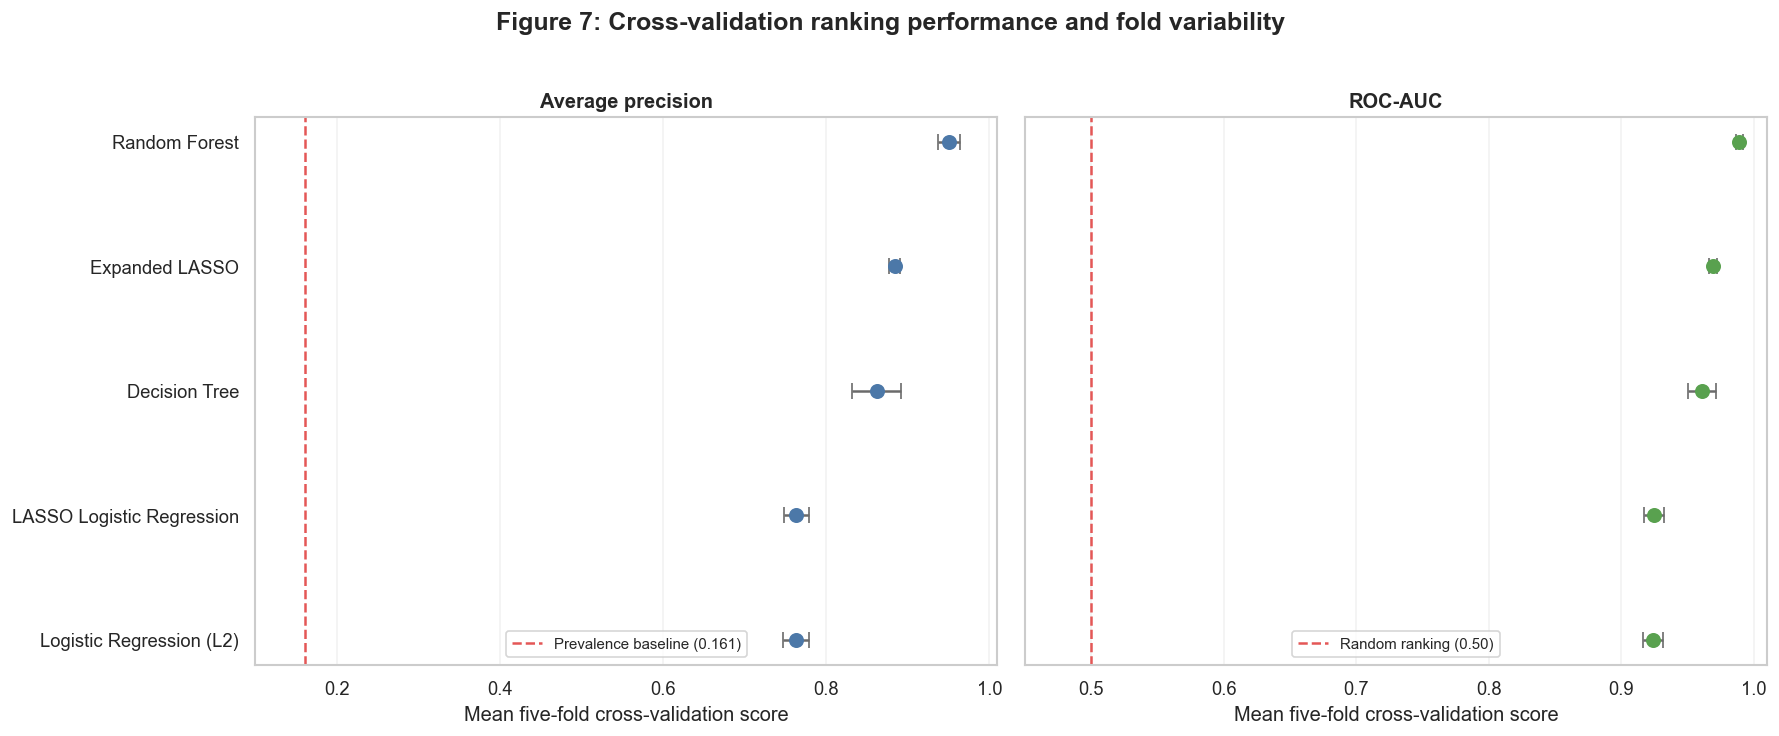

In [68]:
plot_data = validation_diagnostics.sort_values(
    "Mean_Validation_Average_Precision",
    ascending=True
)

training_churn_prevalence = y_train.mean()

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6),
    sharey=True
)

# Average-precision panel
axes[0].errorbar(
    x=plot_data[
        "Mean_Validation_Average_Precision"
    ],
    y=plot_data["Model"],
    xerr=plot_data[
        "Validation_Average_Precision_SD"
    ],
    fmt="o",
    markersize=8,
    capsize=5,
    color="#4C78A8",
    ecolor="#6B6B6B"
)

axes[0].axvline(
    training_churn_prevalence,
    color="#E45756",
    linestyle="--",
    linewidth=1.5,
    label=(
        "Prevalence baseline "
        f"({training_churn_prevalence:.3f})"
    )
)

axes[0].set_title(
    "Average precision",
    fontweight="bold"
)
axes[0].set_xlabel(
    "Mean five-fold cross-validation score"
)
axes[0].set_ylabel("")
axes[0].set_xlim(0.10, 1.01)
axes[0].legend(fontsize=9)
axes[0].grid(axis="x", alpha=0.25)
axes[0].grid(axis="y", visible=False)

# ROC-AUC panel
axes[1].errorbar(
    x=plot_data["Mean_Validation_ROC_AUC"],
    y=plot_data["Model"],
    xerr=plot_data["Validation_ROC_AUC_SD"],
    fmt="o",
    markersize=8,
    capsize=5,
    color="#59A14F",
    ecolor="#6B6B6B"
)

axes[1].axvline(
    0.5,
    color="#E45756",
    linestyle="--",
    linewidth=1.5,
    label="Random ranking (0.50)"
)

axes[1].set_title(
    "ROC-AUC",
    fontweight="bold"
)
axes[1].set_xlabel(
    "Mean five-fold cross-validation score"
)
axes[1].set_ylabel("")
axes[1].set_xlim(0.45, 1.01)
axes[1].legend(fontsize=9)
axes[1].grid(axis="x", alpha=0.25)
axes[1].grid(axis="y", visible=False)

fig.suptitle(
    "Figure 7: Cross-validation ranking performance "
    "and fold variability",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.savefig(
    "figure_7_cross_validation_ranking_metrics.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 7.1 Cross-validation comparison

Random Forest produced the strongest cross-validation ranking performance, with mean average precision of 0.9502 (SD = 0.0133) and mean ROC-AUC of 0.9890 (SD = 0.0028). Expanded LASSO ranked second by average precision at 0.8839, followed by Decision Tree at 0.8620. Main-effects LASSO and L2 Logistic Regression both produced average precision of 0.7634 when rounded to four decimal places.

The Random Forest also achieved the strongest default-threshold performance, including accuracy of 0.9622, balanced accuracy of 0.9145, attrited-customer precision of 0.9145, recall of 0.8441, and F1-score of 0.8777. Its improvement was therefore not confined to one ranking measure. Random Forest exceeded expanded LASSO in mean average precision by 0.0663 and Decision Tree by 0.0882, while also outperforming both across the reported threshold-dependent metrics.

The expanded-LASSO experiment demonstrates that the weaker performance of the original linear models was partly attributable to their additive main-effects specification rather than linear classification alone. Introducing squared numerical terms and pairwise interactions increased average precision from 0.7634 to 0.8839 and ROC-AUC from 0.9248 to 0.9690. However, this improvement increased the number of active coefficients from 17 to 101 and reduced sparsity from 46.88% to 26.28%. The predictive gain therefore came at a substantial cost to structural simplicity and complete-model understandability.

The main-effects LASSO and L2 Logistic Regression produced almost indistinguishable predictive performance. Their identical rounded average precision and very small differences across the remaining metrics do not provide evidence of practically meaningful predictive superiority for either specification. Main-effects LASSO’s comparative value instead lies in reducing the fitted coefficient set from 32 transformed features to 17 active terms.

Decision Tree provided materially stronger performance than the two main-effects linear models and retained the ability to trace an individual prediction through one path. However, its fitted structure contained 137 nodes and 69 terminal leaves, limiting the practical understandability of the complete tree. Random Forest increased predictive performance further but contained 156,040 nodes across 300 component trees, making complete-model inspection infeasible.

The fold-level standard deviations and training–validation gaps provide useful diagnostics but do not constitute formal tests of performance differences. Furthermore, these cross-validation results were used to select hyperparameters and may be optimistic as generalisation estimates. They identify Random Forest as the leading candidate from the training-stage evidence, but final conclusions must be based on the single held-out test-set evaluation, classification-error counts, probability quality, and the required balance between predictive performance and understandability.


## 8. Final Held-Out Test Evaluation

Following completion of training-stage preprocessing, hyperparameter tuning, expanded-LASSO assessment, and cross-validation comparison, the four primary models are evaluated once on the held-out test set. The supplementary expanded-LASSO specification is also evaluated to determine whether its cross-validated improvement over main-effects LASSO generalises to unseen observations.

The test set has not been used to estimate scaling or encoding parameters, select class weights, tune model hyperparameters, choose candidate specifications, or determine classification thresholds. Each selected pipeline was refitted on the complete training partition before being applied unchanged to the test predictors. No model configuration will be revised in response to the test results.

All specifications are initially evaluated at the conventional probability threshold of 0.50. The reported measures include accuracy, balanced accuracy, attrited-customer precision, recall and F1-score, specificity, ROC-AUC, average precision, trapezoidal precision–recall AUC, Brier score, log loss, and the complete confusion-matrix counts of true negatives, false positives, false negatives, and true positives.

Classification-error counts receive particular attention because false negatives represent attrited customers whom the model fails to identify, while false positives represent existing customers who could receive unnecessary retention attention. These errors have different potential managerial consequences and cannot be understood from aggregate discrimination measures alone.

The held-out results provide the final comparative evidence for this sample. However, they remain conditional on the retrospective cross-sectional dataset, the full-sample descriptive assessment conducted before partitioning, and the absence of documented predictor timing. They should therefore be interpreted as evidence of retrospective classification performance rather than verified prospective forecasting performance.


In [69]:
selected_models = {
    "Logistic Regression (L2)":
        best_logistic_model,
    "LASSO Logistic Regression":
        best_lasso_model,
    "Expanded LASSO":
        best_expanded_lasso_model,
    "Decision Tree":
        best_decision_tree_model,
    "Random Forest":
        best_random_forest_model
}

test_evaluation_records = []
test_predictions = {}

for model_name, model in selected_models.items():
    predicted_class = model.predict(
        X_test
    )

    predicted_probability = model.predict_proba(
        X_test
    )[:, POSITIVE_CLASS]

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predicted_class,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    false_positive_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    false_negative_rate = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else np.nan
    )

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_test,
            predicted_probability
        )
    )

    trapezoidal_pr_auc = auc(
        recall_curve,
        precision_curve
    )

    test_evaluation_records.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_test,
            predicted_class
        ),
        "Balanced_Accuracy":
            balanced_accuracy_score(
                y_test,
                predicted_class
            ),
        "Attrited_Customer_Precision":
            precision_score(
                y_test,
                predicted_class,
                pos_label=POSITIVE_CLASS,
                zero_division=0
            ),
        "Attrited_Customer_Recall":
            recall_score(
                y_test,
                predicted_class,
                pos_label=POSITIVE_CLASS,
                zero_division=0
            ),
        "Specificity": specificity,
        "Attrited_Customer_F1":
            f1_score(
                y_test,
                predicted_class,
                pos_label=POSITIVE_CLASS,
                zero_division=0
            ),
        "ROC_AUC": roc_auc_score(
            y_test,
            predicted_probability
        ),
        "Average_Precision":
            average_precision_score(
                y_test,
                predicted_probability
            ),
        "Trapezoidal_PR_AUC":
            trapezoidal_pr_auc,
        "Brier_Score": brier_score_loss(
            y_test,
            predicted_probability
        ),
        "Log_Loss": log_loss(
            y_test,
            predicted_probability,
            labels=[0, 1]
        ),
        "True_Negatives": int(tn),
        "False_Positives": int(fp),
        "False_Negatives": int(fn),
        "True_Positives": int(tp),
        "Predicted_Attrited_Customers":
            int(fp + tp),
        "False_Positive_Rate":
            false_positive_rate,
        "False_Negative_Rate":
            false_negative_rate
    })

    test_predictions[model_name] = {
        "Predicted_Class":
            predicted_class.copy(),
        "Predicted_Probability":
            predicted_probability.copy()
    }

test_results = (
    pd.DataFrame(test_evaluation_records)
    .sort_values(
        "Average_Precision",
        ascending=False
    )
    .reset_index(drop=True)
)

test_results.insert(
    1,
    "Average_Precision_Rank",
    np.arange(1, len(test_results) + 1)
)

test_metric_columns = [
    "Accuracy",
    "Balanced_Accuracy",
    "Attrited_Customer_Precision",
    "Attrited_Customer_Recall",
    "Specificity",
    "Attrited_Customer_F1",
    "ROC_AUC",
    "Average_Precision",
    "Trapezoidal_PR_AUC",
    "Brier_Score",
    "Log_Loss",
    "False_Positive_Rate",
    "False_Negative_Rate"
]

test_results[test_metric_columns] = (
    test_results[test_metric_columns]
    .round(4)
)

display(test_results)

test_results.to_csv(
    "table_final_test_model_evaluation.csv",
    index=False
)

print(
    "Final held-out test evaluation completed for "
    f"{len(selected_models)} model specifications."
)
print(
    "Results saved as "
    "'table_final_test_model_evaluation.csv'."
)

,Model,Average_Precision_Rank,Accuracy,Balanced_Accuracy,Attrited_Customer_Precision,Attrited_Customer_Recall,Specificity,Attrited_Customer_F1,ROC_AUC,Average_Precision,Trapezoidal_PR_AUC,Brier_Score,Log_Loss,True_Negatives,False_Positives,False_Negatives,True_Positives,Predicted_Attrited_Customers,False_Positive_Rate,False_Negative_Rate
0,Random Forest,1,0.964,0.913,0.925,0.840,0.987,0.881,0.988,0.950,0.950,0.030,0.108,1679,22,52,273,295,0.013,0.160
1,Expanded LASSO,2,0.931,0.840,0.842,0.705,0.975,0.767,0.961,0.867,0.867,0.050,0.173,1658,43,96,229,272,0.025,0.295
2,Decision Tree,3,0.944,0.895,0.829,0.822,0.968,0.825,0.960,0.865,0.876,0.043,0.387,1646,55,58,267,322,0.032,0.178
3,Logistic Regression (L2),4,0.900,0.748,0.783,0.523,0.972,0.627,0.914,0.734,0.733,0.074,0.248,1654,47,155,170,217,0.028,0.477
4,LASSO Logistic Regression,5,0.900,0.745,0.785,0.517,0.973,0.623,0.915,0.733,0.733,0.074,0.247,1655,46,157,168,214,0.027,0.483


Final held-out test evaluation completed for 5 model specifications.
Results saved as 'table_final_test_model_evaluation.csv'.


### 8.1 Final model-performance findings

Random Forest achieved the strongest held-out performance across the principal discrimination, classification, and probability-quality measures. It produced accuracy of 0.964, balanced accuracy of 0.913, attrited-customer precision of 0.925, recall of 0.840, F1-score of 0.881, ROC-AUC of 0.988, and average precision of 0.950. Its Brier score of 0.030 and log loss of 0.108 were also the lowest among the evaluated specifications, indicating the strongest overall probability quality.

At the default threshold of 0.50, Random Forest correctly identified 273 of the 325 attrited customers and missed 52. It generated 22 false-positive alerts among 1,701 existing customers, producing specificity of 0.987 and a false-positive rate of 0.013. A total of 295 customers were classified as attrited. This error profile indicates that the model combined comparatively high churn detection with a limited number of unnecessary retention alerts.

Decision Tree produced the second-highest default-threshold classification performance. It achieved accuracy of 0.944, balanced accuracy of 0.895, precision of 0.829, recall of 0.822, and F1-score of 0.825. It correctly identified 267 attrited customers, missed 58, and generated 55 false positives. Compared with Random Forest, Decision Tree detected six fewer attrited customers and generated 33 additional false-positive alerts.

Expanded LASSO achieved ROC-AUC of 0.961 and average precision of 0.867, closely resembling the Decision Tree’s ROC-AUC of 0.960 and average precision of 0.865. These differences are only 0.001 and 0.002 respectively and should not be interpreted as meaningful superiority. However, their default-threshold error profiles differed. Expanded LASSO identified 229 attrited customers and missed 96, whereas Decision Tree identified 267 and missed 58. Decision Tree therefore detected 38 additional attrited customers but produced 12 additional false positives. Expanded LASSO had better log loss than Decision Tree, at 0.173 compared with 0.387, while Decision Tree had a lower Brier score of 0.043 compared with 0.050. The comparatively high Decision Tree log loss suggests that some incorrect probability estimates were highly confident.

The expanded-LASSO experiment confirmed that the addition of numerical squared and interaction terms improved performance beyond the main-effects linear models. Its average precision of 0.867 exceeded the 0.734 achieved by L2 Logistic Regression and the 0.733 achieved by main-effects LASSO. Its recall of 0.705 also exceeded their respective recall values of 0.523 and 0.517. Nevertheless, the expanded model remained below Random Forest across every principal test metric while requiring 101 active coefficients.

L2 Logistic Regression and main-effects LASSO again produced nearly identical results. Both achieved accuracy of 0.900, while their ROC-AUC values were 0.914 and 0.915 and their average-precision values were 0.734 and 0.733 respectively. L2 Logistic Regression identified 170 attrited customers and missed 155; main-effects LASSO identified 168 and missed 157. These very small differences provide no evidence of practically meaningful predictive superiority. Main-effects LASSO’s advantage remains its sparser 17-term coefficient structure rather than stronger test performance.

Overall, Random Forest provides the strongest evidence of held-out predictive performance at the default threshold. It achieved the highest attrited-customer detection among the evaluated specifications while also producing the fewest false positives and the best probability-quality scores. This result does not remove the interpretability trade-off: the ensemble remains substantially more complex and less completely understandable than the fitted linear models or a single Decision Tree. Furthermore, conclusions are based on one held-out sample and should not be interpreted as evidence of causal relationships or guaranteed prospective forecasting performance.


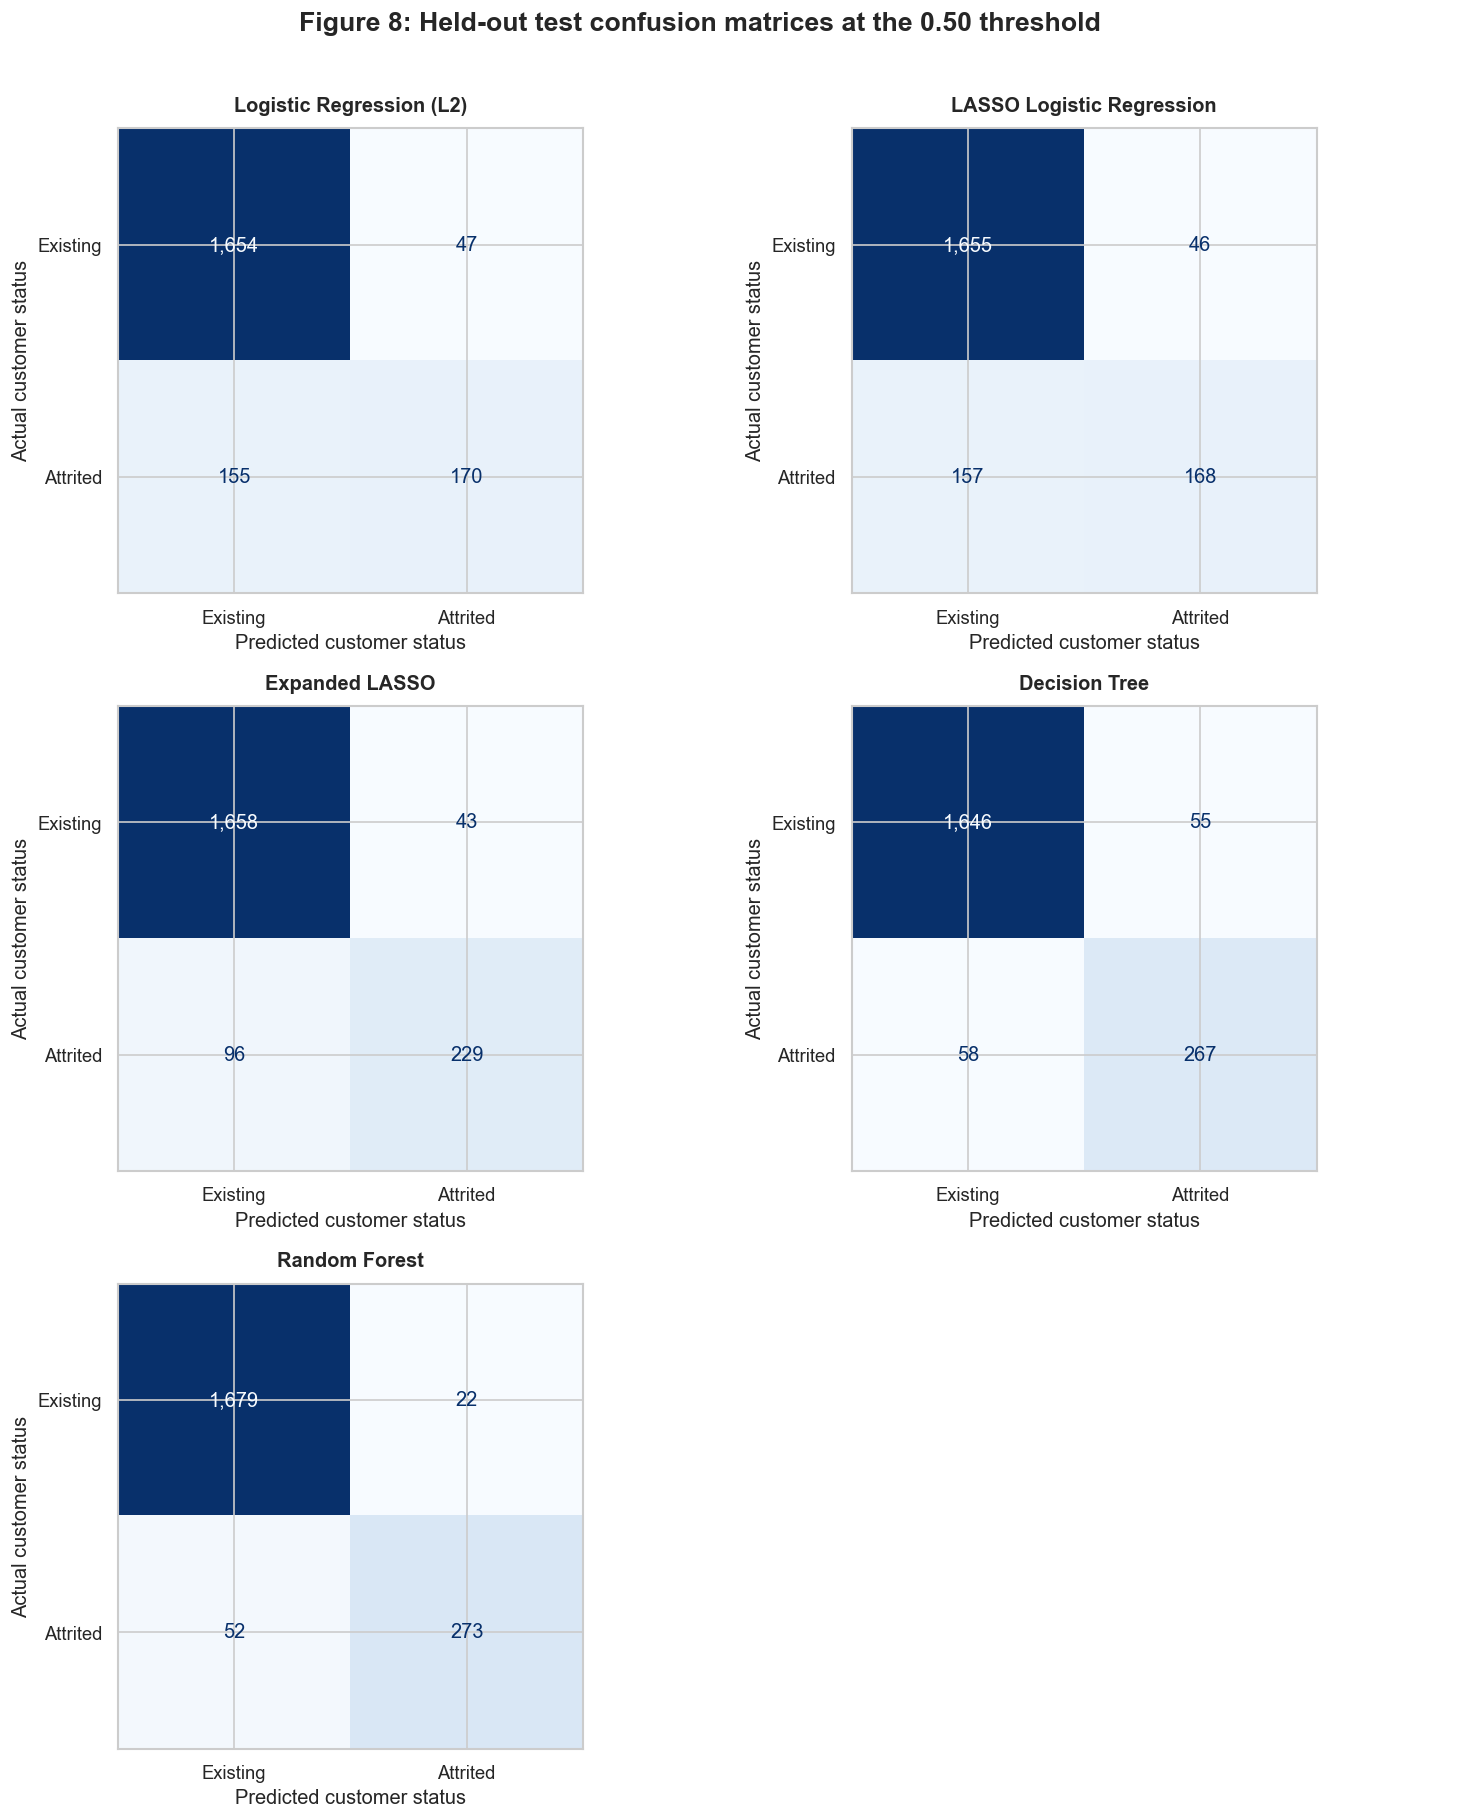

In [70]:
fig, axes = plt.subplots(
    3,
    2,
    figsize=(13, 15)
)

axes = axes.flatten()

for ax, model_name in zip(
    axes,
    selected_models.keys()
):
    predicted_class = test_predictions[
        model_name
    ]["Predicted_Class"]

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicted_class,
        labels=[0, 1],
        display_labels=[
            "Existing",
            "Attrited"
        ],
        cmap="Blues",
        colorbar=False,
        values_format=",d",
        ax=ax
    )

    ax.set_title(
        model_name,
        fontsize=12,
        fontweight="bold",
        pad=10
    )
    ax.set_xlabel("Predicted customer status")
    ax.set_ylabel("Actual customer status")

# Hide the unused sixth panel
for unused_ax in axes[len(selected_models):]:
    unused_ax.axis("off")

fig.suptitle(
    "Figure 8: Held-out test confusion matrices "
    "at the 0.50 threshold",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

plt.savefig(
    "figure_8_test_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

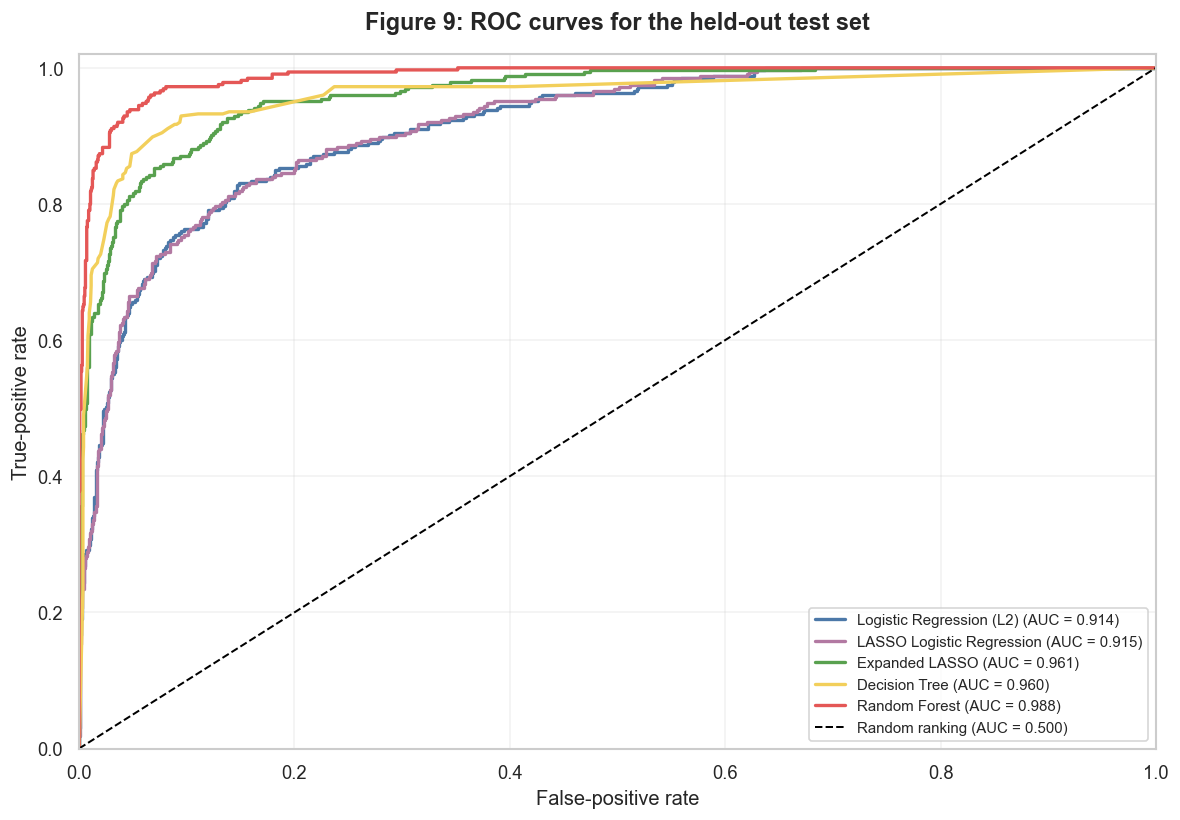

In [71]:
model_colours = {
    "Logistic Regression (L2)": "#4C78A8",
    "LASSO Logistic Regression": "#B279A2",
    "Expanded LASSO": "#59A14F",
    "Decision Tree": "#F2CF5B",
    "Random Forest": "#E45756"
}

fig, ax = plt.subplots(figsize=(10, 7))

for model_name in selected_models:
    predicted_probability = test_predictions[
        model_name
    ]["Predicted_Probability"]

    false_positive_rate, true_positive_rate, _ = (
        roc_curve(
            y_test,
            predicted_probability
        )
    )

    model_roc_auc = roc_auc_score(
        y_test,
        predicted_probability
    )

    ax.plot(
        false_positive_rate,
        true_positive_rate,
        color=model_colours[model_name],
        linewidth=2,
        label=(
            f"{model_name} "
            f"(AUC = {model_roc_auc:.3f})"
        )
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.2,
    label="Random ranking (AUC = 0.500)"
)

ax.set_title(
    "Figure 9: ROC curves for the held-out test set",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("False-positive rate")
ax.set_ylabel("True-positive rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(
    loc="lower right",
    fontsize=9
)
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "figure_9_test_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

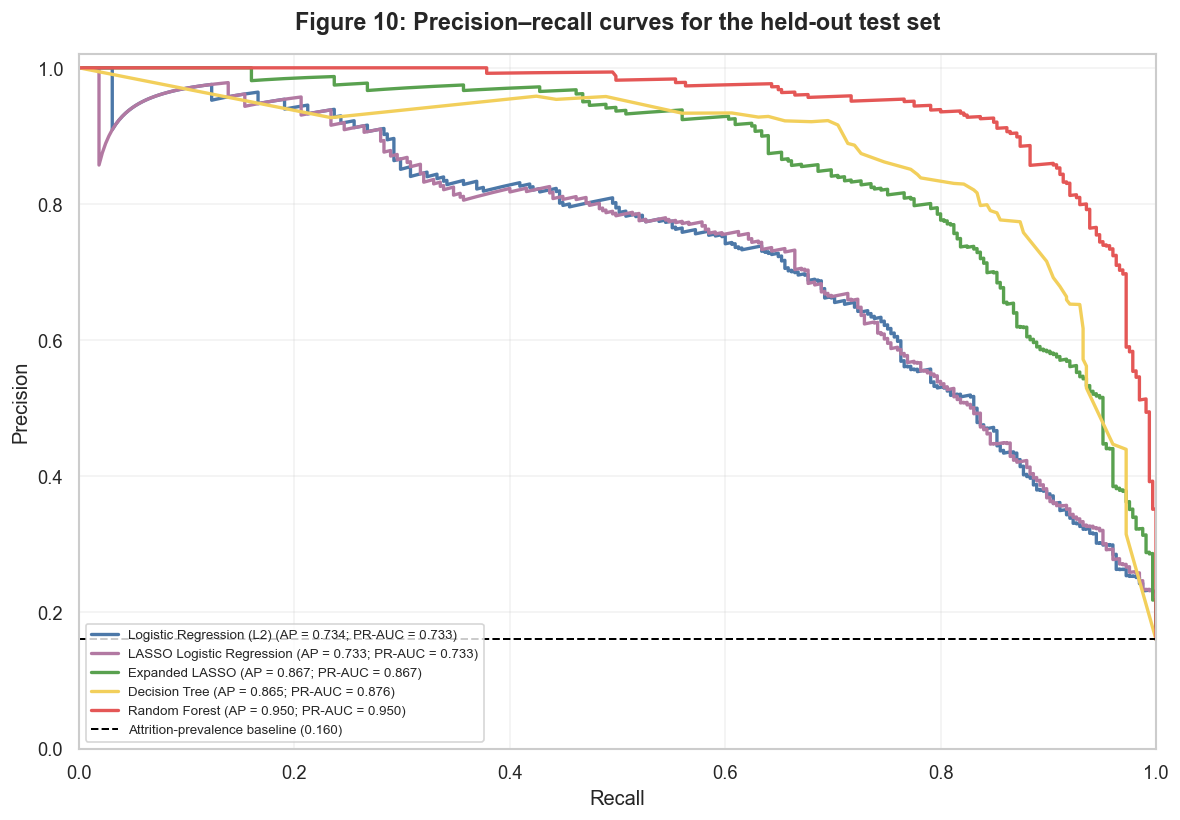

In [72]:
fig, ax = plt.subplots(figsize=(10, 7))

for model_name in selected_models:
    predicted_probability = test_predictions[
        model_name
    ]["Predicted_Probability"]

    precision_values, recall_values, _ = (
        precision_recall_curve(
            y_test,
            predicted_probability
        )
    )

    model_average_precision = (
        average_precision_score(
            y_test,
            predicted_probability
        )
    )

    model_trapezoidal_pr_auc = auc(
        recall_values,
        precision_values
    )

    ax.plot(
        recall_values,
        precision_values,
        color=model_colours[model_name],
        linewidth=2,
        label=(
            f"{model_name} "
            f"(AP = {model_average_precision:.3f}; "
            f"PR-AUC = {model_trapezoidal_pr_auc:.3f})"
        )
    )

test_churn_prevalence = y_test.mean()

ax.axhline(
    y=test_churn_prevalence,
    linestyle="--",
    color="black",
    linewidth=1.2,
    label=(
        "Attrition-prevalence baseline "
        f"({test_churn_prevalence:.3f})"
    )
)

ax.set_title(
    "Figure 10: Precision–recall curves for the "
    "held-out test set",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(
    loc="lower left",
    fontsize=8
)

ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "figure_10_test_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 8.2 Performance uncertainty

The held-out test results are point estimates calculated from one sample of 2,026 customers and are therefore subject to sampling uncertainty. Non-parametric bootstrap resampling is used to estimate percentile-based 95% confidence intervals for ROC-AUC, average precision, balanced accuracy, attrited-customer precision, recall, and F1-score.

Each bootstrap sample draws test-set indices with replacement and retains the pairing between actual outcomes, predicted classes, and predicted probabilities. Samples containing only one outcome class are excluded because ROC-AUC cannot be calculated for them. The models are not refitted during this process; the procedure estimates uncertainty in performance on samples drawn from the observed held-out data.

The same bootstrap indices are applied to every model, enabling paired comparisons of performance differences. This is particularly important when point estimates are close because an observed difference does not necessarily demonstrate a reliable performance advantage. Confidence intervals for the differences between Random Forest and the alternative specifications are therefore reported alongside the model-specific intervals.

These bootstrap intervals quantify uncertainty associated with the available held-out sample. They do not account for uncertainty created by dataset selection, model-development choices, undocumented predictor timing, population change, or deployment in a different banking environment. They are used for uncertainty assessment only and do not inform further model tuning.


In [73]:
BOOTSTRAP_ITERATIONS = 2000

bootstrap_random_generator = np.random.default_rng(
    RANDOM_STATE
)

y_test_array = y_test.to_numpy()
number_of_test_observations = len(y_test_array)

bootstrap_metric_names = [
    "ROC_AUC",
    "Average_Precision",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "F1"
]

bootstrap_scores = {
    model_name: {
        metric_name: []
        for metric_name in bootstrap_metric_names
    }
    for model_name in selected_models
}

valid_bootstrap_samples = 0

for _ in range(BOOTSTRAP_ITERATIONS):
    sampled_indices = (
        bootstrap_random_generator.integers(
            low=0,
            high=number_of_test_observations,
            size=number_of_test_observations
        )
    )

    sampled_y = y_test_array[sampled_indices]

    # ROC-AUC requires both outcome classes
    if np.unique(sampled_y).size < 2:
        continue

    valid_bootstrap_samples += 1

    for model_name in selected_models:
        sampled_probability = (
            test_predictions[model_name][
                "Predicted_Probability"
            ][sampled_indices]
        )

        sampled_class = (
            test_predictions[model_name][
                "Predicted_Class"
            ][sampled_indices]
        )

        bootstrap_scores[model_name][
            "ROC_AUC"
        ].append(
            roc_auc_score(
                sampled_y,
                sampled_probability
            )
        )

        bootstrap_scores[model_name][
            "Average_Precision"
        ].append(
            average_precision_score(
                sampled_y,
                sampled_probability
            )
        )

        bootstrap_scores[model_name][
            "Balanced_Accuracy"
        ].append(
            balanced_accuracy_score(
                sampled_y,
                sampled_class
            )
        )

        bootstrap_scores[model_name][
            "Precision"
        ].append(
            precision_score(
                sampled_y,
                sampled_class,
                pos_label=POSITIVE_CLASS,
                zero_division=0
            )
        )

        bootstrap_scores[model_name][
            "Recall"
        ].append(
            recall_score(
                sampled_y,
                sampled_class,
                pos_label=POSITIVE_CLASS,
                zero_division=0
            )
        )

        bootstrap_scores[model_name][
            "F1"
        ].append(
            f1_score(
                sampled_y,
                sampled_class,
                pos_label=POSITIVE_CLASS,
                zero_division=0
            )
        )


# Model-specific percentile confidence intervals
bootstrap_interval_records = []

for model_name in selected_models:
    for metric_name in bootstrap_metric_names:
        metric_values = np.asarray(
            bootstrap_scores[model_name][metric_name]
        )

        bootstrap_interval_records.append({
            "Model": model_name,
            "Metric": metric_name,
            "Bootstrap_Mean":
                metric_values.mean(),
            "Lower_95_CI":
                np.percentile(
                    metric_values,
                    2.5
                ),
            "Upper_95_CI":
                np.percentile(
                    metric_values,
                    97.5
                ),
            "Valid_Bootstrap_Samples":
                len(metric_values)
        })

bootstrap_confidence_intervals = (
    pd.DataFrame(bootstrap_interval_records)
    .round({
        "Bootstrap_Mean": 4,
        "Lower_95_CI": 4,
        "Upper_95_CI": 4
    })
)

display(bootstrap_confidence_intervals)


# Paired differences: Random Forest minus each alternative
REFERENCE_MODEL = "Random Forest"

paired_difference_records = []

for comparison_model in selected_models:
    if comparison_model == REFERENCE_MODEL:
        continue

    for metric_name in bootstrap_metric_names:
        reference_values = np.asarray(
            bootstrap_scores[
                REFERENCE_MODEL
            ][metric_name]
        )

        comparison_values = np.asarray(
            bootstrap_scores[
                comparison_model
            ][metric_name]
        )

        paired_differences = (
            reference_values - comparison_values
        )

        paired_difference_records.append({
            "Reference_Model": REFERENCE_MODEL,
            "Comparison_Model": comparison_model,
            "Metric": metric_name,
            "Mean_Difference":
                paired_differences.mean(),
            "Lower_95_CI":
                np.percentile(
                    paired_differences,
                    2.5
                ),
            "Upper_95_CI":
                np.percentile(
                    paired_differences,
                    97.5
                ),
            "CI_Excludes_Zero": bool(
                (
                    np.percentile(
                        paired_differences,
                        2.5
                    ) > 0
                )
                or (
                    np.percentile(
                        paired_differences,
                        97.5
                    ) < 0
                )
            )
        })

paired_bootstrap_differences = (
    pd.DataFrame(paired_difference_records)
    .round({
        "Mean_Difference": 4,
        "Lower_95_CI": 4,
        "Upper_95_CI": 4
    })
)

display(paired_bootstrap_differences)

print(
    f"Valid bootstrap samples: "
    f"{valid_bootstrap_samples:,} of "
    f"{BOOTSTRAP_ITERATIONS:,}"
)

bootstrap_confidence_intervals.to_csv(
    "table_bootstrap_performance_intervals.csv",
    index=False
)

paired_bootstrap_differences.to_csv(
    "table_paired_bootstrap_model_differences.csv",
    index=False
)

print(
    "Bootstrap confidence intervals and paired "
    "model differences saved successfully."
)

,Model,Metric,Bootstrap_Mean,Lower_95_CI,Upper_95_CI,Valid_Bootstrap_Samples
0,Logistic Regression (L2),ROC_AUC,0.914,0.898,0.930,2000
1,Logistic Regression (L2),Average_Precision,0.735,0.687,0.780,2000
2,Logistic Regression (L2),Balanced_Accuracy,0.748,0.721,0.775,2000
3,Logistic Regression (L2),Precision,0.785,0.727,0.839,2000
4,Logistic Regression (L2),Recall,0.524,0.471,0.578,2000
5,Logistic Regression (L2),F1,0.628,0.579,0.675,2000
6,LASSO Logistic Regression,ROC_AUC,0.915,0.900,0.931,2000
7,LASSO Logistic Regression,Average_Precision,0.735,0.686,0.780,2000
8,LASSO Logistic Regression,Balanced_Accuracy,0.745,0.718,0.773,2000
9,LASSO Logistic Regression,Precision,0.786,0.731,0.842,2000


,Reference_Model,Comparison_Model,Metric,Mean_Difference,Lower_95_CI,Upper_95_CI,CI_Excludes_Zero
0,Random Forest,Logistic Regression (L2),ROC_AUC,0.073,0.059,0.089,True
1,Random Forest,Logistic Regression (L2),Average_Precision,0.215,0.175,0.259,True
2,Random Forest,Logistic Regression (L2),Balanced_Accuracy,0.166,0.138,0.193,True
3,Random Forest,Logistic Regression (L2),Precision,0.141,0.090,0.194,True
4,Random Forest,Logistic Regression (L2),Recall,0.316,0.262,0.371,True
5,Random Forest,Logistic Regression (L2),F1,0.253,0.209,0.300,True
6,Random Forest,LASSO Logistic Regression,ROC_AUC,0.072,0.058,0.087,True
7,Random Forest,LASSO Logistic Regression,Average_Precision,0.216,0.175,0.260,True
8,Random Forest,LASSO Logistic Regression,Balanced_Accuracy,0.168,0.140,0.196,True
9,Random Forest,LASSO Logistic Regression,Precision,0.140,0.088,0.195,True


Valid bootstrap samples: 2,000 of 2,000
Bootstrap confidence intervals and paired model differences saved successfully.


### 8.3 Comparative evaluation

The ROC and precision–recall curves confirm that Random Forest achieved the strongest ranking performance on the held-out test observations. Its ROC-AUC of 0.988 and average precision of 0.950 substantially exceeded the test-set attrition prevalence of approximately 0.160. Random Forest also produced the best probability-quality results, with the lowest Brier score of 0.030 and log loss of 0.108.

At the common threshold of 0.50, Random Forest achieved the highest accuracy, balanced accuracy, attrited-customer precision, recall, and F1-score among the evaluated specifications. It also produced the most favourable error counts, with 22 false positives and 52 false negatives. Decision Tree was the closest threshold-based alternative but generated 55 false positives and 58 false negatives. Therefore, within this held-out sample and at this threshold, Random Forest did not obtain higher precision by sacrificing recall; it outperformed the alternatives on both measures.

Expanded LASSO and Decision Tree produced nearly identical ranking results, with respective average-precision values of 0.867 and 0.865 and ROC-AUC values of 0.961 and 0.960. These small differences should not be interpreted as practically meaningful in isolation. Their classification profiles differed more clearly: Decision Tree achieved recall of 0.822 compared with 0.705 for expanded LASSO, while expanded LASSO generated 43 false positives compared with 55 for Decision Tree. The choice between these two models would therefore depend more on the consequences of missed churners, unnecessary interventions, probability quality, and fitted-model understandability than on their almost identical ranking measures.

The paired bootstrap analysis provides uncertainty intervals for the observed model differences. These intervals must be considered alongside the point estimates because small differences may be compatible with sampling variation. Even where a paired interval excludes zero, the result applies only to resamples of the present held-out dataset and does not establish superiority across different banks, customer populations, or future periods.

Random Forest is consequently identified as the strongest predictive candidate at the default threshold. However, the preferred operational threshold remains stakeholder-dependent. Lowering the threshold would ordinarily increase recall while generating more false-positive retention alerts, whereas raising it would generally increase selectivity while missing more attrited customers. A financially optimised threshold would require reliable estimates of customer lifetime value, intervention cost, offer acceptance, and the cost of undetected attrition, none of which are available in the secondary dataset. The 0.50 threshold is therefore retained as a consistent comparison point rather than presented as an economically optimal decision rule.


## 9. Predictor Importance and Model Understandability

Model interpretation is assessed using three practical dimensions: the complexity of the fitted model, whether the complete fitted model can be understood, and whether an individual prediction can be traced through the model’s decision process. These dimensions are evaluated separately because a model can be mathematically inspectable without being practically understandable.

Global predictor reliance is assessed using permutation importance. This model-agnostic procedure measures the reduction in held-out performance after randomly rearranging one original predictor while leaving the remaining predictors unchanged. Importance is calculated using both average precision and ROC-AUC so that the conclusions do not depend on one ranking metric. A larger performance reduction indicates that the fitted model relies more strongly on that predictor for distinguishing attrited from existing customers.

Permutation occurs at the original-column level before pipeline preprocessing. Consequently, each categorical predictor is permuted as a complete variable rather than as separate dummy indicators. For expanded LASSO, permuting one original numerical predictor also disrupts every squared or interaction term derived from that variable, producing an original-variable-level assessment rather than a separate importance value for every engineered term.

Permutation importance describes predictive reliance, not the direction of association and not a causal effect. Correlated predictors may divide or conceal importance because one variable can partially replace information removed from another. A small or negative value does not necessarily prove that a predictor is substantively irrelevant; it indicates that permuting the variable did not reduce the selected model’s held-out performance consistently under the specified scoring measure.

Permutation results are supplemented by fitted-model evidence. Coefficients and retained terms are examined for the linear models, realised nodes and leaves are examined for Decision Tree, and ensemble size is examined for Random Forest. Individual-prediction traceability is then considered in relation to the complete coefficient calculation, a single tree path, or the aggregation of decisions across the forest. Held-out permutation importance is used for post-hoc explanation only and does not trigger further model selection or tuning.


In [74]:
from sklearn.inspection import permutation_importance

PERMUTATION_REPEATS = 30

permutation_importance_tables = {}
all_permutation_importance_tables = []

permutation_scoring = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc"
}

for model_name, model in selected_models.items():
    print(
        f"Calculating permutation importance "
        f"for {model_name}..."
    )

    permutation_results = permutation_importance(
        estimator=model,
        X=X_test,
        y=y_test,
        scoring=permutation_scoring,
        n_repeats=PERMUTATION_REPEATS,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    average_precision_result = (
        permutation_results["average_precision"]
    )

    roc_auc_result = (
        permutation_results["roc_auc"]
    )

    importance_table = pd.DataFrame({
        "Model": model_name,
        "Feature": X_test.columns,
        "Mean_Average_Precision_Decrease":
            average_precision_result.importances_mean,
        "Average_Precision_Standard_Deviation":
            average_precision_result.importances_std,
        "Mean_ROC_AUC_Decrease":
            roc_auc_result.importances_mean,
        "ROC_AUC_Standard_Deviation":
            roc_auc_result.importances_std
    })

    importance_table[
        "Average_Precision_Rank"
    ] = (
        importance_table[
            "Mean_Average_Precision_Decrease"
        ]
        .rank(
            method="min",
            ascending=False
        )
        .astype(int)
    )

    importance_table[
        "ROC_AUC_Rank"
    ] = (
        importance_table[
            "Mean_ROC_AUC_Decrease"
        ]
        .rank(
            method="min",
            ascending=False
        )
        .astype(int)
    )

    importance_table = (
        importance_table
        .sort_values(
            [
                "Average_Precision_Rank",
                "Mean_Average_Precision_Decrease"
            ],
            ascending=[True, False]
        )
        .reset_index(drop=True)
    )

    importance_numeric_columns = (
        importance_table
        .select_dtypes(include=np.number)
        .columns
    )

    importance_table[
        importance_numeric_columns
    ] = (
        importance_table[
            importance_numeric_columns
        ].round(4)
    )

    permutation_importance_tables[
        model_name
    ] = importance_table

    all_permutation_importance_tables.append(
        importance_table
    )

    print(f"\nTop predictors for {model_name}:")
    display(
        importance_table[
            [
                "Feature",
                "Mean_Average_Precision_Decrease",
                "Mean_ROC_AUC_Decrease",
                "Average_Precision_Rank",
                "ROC_AUC_Rank"
            ]
        ].head(10)
    )

permutation_importance_combined = pd.concat(
    all_permutation_importance_tables,
    ignore_index=True
)

permutation_importance_combined.to_csv(
    "table_permutation_importance_all_models.csv",
    index=False
)

print(
    "Permutation-importance calculations completed "
    "for all selected specifications."
)
print(
    "Combined results saved as "
    "'table_permutation_importance_all_models.csv'."
)

Calculating permutation importance for Logistic Regression (L2)...

Top predictors for Logistic Regression (L2):


,Feature,Mean_Average_Precision_Decrease,Mean_ROC_AUC_Decrease,Average_Precision_Rank,ROC_AUC_Rank
0,Total_Trans_Ct,0.523,0.300,1,1
1,Total_Trans_Amt,0.168,0.056,2,2
2,Total_Revolving_Bal,0.087,0.024,3,4
3,Total_Ct_Chng_Q4_Q1,0.067,0.024,4,3
4,Total_Relationship_Count,0.065,0.019,5,5
5,Contacts_Count_12_mon,0.048,0.018,6,6
6,Months_Inactive_12_mon,0.036,0.013,7,7
7,Marital_Status,0.011,0.003,8,9
8,Gender,0.010,0.004,9,8
9,Income_Category,0.002,0.001,10,10


Calculating permutation importance for LASSO Logistic Regression...

Top predictors for LASSO Logistic Regression:


,Feature,Mean_Average_Precision_Decrease,Mean_ROC_AUC_Decrease,Average_Precision_Rank,ROC_AUC_Rank
0,Total_Trans_Ct,0.528,0.309,1,1
1,Total_Trans_Amt,0.181,0.060,2,2
2,Total_Revolving_Bal,0.098,0.029,3,3
3,Total_Ct_Chng_Q4_Q1,0.067,0.024,4,4
4,Total_Relationship_Count,0.065,0.019,5,5
5,Contacts_Count_12_mon,0.047,0.018,6,6
6,Months_Inactive_12_mon,0.034,0.013,7,7
7,Marital_Status,0.013,0.003,8,9
8,Gender,0.012,0.004,9,8
9,Months_on_book,0.001,0.000,10,11


Calculating permutation importance for Expanded LASSO...

Top predictors for Expanded LASSO:


,Feature,Mean_Average_Precision_Decrease,Mean_ROC_AUC_Decrease,Average_Precision_Rank,ROC_AUC_Rank
0,Total_Trans_Ct,0.660,0.381,1,1
1,Total_Trans_Amt,0.409,0.114,2,3
2,Avg_Utilization_Ratio,0.315,0.171,3,2
3,Credit_Limit,0.167,0.106,4,4
4,Total_Revolving_Bal,0.122,0.037,5,5
5,Total_Relationship_Count,0.081,0.015,6,6
6,Total_Ct_Chng_Q4_Q1,0.050,0.014,7,8
7,Total_Amt_Chng_Q4_Q1,0.046,0.014,8,7
8,Months_Inactive_12_mon,0.030,0.008,9,9
9,Contacts_Count_12_mon,0.021,0.006,10,10


Calculating permutation importance for Decision Tree...

Top predictors for Decision Tree:


,Feature,Mean_Average_Precision_Decrease,Mean_ROC_AUC_Decrease,Average_Precision_Rank,ROC_AUC_Rank
0,Total_Trans_Ct,0.586,0.296,1,1
1,Total_Trans_Amt,0.406,0.142,2,2
2,Total_Revolving_Bal,0.094,0.031,3,4
3,Total_Ct_Chng_Q4_Q1,0.084,0.040,4,3
4,Total_Relationship_Count,0.077,0.020,5,5
5,Customer_Age,0.044,0.005,6,8
6,Total_Amt_Chng_Q4_Q1,0.031,0.011,7,6
7,Credit_Limit,0.007,0.006,8,7
8,Income_Category,0.007,-0.001,9,19
9,Avg_Utilization_Ratio,0.006,0.001,10,11


Calculating permutation importance for Random Forest...

Top predictors for Random Forest:


,Feature,Mean_Average_Precision_Decrease,Mean_ROC_AUC_Decrease,Average_Precision_Rank,ROC_AUC_Rank
0,Total_Trans_Ct,0.486,0.190,1,1
1,Total_Trans_Amt,0.295,0.111,2,2
2,Total_Relationship_Count,0.084,0.017,3,3
3,Total_Revolving_Bal,0.060,0.017,4,4
4,Total_Ct_Chng_Q4_Q1,0.036,0.011,5,5
5,Total_Amt_Chng_Q4_Q1,0.023,0.007,6,6
6,Customer_Age,0.012,0.002,7,8
7,Contacts_Count_12_mon,0.008,0.002,8,9
8,Months_Inactive_12_mon,0.007,0.001,9,10
9,Avg_Utilization_Ratio,0.007,0.004,10,7


Permutation-importance calculations completed for all selected specifications.
Combined results saved as 'table_permutation_importance_all_models.csv'.


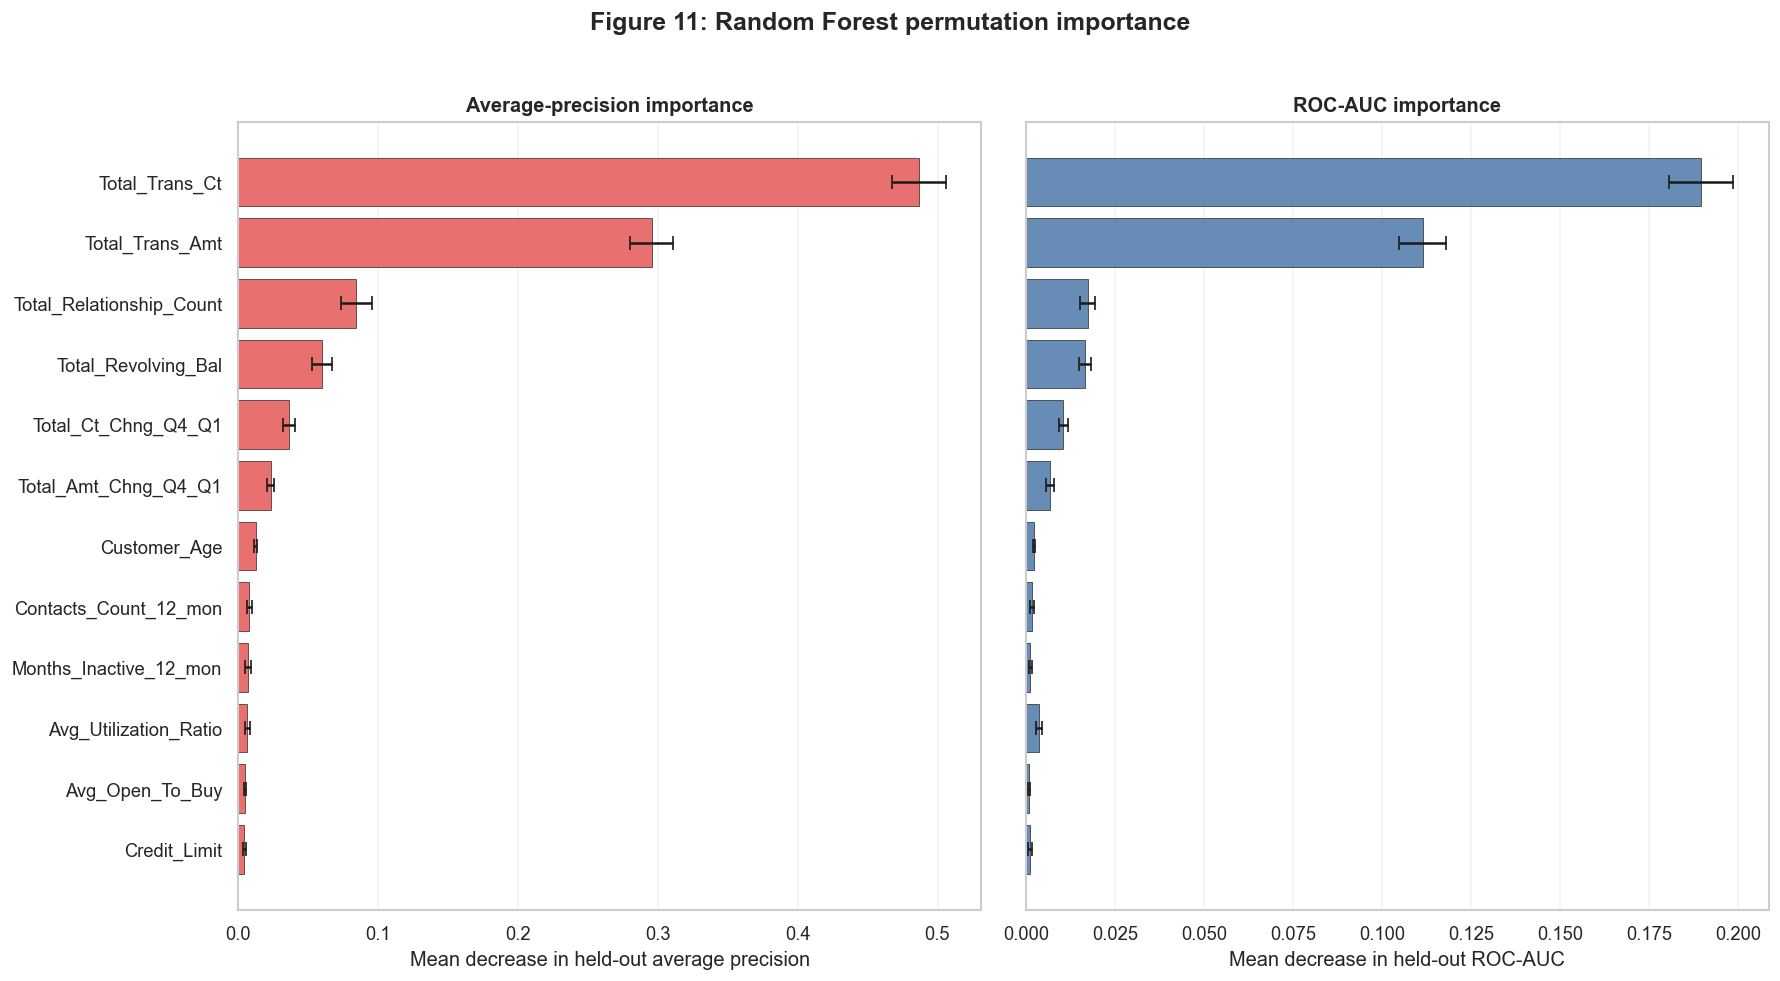

In [75]:
random_forest_importance = (
    permutation_importance_tables[
        "Random Forest"
    ]
    .head(12)
    .sort_values(
        "Mean_Average_Precision_Decrease",
        ascending=True
    )
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 8),
    sharey=True
)

axes[0].barh(
    random_forest_importance["Feature"],
    random_forest_importance[
        "Mean_Average_Precision_Decrease"
    ],
    xerr=random_forest_importance[
        "Average_Precision_Standard_Deviation"
    ],
    color="#E45756",
    alpha=0.85,
    capsize=4,
    edgecolor="black",
    linewidth=0.4
)

axes[0].axvline(
    x=0,
    color="black",
    linewidth=1
)

axes[0].set_title(
    "Average-precision importance",
    fontweight="bold"
)

axes[0].set_xlabel(
    "Mean decrease in held-out average precision"
)

axes[0].set_ylabel("")

axes[1].barh(
    random_forest_importance["Feature"],
    random_forest_importance[
        "Mean_ROC_AUC_Decrease"
    ],
    xerr=random_forest_importance[
        "ROC_AUC_Standard_Deviation"
    ],
    color="#4C78A8",
    alpha=0.85,
    capsize=4,
    edgecolor="black",
    linewidth=0.4
)

axes[1].axvline(
    x=0,
    color="black",
    linewidth=1
)

axes[1].set_title(
    "ROC-AUC importance",
    fontweight="bold"
)

axes[1].set_xlabel(
    "Mean decrease in held-out ROC-AUC"
)

axes[1].set_ylabel("")

for ax in axes:
    ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "Figure 11: Random Forest permutation importance",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    "figure_11_random_forest_permutation_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [76]:
cross_model_ranks = None

for model_name, importance_table in (
    permutation_importance_tables.items()
):
    model_ranks = importance_table[
        [
            "Feature",
            "Average_Precision_Rank",
            "ROC_AUC_Rank",
            "Mean_Average_Precision_Decrease",
            "Mean_ROC_AUC_Decrease"
        ]
    ].copy()

    model_ranks = model_ranks.rename(
        columns={
            "Average_Precision_Rank":
                f"{model_name}_AP_Rank",
            "ROC_AUC_Rank":
                f"{model_name}_ROC_AUC_Rank",
            "Mean_Average_Precision_Decrease":
                f"{model_name}_AP_Importance",
            "Mean_ROC_AUC_Decrease":
                f"{model_name}_ROC_AUC_Importance"
        }
    )

    if cross_model_ranks is None:
        cross_model_ranks = model_ranks
    else:
        cross_model_ranks = cross_model_ranks.merge(
            model_ranks,
            on="Feature",
            how="outer"
        )

ap_rank_columns = [
    column for column in cross_model_ranks.columns
    if column.endswith("_AP_Rank")
]

roc_auc_rank_columns = [
    column for column in cross_model_ranks.columns
    if column.endswith("_ROC_AUC_Rank")
]

cross_model_ranks[
    "Mean_Average_Precision_Rank"
] = cross_model_ranks[
    ap_rank_columns
].mean(axis=1)

cross_model_ranks[
    "Mean_ROC_AUC_Rank"
] = cross_model_ranks[
    roc_auc_rank_columns
].mean(axis=1)

cross_model_ranks["Overall_Mean_Rank"] = (
    cross_model_ranks[
        [
            "Mean_Average_Precision_Rank",
            "Mean_ROC_AUC_Rank"
        ]
    ]
    .mean(axis=1)
)

cross_model_ranks = (
    cross_model_ranks
    .sort_values(
        [
            "Overall_Mean_Rank",
            "Mean_Average_Precision_Rank"
        ]
    )
    .reset_index(drop=True)
)

cross_model_ranks[
    [
        "Mean_Average_Precision_Rank",
        "Mean_ROC_AUC_Rank",
        "Overall_Mean_Rank"
    ]
] = cross_model_ranks[
    [
        "Mean_Average_Precision_Rank",
        "Mean_ROC_AUC_Rank",
        "Overall_Mean_Rank"
    ]
].round(2)

cross_model_consensus = cross_model_ranks[
    [
        "Feature",
        "Mean_Average_Precision_Rank",
        "Mean_ROC_AUC_Rank",
        "Overall_Mean_Rank"
    ]
].copy()

display(cross_model_consensus.head(12))

cross_model_ranks.to_csv(
    "table_cross_model_permutation_importance_ranks.csv",
    index=False
)

print(
    "Cross-model permutation-importance rankings "
    "saved successfully."
)

,Feature,Mean_Average_Precision_Rank,Mean_ROC_AUC_Rank,Overall_Mean_Rank
0,Total_Trans_Ct,1.000,1.000,1.000
1,Total_Trans_Amt,2.000,2.200,2.100
2,Total_Revolving_Bal,3.600,4.000,3.800
3,Total_Ct_Chng_Q4_Q1,4.800,4.600,4.700
4,Total_Relationship_Count,4.800,4.800,4.800
5,Contacts_Count_12_mon,8.600,8.000,8.300
6,Total_Amt_Chng_Q4_Q1,9.400,8.000,8.700
7,Months_Inactive_12_mon,8.600,9.000,8.800
8,Credit_Limit,10.400,10.400,10.400
9,Avg_Utilization_Ratio,10.200,11.200,10.700


Cross-model permutation-importance rankings saved successfully.


In [77]:
for model_name, importance_table in (
    permutation_importance_tables.items()
):
    safe_model_name = (
        model_name
        .lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("-", "_")
    )

    importance_table.to_csv(
        (
            f"table_{safe_model_name}"
            "_permutation_importance.csv"
        ),
        index=False
    )

cross_model_consensus.to_csv(
    "table_cross_model_permutation_importance_consensus.csv",
    index=False
)

print(
    "Individual and cross-model permutation-importance "
    "tables saved successfully."
)

Individual and cross-model permutation-importance tables saved successfully.


### 9.1 Random Forest permutation-importance findings

Total transaction count was the most influential predictor in the fitted Random Forest under both evaluation metrics. Permuting this variable reduced held-out average precision by approximately 0.486 and ROC-AUC by approximately 0.190. Total transaction amount ranked second, with corresponding decreases of approximately 0.295 and 0.111. The substantially larger permutation effects of these two variables indicate that the model depended strongly on customers’ transaction activity when distinguishing attrited from existing customers.

Total relationship count ranked third under both metrics, reducing average precision by approximately 0.084 and ROC-AUC by approximately 0.017. Total revolving balance ranked fourth, with decreases of approximately 0.060 and 0.017. Changes in transaction count and transaction amount also contributed predictive information, producing average-precision decreases of approximately 0.036 and 0.023, respectively.

The remaining leading predictors had considerably smaller individual effects. Customer age reduced average precision by approximately 0.012 but ROC-AUC by only 0.002. Contacts with the bank during the previous 12 months, months inactive, average utilisation ratio, average open-to-buy and credit limit also displayed relatively limited importance. Demographic and account characteristics were therefore less influential than recent behavioural measures in the fitted Random Forest, although small permutation effects do not demonstrate that these variables are unrelated to attrition. Their information may overlap with correlated predictors, or the model may obtain similar information from other variables.

The agreement between the average-precision and ROC-AUC rankings strengthens the conclusion that transaction count and transaction amount were the dominant global predictors. Nevertheless, permutation importance measures the fitted model’s predictive dependence rather than causal influence. Furthermore, because the dataset does not document precisely when each predictor was observed relative to attrition, these variables should be interpreted as retrospective indicators of classification rather than verified prospective early-warning signals. Prospective or temporally ordered data would be required before concluding that changes in these measures can predict future churn or that intervening on them would prevent attrition.


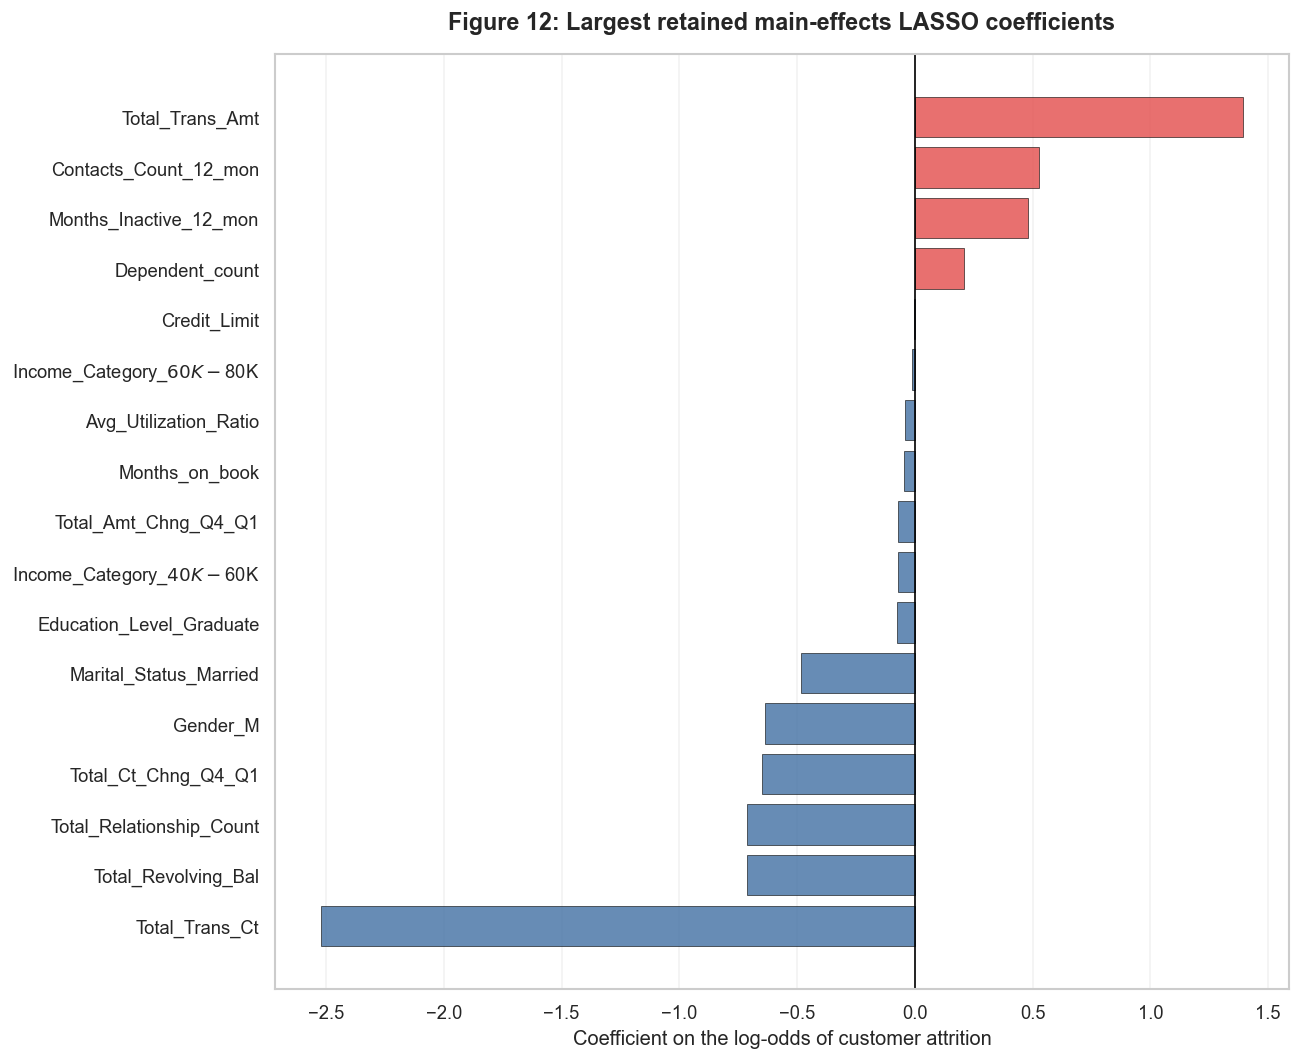

In [78]:
figure_12_feature_names = (
    best_lasso_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

figure_12_coefficients = (
    best_lasso_model
    .named_steps["classifier"]
    .coef_[0]
)

figure_12_table = pd.DataFrame({
    "Transformed_Feature":
        figure_12_feature_names,
    "Coefficient":
        figure_12_coefficients
})

figure_12_table["Absolute_Coefficient"] = (
    figure_12_table["Coefficient"].abs()
)

figure_12_table = figure_12_table[
    figure_12_table["Absolute_Coefficient"] > 1e-8
].copy()

figure_12_table["Display_Feature"] = (
    figure_12_table["Transformed_Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

plot_lasso_coefficients = (
    figure_12_table
    .nlargest(
        20,
        "Absolute_Coefficient"
    )
    .sort_values(
        "Coefficient",
        ascending=True
    )
)

coefficient_colours = [
    "#E45756" if value > 0
    else "#4C78A8"
    for value in plot_lasso_coefficients[
        "Coefficient"
    ]
]

fig, ax = plt.subplots(figsize=(11, 9))

ax.barh(
    plot_lasso_coefficients[
        "Display_Feature"
    ],
    plot_lasso_coefficients[
        "Coefficient"
    ],
    color=coefficient_colours,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.4
)

ax.axvline(
    x=0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Figure 12: Largest retained main-effects LASSO coefficients",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Coefficient on the log-odds of customer attrition"
)

ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)

plt.tight_layout()

plt.savefig(
    "figure_12_main_effects_lasso_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.2 Interpretation of LASSO coefficients

A positive LASSO coefficient indicates that the corresponding transformed term is associated with higher predicted log-odds of attrition, holding the other retained terms constant. A negative coefficient indicates an association with lower predicted attrition. These directions describe relationships within the fitted model and should not be interpreted as causal effects.

In the main-effects LASSO, numerical predictors were standardised; therefore, each numerical coefficient represents the change in predicted log-odds associated with a one-standard-deviation increase in that predictor. For categorical predictors, coefficients represent differences relative to the category omitted during one-hot encoding. This reference-category dependence means that categorical coefficients cannot be interpreted independently of the omitted group.

The main-effects LASSO retained 17 of 32 candidate transformed terms and reduced 15 coefficients to zero, producing sparsity of 46.88%. This provides a comparatively compact coefficient representation. However, coefficient magnitude and retention can be affected by regularisation, multicollinearity and the absence of explicitly modelled non-linear relationships. When predictors contain overlapping information, LASSO may retain one term while shrinking another to zero even when both are associated with attrition.

The expanded LASSO allowed numerical main effects, squared terms and pairwise numerical interactions. It retained 101 of 137 candidate terms, including 64 interaction terms and 10 squared terms, resulting in sparsity of 26.28%. Although this specification captured substantially more complex relationships and achieved stronger predictive performance than the main-effects LASSO, its much larger retained structure reduced complete-model understandability. Coefficients for interaction and squared terms must also be interpreted jointly with their associated main effects rather than as isolated relationships.

Consequently, LASSO sparsity represents structural simplification rather than definitive evidence that eliminated predictors are unrelated to customer attrition. The comparison also demonstrates that applying L1 regularisation does not automatically produce a simple model: interpretability depends on both the proportion of coefficients eliminated and the number and type of candidate terms supplied to the model.


### 9.3 Multidimensional model interpretability

Interpretability is not treated as one universally measurable model characteristic. A model may possess a relatively simple fitted structure while still being difficult to interpret in full, or it may support individual prediction tracing without providing a concise explanation of its overall behaviour. The models are therefore compared across three related but distinct dimensions:

1. **Fitted complexity:** the size and structural complexity of the fitted model, assessed using evidence such as the number of retained coefficients, interactions, decision nodes, terminal leaves and component trees.

2. **Complete-model understandability:** whether a human analyst could realistically inspect and comprehend the complete fitted model rather than only a simplified representation or selected components.

3. **Individual-prediction traceability:** whether the reasoning underlying one customer-level prediction can be followed directly through the fitted model without relying on an additional post-hoc explanation method.

Permutation importance is used separately to provide a consistent global summary of predictor dependence across the model specifications. It improves understanding of which original predictors influence predictive performance but does not make the complete internal structure of a complex model intrinsically transparent. Predictive performance is likewise evaluated separately rather than being treated as a component of interpretability.


In [79]:
# Extract fitted classifiers
logistic_classifier = (
    selected_models[
        "Logistic Regression (L2)"
    ]
    .named_steps["classifier"]
)

main_lasso_classifier = (
    selected_models[
        "LASSO Logistic Regression"
    ]
    .named_steps["classifier"]
)

expanded_lasso_classifier = (
    selected_models[
        "Expanded LASSO"
    ]
    .named_steps["classifier"]
)

decision_tree_classifier = (
    selected_models[
        "Decision Tree"
    ]
    .named_steps["classifier"]
)

random_forest_classifier = (
    selected_models[
        "Random Forest"
    ]
    .named_steps["classifier"]
)

# Count fitted linear-model terms
logistic_nonzero_terms = int(
    np.sum(
        np.abs(
            logistic_classifier.coef_[0]
        ) > 1e-8
    )
)

main_lasso_total_terms = len(
    main_lasso_classifier.coef_[0]
)

main_lasso_nonzero_terms = int(
    np.sum(
        np.abs(
            main_lasso_classifier.coef_[0]
        ) > 1e-8
    )
)

expanded_lasso_total_terms = len(
    expanded_lasso_classifier.coef_[0]
)

expanded_lasso_nonzero_terms = int(
    np.sum(
        np.abs(
            expanded_lasso_classifier.coef_[0]
        ) > 1e-8
    )
)

# Obtain Decision Tree complexity
decision_tree_depth = (
    decision_tree_classifier.get_depth()
)

decision_tree_nodes = (
    decision_tree_classifier.tree_.node_count
)

decision_tree_leaves = (
    decision_tree_classifier.get_n_leaves()
)

# Obtain Random Forest complexity
forest_tree_depths = np.array([
    estimator.get_depth()
    for estimator
    in random_forest_classifier.estimators_
])

forest_tree_nodes = np.array([
    estimator.tree_.node_count
    for estimator
    in random_forest_classifier.estimators_
])

forest_tree_leaves = np.array([
    estimator.get_n_leaves()
    for estimator
    in random_forest_classifier.estimators_
])

# Retrieve held-out performance
test_performance_lookup = (
    test_results
    .set_index("Model")[
        [
            "Average_Precision",
            "ROC_AUC"
        ]
    ]
)

# Create multidimensional interpretability summary
interpretability_summary = pd.DataFrame({
    "Model": [
        "Logistic Regression (L2)",
        "LASSO Logistic Regression",
        "Expanded LASSO",
        "Decision Tree",
        "Random Forest"
    ],

    "Fitted_Complexity": [
        (
            f"{logistic_nonzero_terms} "
            "non-zero coefficients"
        ),
        (
            f"{main_lasso_nonzero_terms} retained "
            f"from {main_lasso_total_terms} terms"
        ),
        (
            f"{expanded_lasso_nonzero_terms} retained "
            f"from {expanded_lasso_total_terms} terms"
        ),
        (
            f"1 tree; depth {decision_tree_depth}; "
            f"{decision_tree_nodes} nodes; "
            f"{decision_tree_leaves} leaves"
        ),
        (
            f"{len(random_forest_classifier.estimators_)} "
            f"trees; {forest_tree_nodes.sum():,} nodes; "
            f"{forest_tree_leaves.sum():,} leaves"
        )
    ],

    "Complete_Model_Understandability": [
        "Relatively high: one additive coefficient set",
        "Relatively high: sparse additive coefficient set",
        "Limited: many retained polynomial and interaction terms",
        "Limited: complete tree contains many rules",
        "Very limited: predictions aggregate 300 trees"
    ],

    "Individual_Prediction_Traceability": [
        "Direct additive coefficient calculation",
        "Direct sparse additive coefficient calculation",
        "Possible through additive decomposition, but complex",
        "Directly traceable through one decision path",
        "Not directly traceable through one path"
    ],

    "Test_Average_Precision": [
        test_performance_lookup.loc[
            model_name,
            "Average_Precision"
        ]
        for model_name in [
            "Logistic Regression (L2)",
            "LASSO Logistic Regression",
            "Expanded LASSO",
            "Decision Tree",
            "Random Forest"
        ]
    ],

    "Test_ROC_AUC": [
        test_performance_lookup.loc[
            model_name,
            "ROC_AUC"
        ]
        for model_name in [
            "Logistic Regression (L2)",
            "LASSO Logistic Regression",
            "Expanded LASSO",
            "Decision Tree",
            "Random Forest"
        ]
    ]
})

display(interpretability_summary)

interpretability_summary.to_csv(
    "table_model_interpretability_summary.csv",
    index=False
)

print(
    "Multidimensional model-interpretability "
    "summary created and saved successfully."
)

,Model,Fitted_Complexity,Complete_Model_Understandability,Individual_Prediction_Traceability,Test_Average_Precision,Test_ROC_AUC
0,Logistic Regression (L2),32 non-zero coefficients,Relatively high: one additive coefficient set,Direct additive coefficient calculation,0.734,0.914
1,LASSO Logistic Regression,17 retained from 32 terms,Relatively high: sparse additive coefficient set,Direct sparse additive coefficient calculation,0.733,0.915
2,Expanded LASSO,101 retained from 137 terms,Limited: many retained polynomial and interact...,"Possible through additive decomposition, but c...",0.867,0.961
3,Decision Tree,1 tree; depth 10; 137 nodes; 69 leaves,Limited: complete tree contains many rules,Directly traceable through one decision path,0.865,0.960
4,Random Forest,"300 trees; 156,040 nodes; 78,170 leaves",Very limited: predictions aggregate 300 trees,Not directly traceable through one path,0.950,0.988


Multidimensional model-interpretability summary created and saved successfully.


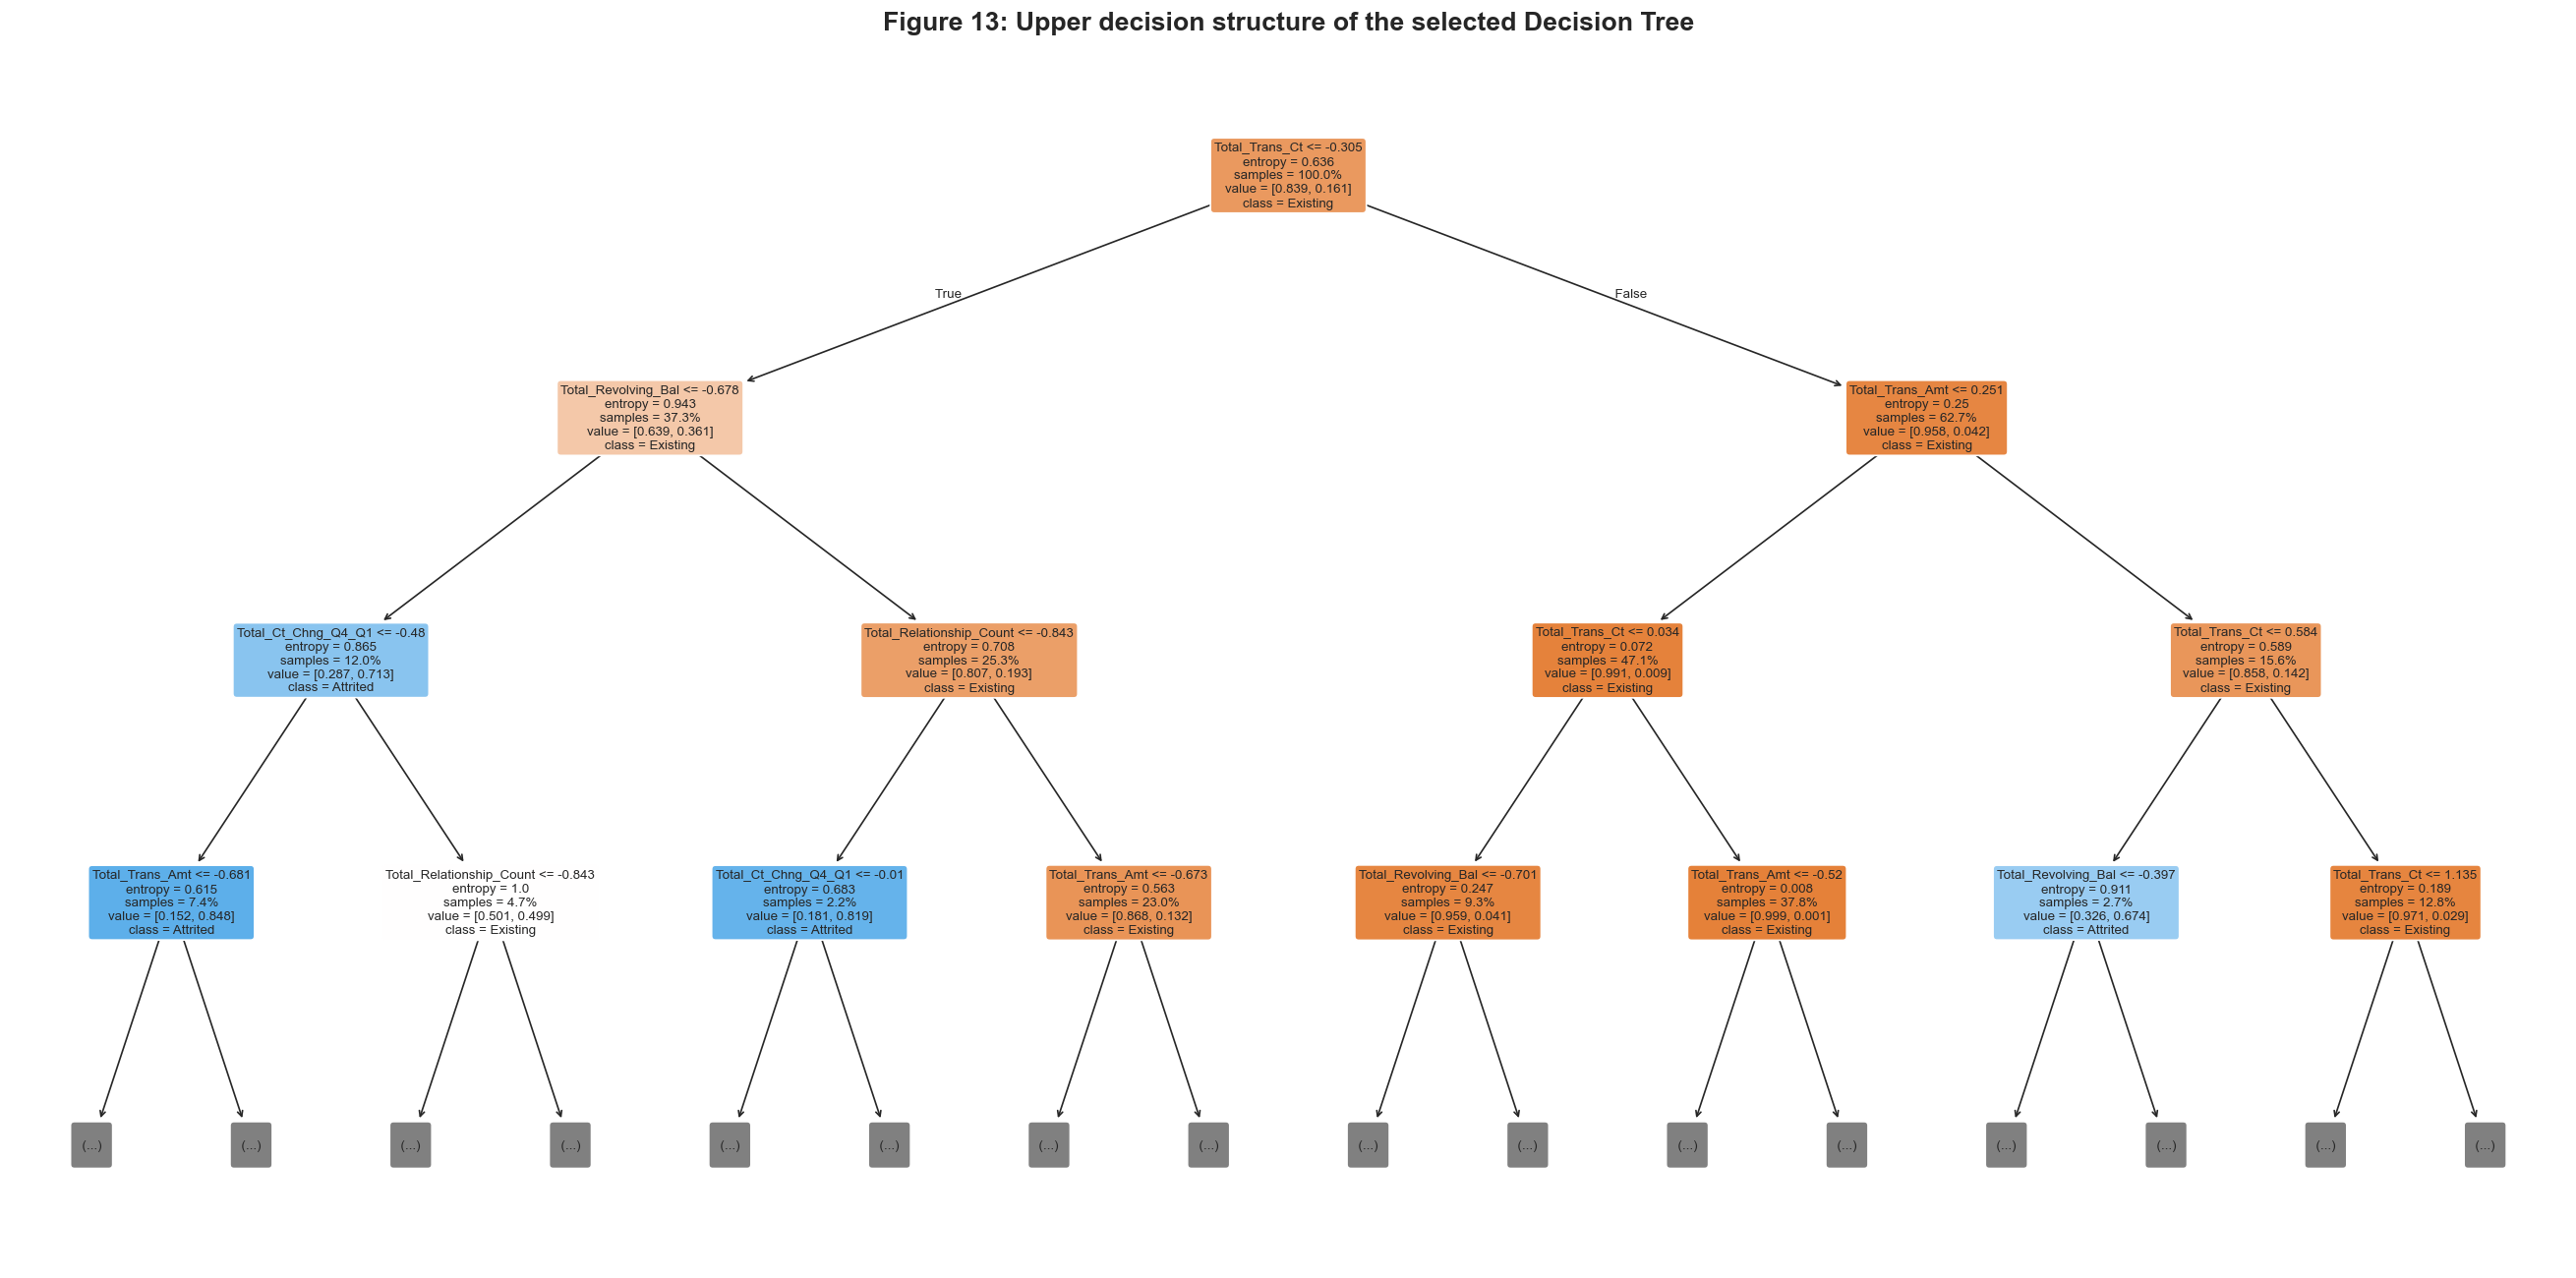

In [80]:
# Extract the fitted Decision Tree pipeline components
from sklearn.tree import plot_tree
decision_tree_pipeline = selected_models[
    "Decision Tree"
]

decision_tree_preprocessor = (
    decision_tree_pipeline
    .named_steps["preprocessor"]
)

decision_tree_classifier = (
    decision_tree_pipeline
    .named_steps["classifier"]
)

# Obtain and clean transformed feature names
tree_feature_names = (
    decision_tree_preprocessor
    .get_feature_names_out()
)

tree_display_feature_names = np.array([
    feature_name
    .replace("num__", "")
    .replace("cat__", "")
    for feature_name in tree_feature_names
])

# Confirm alignment between transformed features and tree inputs
assert (
    len(tree_display_feature_names)
    == decision_tree_classifier.n_features_in_
), (
    "The number of transformed feature names does not "
    "match the number of features used by the fitted tree."
)

# Assign labels in the classifier's fitted class order
tree_class_label_lookup = {
    0: "Existing",
    1: "Attrited"
}

tree_class_names = [
    tree_class_label_lookup.get(
        class_value,
        str(class_value)
    )
    for class_value in decision_tree_classifier.classes_
]

# Plot only the upper four levels for readability
fig, ax = plt.subplots(
    figsize=(22, 11)
)

plot_tree(
    decision_tree_classifier,
    feature_names=tree_display_feature_names,
    class_names=tree_class_names,
    filled=True,
    rounded=True,
    proportion=True,
    max_depth=3,
    fontsize=8,
    ax=ax
)

ax.set_title(
    "Figure 13: Upper decision structure of the selected Decision Tree",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.tight_layout()

plt.savefig(
    "figure_13_decision_tree_upper_structure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.4 Predictive performance–interpretability balance

The comparison demonstrates that fitted complexity, complete-model understandability and individual-prediction traceability are related but not interchangeable. L2 Logistic Regression provides one additive coefficient system, and an individual prediction can be decomposed into its coefficient contributions. Nevertheless, understanding all 32 transformed terms requires knowledge of numerical standardisation, categorical reference groups and log-odds interpretation.

Main-effects LASSO produced the most compact linear specification by retaining 17 of 32 candidate terms and eliminating 15, corresponding to sparsity of 46.88%. Its reduced additive structure supports both complete-model inspection and customer-level prediction decomposition. However, this structural simplicity was accompanied by substantially weaker predictive performance than the tree-based models and Expanded LASSO. Sparsity should also not be interpreted as evidence that excluded terms have no relationship with attrition, particularly where predictors contain overlapping information.

Expanded LASSO achieved considerably stronger predictive performance than the main-effects linear models by allowing squared and pairwise interaction terms. However, it retained 101 of 137 candidate terms, including numerous interactions and squared terms. Consequently, L1 regularisation did not make this specification straightforward to understand in full. Although an individual prediction could theoretically be decomposed across its retained terms, interpreting such a decomposition would be considerably more difficult than interpreting the main-effects coefficient models.

The selected Decision Tree provides the clearest direct customer-level traceability because an individual prediction can be followed through one sequence of decision rules. Its complete fitted structure, however, contains substantially more rules than can be communicated through the upper-tree visualisation in Figure 13. The figure therefore supports partial inspection of the most prominent early splits but should not be treated as a representation of the entire fitted model.

Random Forest achieved the strongest held-out predictive performance. It produced the highest average precision and ROC-AUC and, at the common 0.50 threshold, achieved the best precision, recall and F1-score for attrited customers among the evaluated specifications. Its fitted structure is nevertheless the least directly understandable because each prediction aggregates decisions across 300 trees rather than following one global decision path. Permutation importance provides a useful post-hoc summary of global predictor reliance, identifying total transaction count and total transaction amount as the dominant predictors, but it does not make the forest’s complete internal structure transparent.

No specification therefore provides an unconditionally optimal performance–interpretability balance. Random Forest is the preferred predictive candidate when reliable churn identification is prioritised, provided that its deployment is accompanied by appropriate explanation, validation, performance monitoring and governance. Where complete structural inspection and direct coefficient-based explanation are mandatory, main-effects LASSO offers the most compact alternative, although its lower predictive performance must be acknowledged. Decision Tree provides an intermediate option when direct customer-level rule tracing is particularly valuable, while Expanded LASSO illustrates that stronger predictive performance within a linear modelling framework can substantially reduce practical understandability.


## 10. Probability Calibration

Discrimination and calibration describe different aspects of predictive performance. ROC-AUC and average precision evaluate how effectively a model ranks attrited customers above existing customers, whereas calibration evaluates whether its predicted probabilities correspond to observed attrition frequencies. A model may therefore distinguish the two classes successfully while producing probability estimates that systematically overstate or understate attrition risk.

Calibration is particularly important when predicted probabilities are used to segment customers, prioritise retention activity or allocate limited intervention resources. If a predicted probability of 0.30 is interpreted as an estimated 30% attrition risk, similarly scored customers should exhibit an observed attrition frequency close to that value. Poorly calibrated probabilities should instead be treated primarily as relative risk scores unless recalibration is performed and validated.

Calibration is assessed visually using calibration curves and numerically using the Brier score and log loss. The calibration curve compares mean predicted probabilities with observed attrition frequencies across probability groups; closer agreement with the 45-degree reference line indicates better calibration. The Brier score measures the mean squared difference between predicted probabilities and observed binary outcomes, with lower values indicating more accurate probability estimates. Log loss also evaluates probability quality but penalises confident incorrect predictions more strongly.

These measures are interpreted alongside discrimination rather than as substitutes for it. Both the Brier score and log loss depend partly on outcome prevalence, and visual calibration estimates can be unstable in probability ranges containing few observations. The results therefore describe probability quality on the present held-out test sample and do not establish that calibration will remain unchanged across other customer populations or future periods.


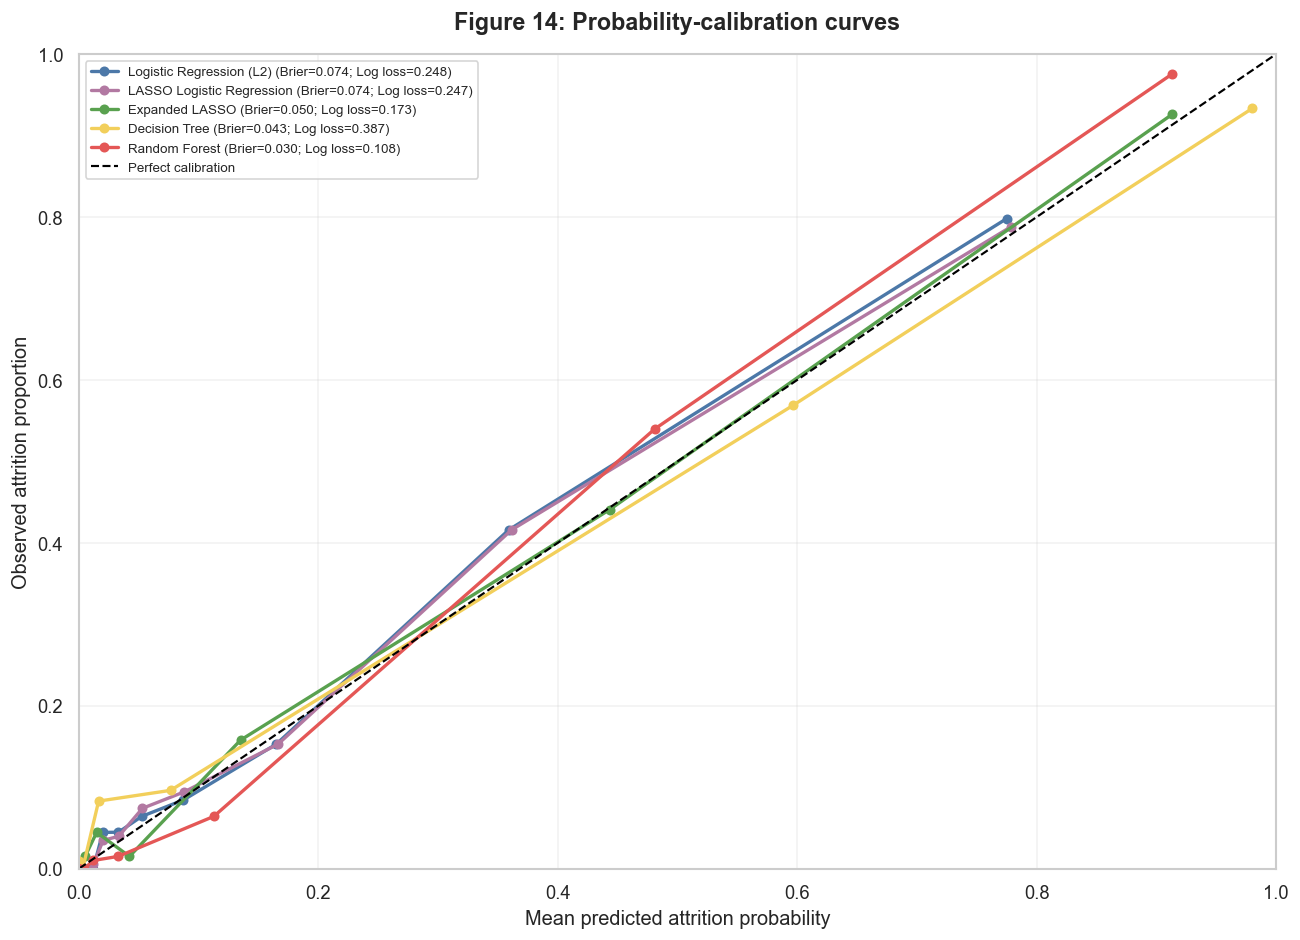

,Model,Brier_Score,Log_Loss
0,Random Forest,0.030,0.108
1,Decision Tree,0.043,0.387
2,Expanded LASSO,0.050,0.173
3,LASSO Logistic Regression,0.074,0.247
4,Logistic Regression (L2),0.074,0.248


Probability-calibration figure and results saved successfully.


In [81]:
from sklearn.metrics import (
    brier_score_loss,
    log_loss
)
from sklearn.calibration import calibration_curve

CALIBRATION_BINS = 10

calibration_records = []

fig, ax = plt.subplots(
    figsize=(11, 8)
)

for model_name in selected_models:
    predicted_probability = np.asarray(
        test_predictions[
            model_name
        ]["Predicted_Probability"]
    )

    brier_score = brier_score_loss(
        y_test,
        predicted_probability
    )

    model_log_loss = log_loss(
        y_test,
        predicted_probability,
        labels=[0, 1]
    )

    calibration_records.append({
        "Model": model_name,
        "Brier_Score": brier_score,
        "Log_Loss": model_log_loss
    })

    observed_fraction, mean_probability = (
        calibration_curve(
            y_test,
            predicted_probability,
            n_bins=CALIBRATION_BINS,
            strategy="quantile"
        )
    )

    ax.plot(
        mean_probability,
        observed_fraction,
        marker="o",
        markersize=5,
        linewidth=2,
        color=model_colours[model_name],
        label=(
            f"{model_name} "
            f"(Brier={brier_score:.3f}; "
            f"Log loss={model_log_loss:.3f})"
        )
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.3,
    label="Perfect calibration"
)

ax.set_title(
    "Figure 14: Probability-calibration curves",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Mean predicted attrition probability"
)

ax.set_ylabel(
    "Observed attrition proportion"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(
    fontsize=8,
    loc="upper left"
)
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "figure_14_probability_calibration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

calibration_results = (
    pd.DataFrame(calibration_records)
    .sort_values(
        [
            "Brier_Score",
            "Log_Loss"
        ],
        ascending=True
    )
    .reset_index(drop=True)
)

calibration_results[
    [
        "Brier_Score",
        "Log_Loss"
    ]
] = calibration_results[
    [
        "Brier_Score",
        "Log_Loss"
    ]
].round(4)

display(calibration_results)

calibration_results.to_csv(
    "table_probability_calibration_results.csv",
    index=False
)

print(
    "Probability-calibration figure and results "
    "saved successfully."
)

### 10.1 Calibration interpretation

The calibration analysis complements the discrimination and threshold-based classification results by evaluating the quality of the predicted probabilities. Lower Brier scores indicate smaller mean squared differences between predicted probabilities and observed outcomes, while lower log-loss values indicate better probability quality with a stronger penalty for confident incorrect predictions. These metrics should be interpreted together because they capture related but not identical aspects of probabilistic performance.

In Figure 14, the diagonal reference line represents perfect calibration. Points above the diagonal indicate underprediction, meaning that the observed attrition proportion was higher than the mean predicted probability within that probability group. Points below the diagonal indicate overprediction of attrition risk. Because the curves use ten quantile-based bins, each bin contains a broadly similar number of observations, although the number of distinct plotted points may be smaller where predicted probabilities are repeated.

The models and their hyperparameters were selected using cross-validated discrimination measures rather than a calibration-specific objective. Calibration results from the held-out test sample are therefore used as an additional evaluation and did not influence model selection. A model with strong average precision or ROC-AUC should not automatically be assumed to produce probabilities that can be interpreted as exact customer-level attrition risks.

The curves should also be interpreted cautiously at the extremes of the probability range, where estimates may be influenced by limited observations and binning choices. The Brier score and log loss provide overall summaries but do not reveal where overprediction or underprediction occurs. Consequently, conclusions should be based on the numerical metrics and the visual calibration patterns together.

If a selected model were deployed for probability-based customer segmentation or financial decision-making, its calibration should be reassessed using independent and preferably temporally later data. Any recalibration procedure would need to be fitted on separate calibration data and evaluated on untouched observations to avoid optimistic estimates. Continued monitoring would also be necessary because probability calibration may deteriorate when customer behaviour, attrition prevalence or banking practices change.


## 11. Business Implications and Customer-Retention Recommendations

The findings provide evidence-informed directions for customer-retention management. However, they are derived from a secondary, cross-sectional dataset whose documentation does not establish precisely when each predictor was measured relative to attrition. The recommendations should therefore be treated as candidates for prospective validation rather than immediate causal prescriptions.

### 11.1 Validate transaction activity as a prospective risk signal

Total transaction count and total transaction amount were the two most influential Random Forest predictors under both average-precision and ROC-AUC permutation importance. This indicates that the fitted model relied strongly on transaction activity when distinguishing attrited from existing customers.

A bank could investigate whether sustained reductions in transaction frequency or value provide useful prospective warning signals. This would require time-stamped longitudinal data and a clearly defined prediction window—for example, using activity observed during one period to predict attrition during a later period. Monitoring sustained changes may be more informative than reacting to isolated fluctuations, but the appropriate duration and magnitude of change would need to be established empirically.

The present analysis does not demonstrate that these variables precede attrition or that increasing transaction activity would prevent churn. They should therefore be interpreted as retrospective classification indicators until validated in a temporally ordered design.

### 11.2 Incorporate relationship depth into risk assessment

Total relationship count ranked third in the Random Forest permutation analysis, indicating that the number of products held contributed additional predictive information. Banks could examine whether customers with relatively limited product relationships exhibit different disengagement patterns and whether this information improves risk segmentation when combined with transaction behaviour.

This finding does not justify automatic cross-selling. Any product recommendation should remain appropriate to the customer’s needs, circumstances, affordability and eligibility and should comply with applicable consumer-protection and conduct requirements. Relationship count should support analytical assessment rather than become an isolated intervention rule.

### 11.3 Use risk scores to prioritise proportionate interventions

Random Forest achieved the strongest held-out results across discrimination, probability quality and default-threshold classification measures. At the common threshold of 0.50, it produced the highest attrited-customer precision, recall and F1-score among the evaluated specifications. It therefore represents the strongest candidate for prioritising customers for further review within the present analytical comparison.

The threshold of 0.50 was retained for consistent model evaluation and should not be interpreted as economically optimal. An operational threshold should reflect customer lifetime value, intervention cost, available staff capacity, expected offer acceptance, the cost of missed attrition and the potential harm of unnecessary contact. Different intervention tiers could also use different thresholds: low-cost communications may support a broader risk group, whereas expensive incentives may require a smaller group with higher predicted risk.

### 11.4 Match interventions to customer circumstances

A risk classification should trigger further assessment rather than an automatic retention offer. Transaction inactivity may reflect temporary circumstances, deliberate changes in spending behaviour, financial difficulty or movement to another provider. Retention teams should therefore combine model outputs with relevant customer context and use proportionate interventions, such as service checks, channel-support communications or appropriately governed product reviews.

Intervention effectiveness should be evaluated using controlled prospective testing where feasible. Predictive accuracy alone cannot establish whether a retention action changes customer behaviour. Randomised or carefully designed quasi-experimental evaluation would be required to estimate the incremental effect of an intervention.

### 11.5 Maintain human oversight and appropriate explanation

Model predictions should support rather than replace accountable human judgement in consequential customer decisions. Permutation importance provides a global explanation of the predictors on which a fitted model relies, but it does not explain the complete reasoning behind an individual Random Forest prediction.

If customer-level explanations are required, an appropriate local explanation method would need to be selected, validated and communicated carefully. Such explanations should not be presented as causal accounts, and staff should be able to question or override model recommendations when additional information indicates that an intervention would be inappropriate.

### 11.6 Establish monitoring and governance controls

Before deployment, the model should be validated on independent and preferably temporally later data. Operational monitoring should cover changes in predictor distributions, attrition prevalence, average precision, ROC-AUC, calibration, threshold-based error rates and intervention outcomes. Monitoring should also examine performance across relevant customer groups to identify materially unequal error patterns or unintended impacts.

Retraining should be triggered by evidence of meaningful degradation, changes in customer behaviour or material changes to products and business processes rather than by an arbitrary schedule alone. Model versions, data definitions, thresholds, overrides and retention outcomes should be documented to support accountability and auditability. Because this study uses one secondary dataset, external and temporal validation are necessary before the model can be considered ready for operational banking use.


## 12. Answers to the Research Questions

### RQ1: What customer characteristics are the strongest predictors of customer churn?

Permutation importance identified total transaction count and total transaction amount as the two strongest original predictors in the selected Random Forest under both average precision and ROC-AUC. Total relationship count ranked third, followed by total revolving balance and changes in transaction activity. The substantially larger permutation effects associated with transaction count and transaction amount indicate that the fitted model relied primarily on behavioural engagement measures when distinguishing attrited from existing customers.

Most demographic and account characteristics produced considerably smaller permutation effects. However, this does not demonstrate that those variables are unrelated to attrition because correlated predictors can divide or conceal importance. More importantly, the dataset does not establish precisely when the predictors were recorded relative to attrition. The identified variables should therefore be interpreted as retrospective predictive indicators rather than verified prospective warning signals or causal determinants of churn.

### RQ2: How do the four model families compare in predicting customer churn?

The four model families were represented by five fitted specifications: L2 Logistic Regression, main-effects LASSO Logistic Regression, Expanded LASSO, Decision Tree and Random Forest. Random Forest achieved the strongest held-out performance. It produced a ROC-AUC of 0.988, average precision of 0.950, Brier score of 0.030 and log loss of 0.108. At the common threshold of 0.50, it also achieved the highest accuracy, balanced accuracy, attrited-customer precision, recall and F1-score among the evaluated specifications, with 22 false positives and 52 false negatives.

Expanded LASSO and Decision Tree produced almost identical ranking performance. Their respective ROC-AUC values were 0.961 and 0.960, while their average-precision values were 0.867 and 0.865. Their threshold-based profiles differed more clearly: Decision Tree achieved attrited-customer recall of 0.822 and produced 55 false positives and 58 false negatives, whereas Expanded LASSO achieved recall of 0.705 and generated 43 false positives. Their very small ranking differences should not be treated as practically meaningful without considering the paired-bootstrap uncertainty intervals.

The main-effects LASSO and L2 Logistic Regression produced weaker discrimination than Expanded LASSO and the tree-based models. Contrary to the earlier results, the revised unweighted linear specifications did not detect more attrited customers than Random Forest at the 0.50 threshold. Random Forest therefore did not obtain higher precision by sacrificing recall; it provided the strongest observed combination of ranking, probability quality and default-threshold classification performance.

### RQ3: Which model provides the best balance between predictive performance and interpretability?

No specification provides a universally optimal balance because fitted complexity, complete-model understandability and individual-prediction traceability represent different aspects of interpretability. Main-effects LASSO produced the most compact coefficient-based specification, retaining 17 of 32 candidate terms and eliminating 46.88%. It supports complete coefficient inspection and direct additive decomposition of an individual prediction, but its predictive performance was substantially weaker than that of Random Forest.

Expanded LASSO achieved stronger predictive performance but retained 101 of 137 candidate terms, including numerous interactions and squared terms. Its use of L1 regularisation therefore did not result in a practically simple complete model. Decision Tree provides the clearest individual-level rule traceability because one prediction can be followed through a single decision path, although its complete fitted structure contains too many rules to be represented by the upper-tree visualisation alone.

Random Forest has the lowest direct structural transparency because each prediction aggregates 300 trees. Nevertheless, it achieved the strongest predictive performance and provided a useful post-hoc global explanation through permutation importance. It therefore offers the most favourable balance when predictive quality and global predictor insight are prioritised. Main-effects LASSO is the more defensible alternative when complete coefficient-based inspection is mandatory, while Decision Tree is relevant when direct customer-level rule tracing is particularly important.

### RQ4: How can the findings support customer-retention strategies?

The results suggest that transaction activity and relationship depth are useful candidates for further development of customer-risk assessment. A bank could test whether sustained changes in transaction frequency and value predict subsequent attrition using time-stamped longitudinal data. Relationship count could provide additional segmentation information, although it should not be used to justify automatic or unsuitable cross-selling.

Random Forest could support prioritised retention review, subject to external and temporal validation. The operational classification threshold should reflect customer lifetime value, intervention costs, retention capacity, offer effectiveness and the relative consequences of false positives and false negatives rather than being adopted automatically at 0.50. Risk classifications should support proportionate human review rather than trigger consequential actions without additional customer context.

Deployment would also require probability-calibration assessment, customer-level explanation where appropriate, performance and data-drift monitoring, subgroup error analysis and documented governance procedures. Because the present analysis is observational and based on one secondary dataset, any proposed retention intervention should be evaluated prospectively—preferably through controlled testing—before its effectiveness or financial value is assumed.


## 13. Limitations

The findings should be interpreted in light of several data, modelling and evaluation limitations.

1. **Uncertain dataset provenance:** The analysis used a publicly available secondary dataset commonly presented as representing credit-card customers from one banking institution. However, the original sampling procedure, collection period, attrition definition, institutional setting and data-quality controls could not be independently verified. The observations cannot therefore be assumed to represent the wider banking population.

2. **Absence of longitudinal information:** The dataset contains aggregated customer characteristics rather than time-stamped transaction histories. It does not establish precisely when each predictor was measured relative to the recorded attrition outcome. Consequently, the study cannot determine the timing or sequence of behavioural changes preceding attrition, and the leading predictors should not yet be treated as validated prospective early-warning signals.

3. **Predictive rather than causal analysis:** The observed relationships describe statistical patterns used by the fitted models. Coefficients, tree splits and permutation importance do not establish that a predictor causes attrition or that changing it would improve retention. Intervention effectiveness would require an experimental or credible quasi-experimental research design.

4. **Internal rather than external validation:** Performance was evaluated using one stratified random test partition drawn from the same dataset as the training observations. Although model development was restricted to the training data, the test results do not demonstrate generalisation to another institution, geographical setting or future customer population. Independent and temporally later validation would be required before operational use.

5. **Uncertainty limited to the present test sample:** Paired-bootstrap intervals quantify uncertainty arising from resampling the held-out observations, but they do not capture uncertainty caused by institutional differences, temporal change, alternative data definitions or repeated train–test partitions. Small observed differences between models should therefore not be interpreted as universal performance rankings.

6. **Treatment of `Unknown` categories:** Missing values in education, marital status and income category were encoded as explicit `Unknown` levels to preserve observations and allow missingness to carry predictive information. However, the reasons for missingness were unavailable. The resulting effects may represent data-collection processes rather than meaningful customer characteristics.

7. **Threshold not financially optimised:** The common threshold of 0.50 was retained to compare model classifications consistently. It was not selected using customer lifetime value, intervention costs, retention capacity, offer acceptance or the relative cost of missed and unnecessary interventions. The reported confusion matrices therefore describe one comparison point rather than an economically optimal operating policy.

8. **Limits of permutation importance:** Permutation importance measures global predictive reliance on the present test data rather than causal influence or the direction of association. Correlated predictors can share or conceal importance, and repeated permutation results remain sensitive to the fitted model and evaluation sample. The method also does not provide a complete explanation of individual Random Forest predictions.

9. **Restricted model and hyperparameter scope:** The comparison deliberately focused on Logistic Regression, LASSO, Decision Tree and Random Forest to maintain alignment with the research objectives and support interpretable comparison. Hyperparameter searches were limited to predefined candidate grids. Alternative preprocessing choices, wider search spaces or other algorithms could produce different results, although adding complexity would not necessarily improve generalisability or managerial usefulness.

10. **Limited calibration evidence:** Calibration was evaluated on the held-out test sample using quantile-binned curves, Brier score and log loss. The models were not recalibrated using a separate temporal calibration sample. Probability estimates should therefore not be assumed to remain reliable in another population or period without independent calibration assessment and continued monitoring.

11. **No comprehensive fairness assessment:** The study did not conduct a complete subgroup error or algorithmic-fairness analysis. Descriptive attrition rates were compared across available demographic categories, but these comparisons do not establish whether model error rates or operational impacts differ across protected or commercially sensitive groups. A deployment assessment would require institution-specific protected-characteristic data, sufficiently large subgroup samples, appropriate fairness criteria and consideration of how predictions influence actual customer treatment.

12. **No evaluation of intervention outcomes:** The study assesses prediction but does not observe whether retention contact changes customer behaviour, generates financial value or creates unintended effects such as excessive or inappropriate targeting. Prospective controlled evaluation would be necessary before translating predictive performance into claims about business effectiveness.


## 14. Reproducibility and Final Summary

The notebook records the principal software and package versions used for the analysis and applies a fixed random seed to reproducible procedures, including the train–test split, cross-validation, model fitting and permutation importance. Preprocessing and modelling steps are implemented through fitted pipelines to ensure that transformations estimated from the training data are applied consistently to validation and test observations.

Performance metrics, confusion-matrix counts, calibration measures, coefficient summaries, fitted-model complexity measures and permutation-importance rankings are calculated programmatically from the fitted models and their predictions. Key tables and figures are exported directly from these results to reduce transcription errors. The accompanying narrative conclusions are manually interpreted from the generated outputs and should therefore be checked against the final executed notebook.

Reproduction requires access to the same dataset, target encoding, predictor definitions, software versions and random-state settings. The notebook should be executed sequentially from a restarted kernel because later cells depend on objects created earlier. Exact results may differ if package versions, numerical libraries, dataset contents or computational environments change. The recorded environment and exported outputs improve computational transparency but do not overcome the dataset’s uncertain provenance or provide external validation.

Overall, the analysis found that Random Forest offered the strongest predictive performance among the evaluated specifications, while main-effects LASSO provided the most compact coefficient-based representation and Decision Tree provided direct tracing of individual decision paths. Transaction count and transaction amount were the dominant Random Forest predictors, but their importance represents retrospective predictive reliance rather than verified causal or prospective early-warning effects. The findings therefore support further development and validation of risk-based retention analysis while emphasising the need for temporal validation, threshold optimisation, calibration assessment, appropriate explanation, human oversight and governance before operational deployment.


In [82]:
import sklearn
import matplotlib
import seaborn
import platform

software_versions = pd.DataFrame({
    "Component": [
        "Python",
        "pandas",
        "NumPy",
        "scikit-learn",
        "Matplotlib",
        "Seaborn"
    ],
    "Version": [
        platform.python_version(),
        pd.__version__,
        np.__version__,
        sklearn.__version__,
        matplotlib.__version__,
        seaborn.__version__
    ]
})

display(software_versions)

software_versions.to_csv(
    "table_software_versions.csv",
    index=False
)

,Component,Version
0,Python,3.13.9
1,pandas,2.3.3
2,NumPy,2.3.5
3,scikit-learn,1.7.2
4,Matplotlib,3.10.6
5,Seaborn,0.13.2


In [83]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Identify the strongest model on the held-out test sample
best_model_result = (
    test_results
    .sort_values(
        [
            "Average_Precision",
            "ROC_AUC"
        ],
        ascending=[False, False]
    )
    .iloc[0]
)

best_model_name = (
    best_model_result["Model"]
)

# Retrieve predicted probabilities
best_model_probability = np.asarray(
    test_predictions[
        best_model_name
    ]["Predicted_Probability"]
)

# Apply the common classification threshold
best_model_prediction = (
    best_model_probability >= 0.50
).astype(int)

# Calculate threshold-based metrics directly
best_model_precision = precision_score(
    y_test,
    best_model_prediction,
    zero_division=0
)

best_model_recall = recall_score(
    y_test,
    best_model_prediction,
    zero_division=0
)

best_model_f1 = f1_score(
    y_test,
    best_model_prediction,
    zero_division=0
)

# Retrieve calibration results
best_model_calibration = (
    calibration_results
    .loc[
        calibration_results["Model"]
        == best_model_name
    ]
    .iloc[0]
)

# Extract the five leading Random Forest predictors
top_random_forest_features = (
    permutation_importance_tables[
        "Random Forest"
    ]
    .nlargest(
        5,
        "Mean_Average_Precision_Decrease"
    )[
        [
            "Feature",
            "Mean_Average_Precision_Decrease",
            "Mean_ROC_AUC_Decrease",
            "Average_Precision_Rank",
            "ROC_AUC_Rank"
        ]
    ]
    .reset_index(drop=True)
)

print("=" * 72)
print("FINAL ANALYTICAL SUMMARY")
print("=" * 72)

print(
    f"Analytical sample: "
    f"{len(df):,} customers"
)

print(
    f"Original predictors: "
    f"{X.shape[1]}"
)

print(
    f"Observed attrition rate: "
    f"{y.mean() * 100:.2f}%"
)

print(
    f"\nStrongest model on the held-out test sample: "
    f"{best_model_name}"
)

print(
    f"Test average precision: "
    f"{best_model_result['Average_Precision']:.4f}"
)

print(
    f"Test ROC-AUC: "
    f"{best_model_result['ROC_AUC']:.4f}"
)

print(
    f"Test F1-score at threshold 0.50: "
    f"{best_model_f1:.4f}"
)

print(
    f"Test attrited-customer precision at threshold 0.50: "
    f"{best_model_precision:.4f}"
)

print(
    f"Test attrited-customer recall at threshold 0.50: "
    f"{best_model_recall:.4f}"
)

print(
    f"Test Brier score: "
    f"{best_model_calibration['Brier_Score']:.4f}"
)

print(
    f"Test log loss: "
    f"{best_model_calibration['Log_Loss']:.4f}"
)

print(
    "\nTop five Random Forest predictors "
    "by average-precision permutation importance:"
)

display(top_random_forest_features)

print(
    "\nImportant: the numerical results above are "
    "retrieved or calculated programmatically from "
    "the executed evaluation outputs."
)

print(
    "They describe performance on the present held-out "
    "sample and do not constitute external or temporal "
    "validation."
)

FINAL ANALYTICAL SUMMARY
Analytical sample: 10,127 customers
Original predictors: 19
Observed attrition rate: 16.07%

Strongest model on the held-out test sample: Random Forest
Test average precision: 0.9504
Test ROC-AUC: 0.9878
Test F1-score at threshold 0.50: 0.8806
Test attrited-customer precision at threshold 0.50: 0.9254
Test attrited-customer recall at threshold 0.50: 0.8400
Test Brier score: 0.0302
Test log loss: 0.1076

Top five Random Forest predictors by average-precision permutation importance:


,Feature,Mean_Average_Precision_Decrease,Mean_ROC_AUC_Decrease,Average_Precision_Rank,ROC_AUC_Rank
0,Total_Trans_Ct,0.486,0.190,1,1
1,Total_Trans_Amt,0.295,0.111,2,2
2,Total_Relationship_Count,0.084,0.017,3,3
3,Total_Revolving_Bal,0.060,0.017,4,4
4,Total_Ct_Chng_Q4_Q1,0.036,0.011,5,5



Important: the numerical results above are retrieved or calculated programmatically from the executed evaluation outputs.
They describe performance on the present held-out sample and do not constitute external or temporal validation.


## 15. Final Analytical Conclusion

This study compared five fitted specifications across four model families for classifying attrition among 10,127 banking credit-card customers. The results demonstrate that demographic, relationship, credit and transactional information can distinguish attrited from existing customers within the present dataset, although performance varied substantially across the evaluated approaches.

Random Forest achieved the strongest held-out results across discrimination, probability quality and classification performance at the common threshold of 0.50. It produced the highest average precision, ROC-AUC, attrited-customer precision, recall and F1-score, together with the lowest Brier score and log loss. The revised unweighted linear specifications did not achieve higher recall than Random Forest. Expanded LASSO and Decision Tree provided the closest ranking performance after Random Forest, although their threshold-based error profiles differed.

Total transaction count and total transaction amount were the dominant Random Forest predictors under both average-precision and ROC-AUC permutation importance, followed by total relationship count. These findings demonstrate strong retrospective predictive reliance on transaction activity and relationship depth. However, the cross-sectional dataset does not establish whether changes in these variables occurred before attrition. Their use as prospective early-warning indicators would therefore require validation using time-stamped longitudinal data.

The comparison further shows that predictive performance, fitted complexity and interpretability are not interchangeable. Main-effects LASSO produced the most compact coefficient-based specification, while Decision Tree enabled direct tracing of an individual prediction through one rule path. Expanded LASSO achieved stronger prediction than the main-effects linear models but retained a large system of polynomial and interaction terms. Random Forest provided the strongest prediction and useful global post-hoc explanation, although its complete ensemble structure and individual predictions were not directly transparent.

Within the scope of this study, Random Forest is the strongest predictive candidate when classification quality is prioritised and suitable explanation and governance controls are available. Main-effects LASSO represents a more compact alternative where complete coefficient inspection is mandatory, while Decision Tree may be valuable when direct customer-level rule tracing is required. The final choice would depend on the bank’s operational objectives, intervention costs, explanation requirements, risk tolerance and governance obligations.

The findings provide an internally validated empirical basis for the dissertation’s discussion and recommendations, but they do not establish deployment readiness. External and temporal validation, financially informed threshold selection, independent calibration assessment, customer-level explanation where appropriate, subgroup evaluation and controlled intervention testing would be required before the model could support operational customer-retention decisions.


In [84]:
total_customers = len(df_raw)
churned_customers = df_raw["Attrition_Flag"].eq("Attrited Customer").sum()

churn_overview = pd.DataFrame({
    "Total Customers": [total_customers],
    "Churned Customers": [churned_customers],
    "Churn Rate": [churned_customers / total_customers],
})

churn_overview.to_csv("churn-overview.csv", index=False)
display(churn_overview)

,Total Customers,Churned Customers,Churn Rate
0,10127,1627,0.161


In [85]:
transaction_data = df_raw[["Total_Trans_Ct", "Attrition_Flag"]].copy()

transaction_data["Transaction Count Band"] = pd.cut(
    transaction_data["Total_Trans_Ct"],
    bins=[0, 40, 60, 80, 100, float("inf")],
    labels=["0–40", "41–60", "61–80", "81–100", "101+"],
    include_lowest=True,
)

transaction_data["Churned"] = transaction_data["Attrition_Flag"].eq(
    "Attrited Customer"
)

transaction_summary = (
    transaction_data.groupby("Transaction Count Band", observed=True)
    .agg(
        total_customers=("Churned", "size"),
        churned_customers=("Churned", "sum"),
    )
    .reset_index()
)

transaction_summary["churn_rate"] = (
    transaction_summary["churned_customers"]
    / transaction_summary["total_customers"]
)

transaction_summary.to_csv("transaction-count-churn.csv", index=False)
display(transaction_summary)

print("Total customers:", transaction_summary["total_customers"].sum())
print("Churned customers:", transaction_summary["churned_customers"].sum())

,Transaction Count Band,total_customers,churned_customers,churn_rate
0,0–40,1938,611,0.315
1,41–60,2109,780,0.370
2,61–80,3530,205,0.058
3,81–100,1901,31,0.016
4,101+,649,0,0.000


Total customers: 10127
Churned customers: 1627


In [86]:
test_results.to_csv("model-performance.csv", index=False)
display(test_results)

,Model,Average_Precision_Rank,Accuracy,Balanced_Accuracy,Attrited_Customer_Precision,Attrited_Customer_Recall,Specificity,Attrited_Customer_F1,ROC_AUC,Average_Precision,Trapezoidal_PR_AUC,Brier_Score,Log_Loss,True_Negatives,False_Positives,False_Negatives,True_Positives,Predicted_Attrited_Customers,False_Positive_Rate,False_Negative_Rate
0,Random Forest,1,0.964,0.913,0.925,0.840,0.987,0.881,0.988,0.950,0.950,0.030,0.108,1679,22,52,273,295,0.013,0.160
1,Expanded LASSO,2,0.931,0.840,0.842,0.705,0.975,0.767,0.961,0.867,0.867,0.050,0.173,1658,43,96,229,272,0.025,0.295
2,Decision Tree,3,0.944,0.895,0.829,0.822,0.968,0.825,0.960,0.865,0.876,0.043,0.387,1646,55,58,267,322,0.032,0.178
3,Logistic Regression (L2),4,0.900,0.748,0.783,0.523,0.972,0.627,0.914,0.734,0.733,0.074,0.248,1654,47,155,170,217,0.028,0.477
4,LASSO Logistic Regression,5,0.900,0.745,0.785,0.517,0.973,0.623,0.915,0.733,0.733,0.074,0.247,1655,46,157,168,214,0.027,0.483
